# KSH területi átlagbérek gépi tanulási előrejelzése

A notebook célja Budapest és a 19 vármegye következő negyedévi
bruttó átlagkeresetének előrejelzése a 2018–2025 közötti
negyedéves paneladatok alapján.

Az előrejelzési feladat egy negyedévvel előre történő, one-step-ahead
becslés. Egy adott célnegyedév előrejelzésekor kizárólag az azt
megelőző időpontokban rendelkezésre álló adatok használhatók fel.

A modellek értékelése időrendi, expanding-window walk-forward
validációval történik. A 2021–2023 közötti célnegyedévek szolgálnak
a modell- és hiperparaméter-választásra. A 2024–2025 közötti
időszak végső tesztidőszak, amelyet csak a modellezési döntések
rögzítése után értékelünk.

A gépi tanulási modellek teljesítményét előző negyedéves és
előző évi szezonális naiv előrejelzésekkel hasonlítjuk össze.
Véletlenszerű tanító–teszt felosztást az idősoros szerkezet miatt
nem alkalmazunk.

In [115]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

BASE_DIR = Path.cwd()

PROCESSED = (BASE_DIR/ "processed")
ML_RESULTS = (BASE_DIR/ "results"/ "machine_learning")
ML_FIGURES = (BASE_DIR/ "figures"/ "machine_learning")

ML_RESULTS.mkdir(parents=True,exist_ok=True)
ML_FIGURES.mkdir(parents=True,exist_ok=True)
PANEL_FILE = (PROCESSED/ "KSH_Panel_FINAL_2018_2025.csv")

if not PANEL_FILE.exists():

    raise FileNotFoundError(
        "Nem található a végleges paneladatbázis: "
        f"{PANEL_FILE}"
    )

sns.set_theme(
    style="whitegrid"
)

plt.rcParams[
    "figure.figsize"
] = (12, 7)


print(
    "Paneladatbázis:",
    PANEL_FILE
)

print(
    "ML-eredmények helye:",
    ML_RESULTS
)

print(
    "ML-ábrák helye:",
    ML_FIGURES
)

Paneladatbázis: c:\Users\wldbe\Downloads\szakdolgozat12-20260820T154901Z-1-001\szakdolgozat12\processed\KSH_Panel_FINAL_2018_2025.csv
ML-eredmények helye: c:\Users\wldbe\Downloads\szakdolgozat12-20260820T154901Z-1-001\szakdolgozat12\results\machine_learning
ML-ábrák helye: c:\Users\wldbe\Downloads\szakdolgozat12-20260820T154901Z-1-001\szakdolgozat12\figures\machine_learning


In [116]:
# VÉGLEGES PANELADATBÁZIS BETÖLTÉSE

df_panel = pd.read_csv(
    PANEL_FILE,
    encoding="utf-8-sig",
    parse_dates=[
        "Dátum",
        "Cél_Dátum"
    ]
)

df_panel = (
    df_panel
    .sort_values(
        [
            "Dátum",
            "Területi egység neve"
        ]
    )
    .reset_index(
        drop=True
    )
)

required_columns = [
    "Dátum",
    "Cél_Dátum",
    "Területi egység neve",
    "Bruttó_átlagkereset_HUF",
    "Jövő_Negyedévi_Bér",
    "Munkanélküliségi_ráta_%",
    "Álláskeresők_száma",
    "Foglalkoztatottak, ezer fő",
    "Bér_Növekedés_QoQ",
    "Bér_Növekedés_YoY",
    "Munkanélküliség_Delta"
]

missing_columns = [
    column

    for column in required_columns

    if column not in df_panel.columns
]

assert not missing_columns, (
    "Hiányzó oszlopok: "
    f"{missing_columns}"
)

assert df_panel.shape == (
    640,
    15
)

assert (
    df_panel[
        "Dátum"
    ]
    .nunique()
    == 32
)

assert (
    df_panel[
        "Területi egység neve"
    ]
    .nunique()
    == 20
)

assert not df_panel.duplicated(
    [
        "Dátum",
        "Területi egység neve"
    ]
).any()

assert (
    df_panel
    .groupby(
        "Dátum"
    )
    .size()
    .eq(20)
    .all()
)

print(
    "A paneladatbázis betöltése sikeres."
)

print(
    "Méret:",
    df_panel.shape
)

print(
    "Időszak:",
    df_panel[
        "Dátum"
    ].min().to_period("Q"),
    "–",
    df_panel[
        "Dátum"
    ].max().to_period("Q")
)

display(
    df_panel.head()
)

A paneladatbázis betöltése sikeres.
Méret: (640, 15)
Időszak: 2018Q1 – 2025Q4


,Dátum,Területi egység neve,Munkanélküliségi_ráta_%,Álláskeresők_száma,"Foglalkoztatottak, ezer fő",Bruttó_átlagkereset_kumulált_HUF,Év,Negyedév,Előző_kumulált_bér,Bruttó_átlagkereset_HUF,Bér_Növekedés_QoQ,Bér_Növekedés_YoY,Munkanélküliség_Delta,Jövő_Negyedévi_Bér,Cél_Dátum
0,2018-01-01,Baranya,7.7,14687.0,162.4,263932.0,2018,1,NaN,263932.0,NaN,NaN,NaN,270386.0,2018-04-01
1,2018-01-01,Borsod-Abaúj-Zemplén,4.7,37912.0,275.8,247243.0,2018,1,NaN,247243.0,NaN,NaN,NaN,261987.0,2018-04-01
2,2018-01-01,Budapest,3.3,17350.0,854.9,398550.0,2018,1,NaN,398550.0,NaN,NaN,NaN,420262.0,2018-04-01
3,2018-01-01,Bács-Kiskun,3.1,14576.0,234.9,265910.0,2018,1,NaN,265910.0,NaN,NaN,NaN,276964.0,2018-04-01
4,2018-01-01,Békés,4.7,12691.0,150.8,234797.0,2018,1,NaN,234797.0,NaN,NaN,NaN,243109.0,2018-04-01


In [117]:
# A KÖVETKEZŐ NEGYEDÉVI CÉLVÁLTOZÓ ELLENŐRZÉSE

expected_target = (
    df_panel
    .groupby(
        "Területi egység neve"
    )[
        "Bruttó_átlagkereset_HUF"
    ]
    .shift(-1)
)

expected_target_date = (
    df_panel
    .groupby(
        "Területi egység neve"
    )[
        "Dátum"
    ]
    .shift(-1)
)

assert np.allclose(
    df_panel[
        "Jövő_Negyedévi_Bér"
    ],
    expected_target,
    equal_nan=True
)

assert (
    df_panel[
        "Cél_Dátum"
    ]
    .equals(
        expected_target_date
    )
)

assert (
    df_panel[
        "Jövő_Negyedévi_Bér"
    ]
    .isna()
    .sum()
    == 20
)

assert (
    df_panel[
        "Cél_Dátum"
    ]
    .isna()
    .sum()
    == 20
)

print(
    "A következő negyedévi célváltozó "
    "és a céldátum eltolása megfelelő."
)

A következő negyedévi célváltozó és a céldátum eltolása megfelelő.


In [118]:
# CSAK CÉLVÁLTOZÓVAL RENDELKEZŐ SOROK

df_ml_base = (
    df_panel
    .dropna(
        subset=[
            "Jövő_Negyedévi_Bér",
            "Cél_Dátum"
        ]
    )
    .copy()
)

assert len(
    df_ml_base
) == 620

In [119]:
# FEJLESZTÉSI ÉS VÉGSŐ TESZTIDŐSZAK

development_start = pd.Timestamp(
    "2021-01-01"
)

development_end = pd.Timestamp(
    "2023-10-01"
)

final_test_start = pd.Timestamp(
    "2024-01-01"
)

final_test_end = pd.Timestamp(
    "2025-10-01"
)

df_ml_base[
    "Modellezési_szakasz"
] = np.select(
    [
        (
            df_ml_base[
                "Cél_Dátum"
            ]
            <
            development_start
        ),

        (
            df_ml_base[
                "Cél_Dátum"
            ]
            .between(
                development_start,
                development_end
            )
        ),

        (
            df_ml_base[
                "Cél_Dátum"
            ]
            .between(
                final_test_start,
                final_test_end
            )
        )
    ],

    [
        "Korai tanítási időszak",
        "Fejlesztési validáció",
        "Végső teszt"
    ],

    default="Nem besorolt"
)

assert not (
    df_ml_base[
        "Modellezési_szakasz"
    ]
    ==
    "Nem besorolt"
).any()

period_summary = (
    df_ml_base
    .groupby(
        "Modellezési_szakasz"
    )
    .agg(
        Sorok=(
            "Jövő_Negyedévi_Bér",
            "size"
        ),

        Első_célnegyedév=(
            "Cél_Dátum",
            "min"
        ),

        Utolsó_célnegyedév=(
            "Cél_Dátum",
            "max"
        ),

        Célnegyedévek=(
            "Cél_Dátum",
            "nunique"
        )
    )
)

display(
    period_summary
)

,Sorok,Első_célnegyedév,Utolsó_célnegyedév,Célnegyedévek
Modellezési_szakasz,,,,
Fejlesztési validáció,240,2021-01-01,2023-10-01,12
Korai tanítási időszak,220,2018-04-01,2020-10-01,11
Végső teszt,160,2024-01-01,2025-10-01,8


## Szivárgásmentes feature engineering

A magyarázó változók minden sorban az információs negyedévhez
tartoznak, miközben a célváltozó a következő negyedévi bruttó
átlagkereset.

Az aktuális negyedévi bér használata nem jelent adatszivárgást,
mert az egy negyedévvel későbbi bér előrejelzésekor már ismert.
A késleltetett változókat területi egységenként, kizárólag korábbi
megfigyelésekből állítjuk elő.

A négy negyedéves késleltetések miatt a legkorábbi megfigyelések
nem rendelkeznek teljes feature-készlettel. Ezeket csak a lagváltozók
előállítása után távolítjuk el.

Az abszolút álláskeresői létszám helyett az ezer foglalkoztatottra
jutó álláskeresők számát alkalmazzuk, így a mutatót kevésbé határozza
meg a területi egységek eltérő mérete.

In [120]:
# FEATURE ENGINEERING ALAPADATBÁZIS

df_features = (
    df_panel
    .sort_values(
        [
            "Területi egység neve",
            "Dátum"
        ]
    )
    .reset_index(
        drop=True
    )
    .copy()
)

region_group = (
    df_features
    .groupby(
        "Területi egység neve",
        sort=False
    )
)

In [121]:
# BÉRSZINT KÉSLELTETETT VÁLTOZÓI

for lag_number in [
    1,
    2,
    3,
    4
]:

    df_features[
        f"Bér_Lag{lag_number}"
    ] = (
        region_group[
            "Bruttó_átlagkereset_HUF"
        ]
        .shift(
            lag_number
        )
    )

In [122]:
# MUNKANÉLKÜLISÉGI RÁTA KÉSLELTETETT ÉRTÉKEI

for lag_number in [
    1,
    4
]:

    df_features[
        f"Munkanélküliség_Lag{lag_number}"
    ] = (
        region_group[
            "Munkanélküliségi_ráta_%"
        ]
        .shift(
            lag_number
        )
    )

In [123]:
# EZER FOGLALKOZTATOTTRA JUTÓ ÁLLÁSKERESŐK

assert (
    df_features[
        "Foglalkoztatottak, ezer fő"
    ]
    > 0
).all()

df_features[
    "Álláskeresők_1000_foglalkoztatottra"
] = (
    df_features[
        "Álláskeresők_száma"
    ]
    /
    df_features[
        "Foglalkoztatottak, ezer fő"
    ]
)

assert np.isfinite(
    df_features[
        "Álláskeresők_1000_foglalkoztatottra"
    ]
).all()

In [124]:
# DETERMINISZTIKUS NEGYEDÉVES IDŐTREND

df_features[
    "Időtrend_negyedév"
] = (
    df_features[
        "Dátum"
    ]
    .rank(
        method="dense"
    )
    .astype(int)
    -
    1
)

assert (
    df_features[
        "Időtrend_negyedév"
    ].min()
    == 0
)

assert (
    df_features[
        "Időtrend_negyedév"
    ].max()
    == 31
)

In [125]:
# NEGYEDÉV KATEGORIKUS VÁLTOZÓKÉNT

df_features[
    "Negyedév_kategória"
] = (
    "Q"
    +
    df_features[
        "Dátum"
    ]
    .dt
    .quarter
    .astype(str)
)

assert set(
    df_features[
        "Negyedév_kategória"
    ].unique()
) == {
    "Q1",
    "Q2",
    "Q3",
    "Q4"
}

In [126]:
# NAIV ELŐREJELZÉSI BENCHMARKOK

# Előző negyedéves naiv:
# a következő negyedév bére azonos az aktuális bérrel.

df_features[
    "Naiv_előző_negyedév"
] = (
    df_features[
        "Bruttó_átlagkereset_HUF"
    ]
)

# Szezonális naiv:
# a célnegyedév előző évi megfelelő értéke.
#
# Mivel a célnegyedév egy negyedévvel a Dátum után van,
# ez a feature-időponthoz képest három negyedéves lag.

df_features[
    "Szezonális_naiv_előző_év"
] = (
    df_features[
        "Bér_Lag3"
    ]
)

In [127]:
# BÉRDINAMIKAI FEATURE-ÖK

wage_features = [
    "Bruttó_átlagkereset_HUF",
    "Bér_Lag1",
    "Bér_Lag2",
    "Bér_Lag3",
    "Bér_Lag4",
    "Bér_Növekedés_QoQ",
    "Bér_Növekedés_YoY"
]

# MUNKAERŐPIACI FEATURE-ÖK

labour_market_features = [
    "Munkanélküliségi_ráta_%",
    "Munkanélküliség_Lag1",
    "Munkanélküliség_Lag4",
    "Munkanélküliség_Delta",
    "Álláskeresők_1000_foglalkoztatottra"
]

# IDŐBELI NUMERIKUS FEATURE-ÖK

time_features = [
    "Időtrend_negyedév"
]

# KATEGORIKUS FEATURE-ÖK

categorical_features = [
    "Területi egység neve",
    "Negyedév_kategória"
]

numeric_features = (
    wage_features
    +
    labour_market_features
    +
    time_features
)

all_model_features = (
    numeric_features
    +
    categorical_features
)

target_column = (
    "Jövő_Negyedévi_Bér"
)

print(
    "Numerikus feature-ök száma:",
    len(
        numeric_features
    )
)

print(
    "Kategorikus feature-ök száma:",
    len(
        categorical_features
    )
)

print(
    "Összes modellfeature:",
    len(
        all_model_features
    )
)

Numerikus feature-ök száma: 13
Kategorikus feature-ök száma: 2
Összes modellfeature: 15


In [128]:
# FEATURE-CSOPORTOK

feature_groups = {
    "Bérdinamika":
        wage_features,

    "Munkaerőpiac":
        labour_market_features,

    "Időtrend":
        time_features,

    "Terület és szezonalitás":
        categorical_features
}

feature_catalog_rows = []

for feature_group, feature_list in (
    feature_groups.items()
):

    for feature_name in feature_list:

        feature_catalog_rows.append(
            {
                "Feature":
                    feature_name,

                "Feature_csoport":
                    feature_group,

                "Típus":
                    (
                        "Kategorikus"

                        if feature_name
                        in categorical_features

                        else "Numerikus"
                    )
            }
        )

feature_catalog = pd.DataFrame(
    feature_catalog_rows
)

display(
    feature_catalog
)

,Feature,Feature_csoport,Típus
0,Bruttó_átlagkereset_HUF,Bérdinamika,Numerikus
1,Bér_Lag1,Bérdinamika,Numerikus
2,Bér_Lag2,Bérdinamika,Numerikus
3,Bér_Lag3,Bérdinamika,Numerikus
4,Bér_Lag4,Bérdinamika,Numerikus
5,Bér_Növekedés_QoQ,Bérdinamika,Numerikus
6,Bér_Növekedés_YoY,Bérdinamika,Numerikus
7,Munkanélküliségi_ráta_%,Munkaerőpiac,Numerikus
8,Munkanélküliség_Lag1,Munkaerőpiac,Numerikus
9,Munkanélküliség_Lag4,Munkaerőpiac,Numerikus


In [129]:
# A MODELLHEZ SZÜKSÉGES OSZLOPOK

model_required_columns = (
    all_model_features
    +
    [
        target_column,
        "Dátum",
        "Cél_Dátum",
        "Naiv_előző_negyedév",
        "Szezonális_naiv_előző_év"
    ]
)

df_model = (
    df_features
    .dropna(
        subset=model_required_columns
    )
    .copy()
)

df_model = (
    df_model
    .sort_values(
        [
            "Cél_Dátum",
            "Területi egység neve"
        ]
    )
    .reset_index(
        drop=True
    )
)

In [130]:
# MODELLSZAKASZOK A TELJES FEATURE-KÉSZLET UTÁN

df_model[
    "Modellezési_szakasz"
] = np.select(
    [
        (
            df_model[
                "Cél_Dátum"
            ]
            <
            development_start
        ),

        (
            df_model[
                "Cél_Dátum"
            ]
            .between(
                development_start,
                development_end
            )
        ),

        (
            df_model[
                "Cél_Dátum"
            ]
            .between(
                final_test_start,
                final_test_end
            )
        )
    ],

    [
        "Korai tanítási időszak",
        "Fejlesztési validáció",
        "Végső teszt"
    ],

    default="Nem besorolt"
)

assert not (
    df_model[
        "Modellezési_szakasz"
    ]
    ==
    "Nem besorolt"
).any()

In [131]:
# EGY NEGYEDÉVES ELŐREJELZÉSI HORIZONT ELLENŐRZÉSE

source_quarter_index = (
    df_model[
        "Dátum"
    ].dt.year
    * 4
    +
    df_model[
        "Dátum"
    ].dt.quarter
)

target_quarter_index = (
    df_model[
        "Cél_Dátum"
    ].dt.year
    * 4
    +
    df_model[
        "Cél_Dátum"
    ].dt.quarter
)

assert (
    target_quarter_index
    -
    source_quarter_index
    ==
    1
).all()

In [132]:
# TILTOTT FEATURE-ÖK ELLENŐRZÉSE

forbidden_features = [
    "Jövő_Negyedévi_Bér",
    "Cél_Dátum",
    "Dátum",
    "Bruttó_átlagkereset_kumulált_HUF",
    "Előző_kumulált_bér"
]

assert not set(
    forbidden_features
).intersection(
    all_model_features
)

In [133]:
# HIÁNYZÓ ÉS NEM VÉGES ÉRTÉKEK ELLENŐRZÉSE

assert (
    df_model[
        all_model_features
        +
        [
            target_column
        ]
    ]
    .notna()
    .all()
    .all()
)

assert np.isfinite(
    df_model[
        numeric_features
        +
        [
            target_column
        ]
    ]
    .to_numpy(
        dtype=float
    )
).all()

In [134]:
# KIEGYENSÚLYOZOTT MODELLPANEL ELLENŐRZÉSE

assert len(
    df_model
) == 540

assert (
    df_model[
        "Cél_Dátum"
    ]
    .nunique()
    == 27
)

assert (
    df_model
    .groupby(
        "Cél_Dátum"
    )
    .size()
    .eq(20)
    .all()
)

assert not df_model.duplicated(
    [
        "Cél_Dátum",
        "Területi egység neve"
    ]
).any()

In [135]:
# MODELLEZÉSI ADATBÁZIS IDŐSZAKAI

model_period_summary = (
    df_model
    .groupby(
        "Modellezési_szakasz"
    )
    .agg(
        Sorok=(
            target_column,
            "size"
        ),

        Első_célnegyedév=(
            "Cél_Dátum",
            "min"
        ),

        Utolsó_célnegyedév=(
            "Cél_Dátum",
            "max"
        ),

        Célnegyedévek=(
            "Cél_Dátum",
            "nunique"
        )
    )
)

display(
    model_period_summary
)

expected_model_rows = {
    "Korai tanítási időszak":
        140,

    "Fejlesztési validáció":
        240,

    "Végső teszt":
        160
}

assert (
    model_period_summary[
        "Sorok"
    ]
    .to_dict()
    ==
    expected_model_rows
)

,Sorok,Első_célnegyedév,Utolsó_célnegyedév,Célnegyedévek
Modellezési_szakasz,,,,
Fejlesztési validáció,240,2021-01-01,2023-10-01,12
Korai tanítási időszak,140,2019-04-01,2020-10-01,7
Végső teszt,160,2024-01-01,2025-10-01,8


In [136]:
df_model.to_csv(
    ML_RESULTS
    / "KSH_ML_feature_matrix.csv",
    index=False,
    encoding="utf-8-sig"
)

feature_catalog.to_csv(
    ML_RESULTS
    / "KSH_ML_feature_catalog.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "A modellezési feature-mátrix és a "
    "feature-katalógus elmentve."
)

A modellezési feature-mátrix és a feature-katalógus elmentve.


## Expanding-window walk-forward fejlesztési validáció

A preprocessing és a modell minden célnegyedév előtt újraillesztésre
kerül az összes addig rendelkezésre álló megfigyelésen.

A numerikus változók standardizálása és a kategorikus változók
one-hot kódolása kizárólag az adott iteráció tanítóhalmazán történik.
Ez megakadályozza, hogy a validációs negyedév eloszlásáról származó
információ bekerüljön a tanításba.

A 2021–2023 közötti fejlesztési időszak minden negyedévében:

1. a tanítóhalmaz az adott célnegyedévnél korábbi sorokat tartalmazza;
2. a modell újratanul a folyamatosan bővülő tanítóhalmazon;
3. a következő célnegyedév 20 területi értékét jelzi előre;
4. az előrejelzés után a következő iterációra lépünk.

A 2024–2025-ös végső tesztidőszak ebben a szakaszban még nem kerül
felhasználásra.

In [137]:
# SCIKIT-LEARN CSOMAGOK

from sklearn.base import clone
from sklearn.compose import (
    ColumnTransformer
)
from sklearn.impute import (
    SimpleImputer
)
from sklearn.linear_model import (
    Ridge
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.pipeline import (
    Pipeline
)
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

In [138]:
# MODELLPIPELINE LÉTREHOZÁSA

def create_regression_pipeline(
    estimator
):

    numeric_transformer = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),

            (
                "scaler",
                StandardScaler()
            )
        ]
    )

    categorical_transformer = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="most_frequent"
                )
            ),

            (
                "onehot",
                OneHotEncoder(
                    handle_unknown="ignore",
                    drop="first",
                    sparse_output=False
                )
            )
        ]
    )

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numeric",
                numeric_transformer,
                numeric_features
            ),

            (
                "categorical",
                categorical_transformer,
                categorical_features
            )
        ],

        remainder="drop",

        verbose_feature_names_out=False
    )

    model_pipeline = Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor
            ),

            (
                "model",
                clone(
                    estimator
                )
            )
        ]
    )

    return model_pipeline

In [139]:
# 2021–2023 KÖZÖTTI FEJLESZTÉSI CÉLNEGYEDÉVEK

development_target_dates = (
    df_model.loc[
        df_model[
            "Modellezési_szakasz"
        ]
        ==
        "Fejlesztési validáció",
        "Cél_Dátum"
    ]
    .drop_duplicates()
    .sort_values()
    .tolist()
)

assert len(
    development_target_dates
) == 12

assert development_target_dates[0] == (
    development_start
)

assert development_target_dates[-1] == (
    development_end
)

print(
    "Fejlesztési célnegyedévek:"
)

for target_date in development_target_dates:

    print(
        target_date.to_period("Q")
    )

Fejlesztési célnegyedévek:
2021Q1
2021Q2
2021Q3
2021Q4
2022Q1
2022Q2
2022Q3
2022Q4
2023Q1
2023Q2
2023Q3
2023Q4


In [140]:
# EXPANDING-WINDOW WALK-FORWARD ELŐREJELZÉS

def expanding_window_walk_forward(
    data,
    target_dates,
    estimator,
    model_name,
    maximum_allowed_target_date
):

    prediction_frames = []


    for fold_number, target_date in enumerate(
        sorted(
            target_dates
        ),
        start=1
    ):

        train_mask = (
            data[
                "Cél_Dátum"
            ]
            <
            target_date
        )

        test_mask = (
            data[
                "Cél_Dátum"
            ]
            ==
            target_date
        )


        train_data = (
            data.loc[
                train_mask
            ]
            .copy()
        )

        test_data = (
            data.loc[
                test_mask
            ]
            .copy()
        )


        assert not train_data.empty

        assert len(
            test_data
        ) == 20

        assert (
            train_data[
                "Cél_Dátum"
            ].max()
            <
            target_date
        )


        X_train = (
            train_data[
                all_model_features
            ]
        )

        y_train = (
            train_data[
                target_column
            ]
        )

        X_test = (
            test_data[
                all_model_features
            ]
        )

        fold_pipeline = (
            create_regression_pipeline(
                estimator
            )
        )

        fold_pipeline.fit(
            X_train,
            y_train
        )

        fold_predictions = (
            fold_pipeline.predict(
                X_test
            )
        )

        fold_result = (
            test_data[
                [
                    "Dátum",
                    "Cél_Dátum",
                    "Területi egység neve"
                ]
            ]
            .copy()
        )

        fold_result[
            "Modell"
        ] = model_name

        fold_result[
            "Fold"
        ] = fold_number

        fold_result[
            "Tanítósorok"
        ] = len(
            train_data
        )

        fold_result[
            "Tanítás_utolsó_célnegyedéve"
        ] = (
            train_data[
                "Cél_Dátum"
            ].max()
        )

        fold_result[
            "Valós_bér"
        ] = (
            test_data[
                target_column
            ]
            .to_numpy()
        )

        fold_result[
            "Predikció"
        ] = (
            fold_predictions
        )

        fold_result[
            "Hiba"
        ] = (
            fold_result[
                "Predikció"
            ]
            -
            fold_result[
                "Valós_bér"
            ]
        )

        fold_result[
            "Abszolút_hiba"
        ] = (
            fold_result[
                "Hiba"
            ]
            .abs()
        )

        prediction_frames.append(
            fold_result
        )


    predictions = pd.concat(
        prediction_frames,
        ignore_index=True
    )

    expected_prediction_rows = (
        len(
            target_dates
        )
        *
        20
    )

    assert len(
        predictions
    ) == expected_prediction_rows

    assert (
        predictions[
            "Cél_Dátum"
        ].max()
        <=
        maximum_allowed_target_date
)

    return predictions

In [141]:
# FEJLESZTÉSI ADATOK

development_data = (
    df_model[
        df_model[
            "Modellezési_szakasz"
        ]
        ==
        "Fejlesztési validáció"
    ]
    .copy()
)

assert len(
    development_data
) == 240

In [142]:
# BENCHMARK-EREDMÉNYTÁBLA FÜGGVÉNY

def create_baseline_predictions(
    data,
    prediction_column,
    model_name
):

    baseline_result = (
        data[
            [
                "Dátum",
                "Cél_Dátum",
                "Területi egység neve"
            ]
        ]
        .copy()
    )

    baseline_result[
        "Modell"
    ] = model_name

    baseline_result[
        "Fold"
    ] = (
        baseline_result[
            "Cél_Dátum"
        ]
        .rank(
            method="dense"
        )
        .astype(int)
    )

    baseline_result[
        "Tanítósorok"
    ] = np.nan

    baseline_result[
        "Tanítás_utolsó_célnegyedéve"
    ] = pd.NaT

    baseline_result[
        "Valós_bér"
    ] = (
        data[
            target_column
        ]
        .to_numpy()
    )

    baseline_result[
        "Predikció"
    ] = (
        data[
            prediction_column
        ]
        .to_numpy()
    )

    baseline_result[
        "Hiba"
    ] = (
        baseline_result[
            "Predikció"
        ]
        -
        baseline_result[
            "Valós_bér"
        ]
    )

    baseline_result[
        "Abszolút_hiba"
    ] = (
        baseline_result[
            "Hiba"
        ]
        .abs()
    )

    return baseline_result

In [143]:
# ELŐZŐ NEGYEDÉVES ÉS SZEZONÁLIS NAIV BENCHMARK

naive_previous_quarter_predictions = (
    create_baseline_predictions(
        development_data,
        "Naiv_előző_negyedév",
        "Naiv – előző negyedév"
    )
)

seasonal_naive_predictions = (
    create_baseline_predictions(
        development_data,
        "Szezonális_naiv_előző_év",
        "Szezonális naiv – előző év"
    )
)

assert len(
    naive_previous_quarter_predictions
) == 240

assert len(
    seasonal_naive_predictions
) == 240

In [144]:
# KEZDETI RIDGE-MODELL

initial_ridge_estimator = Ridge(
    alpha=1.0
)

initial_ridge_predictions = (
    expanding_window_walk_forward(
        data=df_model,
        target_dates=development_target_dates,
        estimator=initial_ridge_estimator,
        model_name="Ridge – kezdeti alpha=1",
        maximum_allowed_target_date=development_end
    )
)

assert len(
    initial_ridge_predictions
) == 240

display(
    initial_ridge_predictions
    .head()
    .round(
        {
            "Valós_bér": 2,
            "Predikció": 2,
            "Hiba": 2,
            "Abszolút_hiba": 2
        }
    )
)

,Dátum,Cél_Dátum,Területi egység neve,Modell,Fold,Tanítósorok,Tanítás_utolsó_célnegyedéve,Valós_bér,Predikció,Hiba,Abszolút_hiba
0,2020-10-01,2021-01-01,Baranya,Ridge – kezdeti alpha=1,1,140,2020-10-01,345962.0,334949.83,-11012.17,11012.17
1,2020-10-01,2021-01-01,Borsod-Abaúj-Zemplén,Ridge – kezdeti alpha=1,1,140,2020-10-01,326744.0,320363.81,-6380.19,6380.19
2,2020-10-01,2021-01-01,Budapest,Ridge – kezdeti alpha=1,1,140,2020-10-01,520165.0,517019.23,-3145.77,3145.77
3,2020-10-01,2021-01-01,Bács-Kiskun,Ridge – kezdeti alpha=1,1,140,2020-10-01,349802.0,354303.41,4501.41,4501.41
4,2020-10-01,2021-01-01,Békés,Ridge – kezdeti alpha=1,1,140,2020-10-01,307762.0,299422.94,-8339.06,8339.06


In [145]:
# NEGYEDÉVES ELŐREJELZÉSI METRIKÁK

def calculate_quarterly_metrics(
    prediction_data
):

    metric_rows = []

    for (
        model_name,
        target_date
    ), quarter_data in (
        prediction_data
        .groupby(
            [
                "Modell",
                "Cél_Dátum"
            ]
        )
    ):

        y_true = (
            quarter_data[
                "Valós_bér"
            ]
        )

        y_pred = (
            quarter_data[
                "Predikció"
            ]
        )

        metric_rows.append(
            {
                "Modell":
                    model_name,

                "Cél_Dátum":
                    target_date,

                "MAE":
                    mean_absolute_error(
                        y_true,
                        y_pred
                    ),

                "RMSE":
                    np.sqrt(
                        mean_squared_error(
                            y_true,
                            y_pred
                        )
                    ),

                "R2":
                    r2_score(
                        y_true,
                        y_pred
                    )
            }
        )

    return pd.DataFrame(
        metric_rows
    )

In [146]:
# MODELLMETRIKÁK ÖSSZESÍTÉSE

def summarize_prediction_metrics(
    prediction_data
):

    quarterly_metrics = (
        calculate_quarterly_metrics(
            prediction_data
        )
    )

    overall_rows = []

    for model_name, model_data in (
        prediction_data
        .groupby(
            "Modell"
        )
    ):

        y_true = (
            model_data[
                "Valós_bér"
            ]
        )

        y_pred = (
            model_data[
                "Predikció"
            ]
        )

        overall_rows.append(
            {
                "Modell":
                    model_name,

                "Összesített_MAE":
                    mean_absolute_error(
                        y_true,
                        y_pred
                    ),

                "Összesített_RMSE":
                    np.sqrt(
                        mean_squared_error(
                            y_true,
                            y_pred
                        )
                    ),

                "Összesített_R2":
                    r2_score(
                        y_true,
                        y_pred
                    ),

                "MAPE_%":
                    (
                        np.mean(
                            np.abs(
                                (
                                    y_true
                                    -
                                    y_pred
                                )
                                /
                                y_true
                            )
                        )
                        *
                        100
                    )
            }
        )

    overall_metrics = pd.DataFrame(
        overall_rows
    )

    quarterly_summary = (
        quarterly_metrics
        .groupby(
            "Modell"
        )
        .agg(
            Átlag_MAE=(
                "MAE",
                "mean"
            ),

            Medián_MAE=(
                "MAE",
                "median"
            ),

            Legrosszabb_MAE=(
                "MAE",
                "max"
            ),

            MAE_szórás=(
                "MAE",
                "std"
            ),

            Átlag_RMSE=(
                "RMSE",
                "mean"
            ),

            Átlag_R2=(
                "R2",
                "mean"
            ),

            Negyedévek=(
                "Cél_Dátum",
                "nunique"
            )
        )
        .reset_index()
    )

    summary = (
        overall_metrics
        .merge(
            quarterly_summary,
            on="Modell",
            how="left",
            validate="one_to_one"
        )
        .sort_values(
            "Átlag_MAE"
        )
        .reset_index(
            drop=True
        )
    )

    return (
        summary,
        quarterly_metrics
    )

In [147]:
# FEJLESZTÉSI ELŐREJELZÉSEK EGYESÍTÉSE

initial_development_predictions = pd.concat(
    [
        initial_ridge_predictions,
        naive_previous_quarter_predictions,
        seasonal_naive_predictions
    ],
    ignore_index=True
)

assert (
    initial_development_predictions
    .groupby(
        "Modell"
    )
    .size()
    .eq(240)
    .all()
)

assert (
    initial_development_predictions[
        "Cél_Dátum"
    ].max()
    <=
    development_end
)

In [148]:
# KEZDETI FEJLESZTÉSI METRIKÁK

(
    initial_development_summary,
    initial_development_quarterly_metrics

) = summarize_prediction_metrics(
    initial_development_predictions
)

display(
    initial_development_summary.round(3)
)

,Modell,Összesített_MAE,Összesített_RMSE,Összesített_R2,MAPE_%,Átlag_MAE,Medián_MAE,Legrosszabb_MAE,MAE_szórás,Átlag_RMSE,Átlag_R2,Negyedévek
0,Ridge – kezdeti alpha=1,9284.574,13472.984,0.971,2.047,9284.574,6722.600,30773.253,7584.196,11081.458,0.946,12
1,Naiv – előző negyedév,18800.179,25119.043,0.899,4.047,18800.179,13141.625,48092.700,14121.412,21364.792,0.839,12
2,Szezonális naiv – előző év,51104.533,53971.540,0.535,11.321,51104.533,52241.025,71340.150,15354.627,51904.615,0.194,12


In [149]:
initial_development_predictions.to_csv(
    ML_RESULTS
    / "KSH_initial_development_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)


initial_development_summary.to_csv(
    ML_RESULTS
    / "KSH_initial_development_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)


initial_development_quarterly_metrics.to_csv(
    ML_RESULTS
    / "KSH_initial_development_quarterly_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)


print(
    "A kezdeti expanding-window walk-forward "
    "eredmények elmentve."
)

A kezdeti expanding-window walk-forward eredmények elmentve.


In [150]:
# AZ EXPANDING-WINDOW TANÍTÓHALMAZ BŐVÜLÉSÉNEK ELLENŐRZÉSE

expanding_window_audit = (
    initial_ridge_predictions
    .groupby(
        [
            "Fold",
            "Cél_Dátum"
        ],
        as_index=False
    )
    .agg(
        Tanítósorok=(
            "Tanítósorok",
            "first"
        ),

        Tanítás_utolsó_célnegyedéve=(
            "Tanítás_utolsó_célnegyedéve",
            "first"
        ),

        Tesztsorok=(
            "Területi egység neve",
            "size"
        )
    )
)


expanding_window_audit[
    "Tanítósorok_növekedése"
] = (
    expanding_window_audit[
        "Tanítósorok"
    ]
    .diff()
)


assert (
    expanding_window_audit[
        "Tanítósorok"
    ].iloc[0]
    == 140
)


assert (
    expanding_window_audit[
        "Tanítósorok_növekedése"
    ]
    .dropna()
    .eq(20)
    .all()
)


assert (
    expanding_window_audit[
        "Tesztsorok"
    ]
    .eq(20)
    .all()
)


display(
    expanding_window_audit
)

,Fold,Cél_Dátum,Tanítósorok,Tanítás_utolsó_célnegyedéve,Tesztsorok,Tanítósorok_növekedése
0,1,2021-01-01,140,2020-10-01,20,NaN
1,2,2021-04-01,160,2021-01-01,20,20.0
2,3,2021-07-01,180,2021-04-01,20,20.0
3,4,2021-10-01,200,2021-07-01,20,20.0
4,5,2022-01-01,220,2021-10-01,20,20.0
5,6,2022-04-01,240,2022-01-01,20,20.0
6,7,2022-07-01,260,2022-04-01,20,20.0
7,8,2022-10-01,280,2022-07-01,20,20.0
8,9,2023-01-01,300,2022-10-01,20,20.0
9,10,2023-04-01,320,2023-01-01,20,20.0


## A Ridge regularizációs paraméterének hangolása

A Ridge-modell regularizációs paraméterét kizárólag a 2021–2023
közötti expanding-window fejlesztési validáció alapján választjuk ki.

Az alpha alacsony értéke gyenge, magas értéke erősebb regularizációt
jelent. A modellválasztás elsődleges mutatója a negyedéves MAE
átlaga. Emellett figyelembe vesszük a MAE szórását és a legrosszabb
negyedéves eredményt is.

A 2024–2025-ös végső tesztidőszak ebben a lépésben továbbra sem
kerül felhasználásra.

In [151]:
# RIDGE ALPHA-KERESÉSI TARTOMÁNY

ridge_alpha_values = np.array(
    [
        0.01,
        0.03,
        0.1,
        0.3,
        1.0,
        3.0,
        10.0,
        30.0,
        100.0,
        300.0
    ],
    dtype=float
)


print(
    "Vizsgált alpha-értékek:",
    ridge_alpha_values
)

Vizsgált alpha-értékek: [1.e-02 3.e-02 1.e-01 3.e-01 1.e+00 3.e+00 1.e+01 3.e+01 1.e+02 3.e+02]


In [152]:
# RIDGE ALPHA-HANGOLÁS

ridge_tuning_prediction_frames = []
ridge_tuning_summary_frames = []
ridge_tuning_quarterly_frames = []


for alpha_value in ridge_alpha_values:

    model_name = (
        f"Ridge alpha={alpha_value:g}"
    )


    ridge_estimator = Ridge(
        alpha=alpha_value
    )


    alpha_predictions = (
        expanding_window_walk_forward(
            data=df_model,
            target_dates=development_target_dates,
            estimator=ridge_estimator,
            model_name=model_name,
            maximum_allowed_target_date=development_end
        )
    )


    alpha_predictions[
        "Alpha"
    ] = alpha_value


    (
        alpha_summary,
        alpha_quarterly_metrics

    ) = summarize_prediction_metrics(
        alpha_predictions
    )


    alpha_summary[
        "Alpha"
    ] = alpha_value

    alpha_quarterly_metrics[
        "Alpha"
    ] = alpha_value


    ridge_tuning_prediction_frames.append(
        alpha_predictions
    )

    ridge_tuning_summary_frames.append(
        alpha_summary
    )

    ridge_tuning_quarterly_frames.append(
        alpha_quarterly_metrics
    )

In [153]:
# HANGOLÁSI EREDMÉNYEK EGYESÍTÉSE

ridge_tuning_predictions = pd.concat(
    ridge_tuning_prediction_frames,
    ignore_index=True
)


ridge_tuning_summary = (
    pd.concat(
        ridge_tuning_summary_frames,
        ignore_index=True
    )
    .sort_values(
        "Alpha"
    )
    .reset_index(
        drop=True
    )
)


ridge_tuning_quarterly_metrics = (
    pd.concat(
        ridge_tuning_quarterly_frames,
        ignore_index=True
    )
    .sort_values(
        [
            "Alpha",
            "Cél_Dátum"
        ]
    )
    .reset_index(
        drop=True
    )
)


assert (
    ridge_tuning_predictions[
        "Cél_Dátum"
    ].max()
    <=
    development_end
)


assert len(
    ridge_tuning_predictions
) == (
    len(
        ridge_alpha_values
    )
    *
    240
)


display(
    ridge_tuning_summary[
        [
            "Alpha",
            "Átlag_MAE",
            "Medián_MAE",
            "Legrosszabb_MAE",
            "MAE_szórás",
            "Átlag_RMSE",
            "Átlag_R2",
            "MAPE_%"
        ]
    ]
    .round(3)
)

,Alpha,Átlag_MAE,Medián_MAE,Legrosszabb_MAE,MAE_szórás,Átlag_RMSE,Átlag_R2,MAPE_%
0,0.01,10190.182,6589.688,32455.106,8233.329,11964.587,0.937,2.225
1,0.03,10056.485,6698.810,32143.343,8123.988,11803.005,0.939,2.201
2,0.10,9861.306,6764.590,31621.115,7905.187,11598.812,0.941,2.165
3,0.30,9618.041,6642.391,31166.915,7735.667,11368.017,0.944,2.118
4,1.00,9284.574,6722.600,30773.253,7584.196,11081.458,0.946,2.047
5,3.00,9050.291,6790.918,30390.391,7361.769,10919.365,0.948,1.992
6,10.00,9138.092,6942.346,29885.630,7048.258,11130.057,0.948,1.997
7,30.00,9799.907,7900.097,29367.566,6936.000,11906.640,0.943,2.122
8,100.00,12059.541,9245.785,29624.213,7602.308,14682.841,0.922,2.573
9,300.00,18467.192,17905.532,33562.670,10565.355,22636.462,0.830,3.874


In [154]:
# LEGJOBB RIDGE ALPHA

best_ridge_row = (
    ridge_tuning_summary
    .sort_values(
        [
            "Átlag_MAE",
            "MAE_szórás"
        ]
    )
    .iloc[0]
)


best_ridge_alpha = float(
    best_ridge_row[
        "Alpha"
    ]
)


best_ridge_model_name = (
    best_ridge_row[
        "Modell"
    ]
)


print(
    "Kiválasztott Ridge alpha:",
    best_ridge_alpha
)

print(
    "Fejlesztési átlagos MAE:",
    f"{best_ridge_row['Átlag_MAE']:,.0f} Ft"
    .replace(",", " ")
)

print(
    "Fejlesztési átlagos R²:",
    f"{best_ridge_row['Átlag_R2']:.3f}"
)

Kiválasztott Ridge alpha: 3.0
Fejlesztési átlagos MAE: 9 050 Ft
Fejlesztési átlagos R²: 0.948


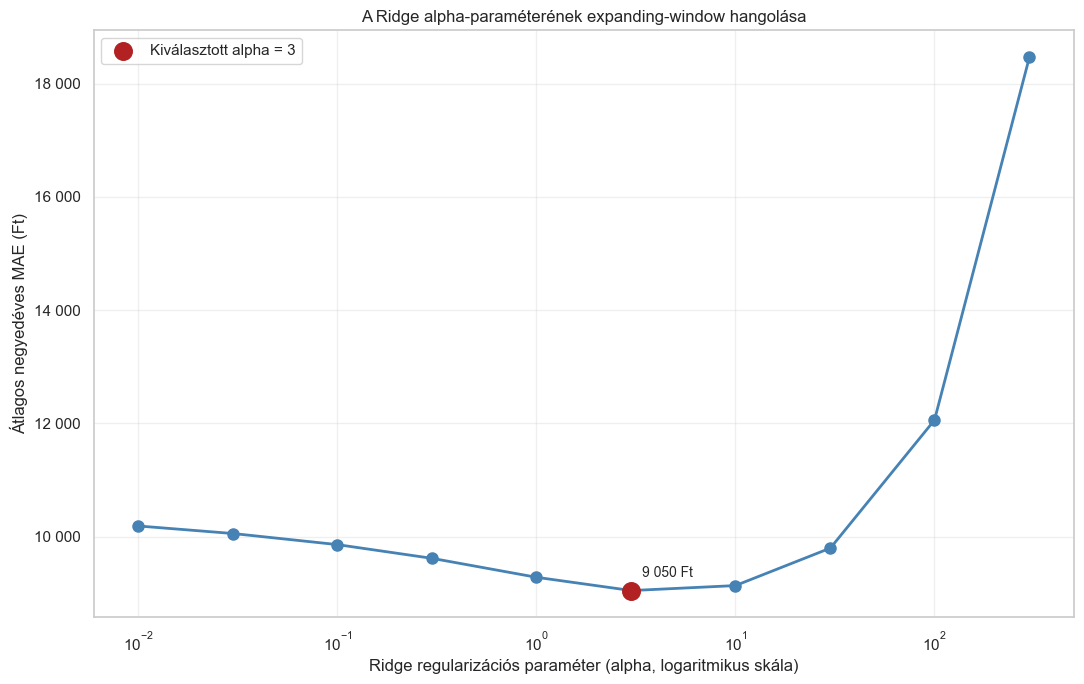

In [155]:
# ALPHA-HANGOLÁSI ÁBRA

from matplotlib.ticker import (
    FuncFormatter
)


def huf_axis_formatter(
    value,
    position
):

    return (
        f"{value:,.0f}"
        .replace(",", " ")
    )


fig, ax = plt.subplots(
    figsize=(11, 7)
)


ax.plot(
    ridge_tuning_summary[
        "Alpha"
    ],
    ridge_tuning_summary[
        "Átlag_MAE"
    ],
    marker="o",
    markersize=8,
    linewidth=2,
    color="steelblue"
)


ax.scatter(
    best_ridge_alpha,
    best_ridge_row[
        "Átlag_MAE"
    ],
    s=160,
    color="firebrick",
    zorder=3,
    label=(
        f"Kiválasztott alpha = "
        f"{best_ridge_alpha:g}"
    )
)


ax.annotate(
    (
        f"{best_ridge_row['Átlag_MAE']:,.0f} Ft"
        .replace(",", " ")
    ),
    (
        best_ridge_alpha,
        best_ridge_row[
            "Átlag_MAE"
        ]
    ),
    xytext=(8, 10),
    textcoords="offset points",
    fontsize=10
)


ax.set_xscale(
    "log"
)

ax.yaxis.set_major_formatter(
    FuncFormatter(
        huf_axis_formatter
    )
)

ax.set_xlabel(
    "Ridge regularizációs paraméter (alpha, logaritmikus skála)"
)

ax.set_ylabel(
    "Átlagos negyedéves MAE (Ft)"
)

ax.set_title(
    "A Ridge alpha-paraméterének expanding-window hangolása"
)

ax.grid(
    alpha=0.3
)

ax.legend()


plt.tight_layout()


fig.savefig(
    ML_FIGURES
    / "ridge_alpha_hangolas.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [156]:
# KIVÁLASZTOTT RIDGE FEJLESZTÉSI ELŐREJELZÉSEI

best_ridge_predictions = (
    ridge_tuning_predictions[
        ridge_tuning_predictions[
            "Alpha"
        ]
        ==
        best_ridge_alpha
    ]
    .copy()
)


assert len(
    best_ridge_predictions
) == 240


assert (
    best_ridge_predictions[
        "Modell"
    ]
    .nunique()
    == 1
)

In [157]:
# KIVÁLASZTOTT RIDGE ÉS NAIV BENCHMARKOK

tuned_development_predictions = pd.concat(
    [
        best_ridge_predictions,
        naive_previous_quarter_predictions,
        seasonal_naive_predictions
    ],
    ignore_index=True
)


(
    tuned_development_summary,
    tuned_development_quarterly_metrics

) = summarize_prediction_metrics(
    tuned_development_predictions
)


display(
    tuned_development_summary.round(3)
)

,Modell,Összesített_MAE,Összesített_RMSE,Összesített_R2,MAPE_%,Átlag_MAE,Medián_MAE,Legrosszabb_MAE,MAE_szórás,Átlag_RMSE,Átlag_R2,Negyedévek
0,Ridge alpha=3,9050.291,13228.523,0.972,1.992,9050.291,6790.918,30390.391,7361.769,10919.365,0.948,12
1,Naiv – előző negyedév,18800.179,25119.043,0.899,4.047,18800.179,13141.625,48092.700,14121.412,21364.792,0.839,12
2,Szezonális naiv – előző év,51104.533,53971.540,0.535,11.321,51104.533,52241.025,71340.150,15354.627,51904.615,0.194,12


In [158]:
ridge_tuning_predictions.to_csv(
    ML_RESULTS
    / "KSH_ridge_alpha_tuning_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)


ridge_tuning_summary.to_csv(
    ML_RESULTS
    / "KSH_ridge_alpha_tuning_summary.csv",
    index=False,
    encoding="utf-8-sig"
)


ridge_tuning_quarterly_metrics.to_csv(
    ML_RESULTS
    / "KSH_ridge_alpha_tuning_quarterly.csv",
    index=False,
    encoding="utf-8-sig"
)


tuned_development_predictions.to_csv(
    ML_RESULTS
    / "KSH_tuned_ridge_development_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)


tuned_development_summary.to_csv(
    ML_RESULTS
    / "KSH_tuned_ridge_development_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)


print(
    "A Ridge alpha-hangolás eredményei elmentve."
)

A Ridge alpha-hangolás eredményei elmentve.


## Gépi tanulási modellcsaládok összehasonlítása

A kiválasztott Ridge-modellt lineáris regresszióval, Lassóval,
Elastic Nettel, Random Foresttel és Gradient Boostinggal hasonlítjuk
össze.

Minden modell ugyanazt a szivárgásmentes feature-készletet és
expanding-window walk-forward validációt használja. A numerikus
változók standardizálása és a kategorikus változók kódolása minden
foldban kizárólag a tanítóhalmazon történik.

A hiperparaméterek keresési tartománya szándékosan korlátozott,
mivel csak 12 fejlesztési célnegyedév áll rendelkezésre. A túl nagy
paraméterrács növelné a fejlesztési időszakra történő túlillesztés
kockázatát.

Az elsődleges modellválasztási mutató az átlagos negyedéves MAE.
A 2024–2025-ös végső teszt ebben a szakaszban továbbra sem kerül
felhasználásra.

In [159]:
# TOVÁBBI REGRESSZIÓS MODELLEK

from sklearn.linear_model import (
    LinearRegression,
    Lasso,
    ElasticNet
)

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.model_selection import (
    ParameterGrid
)

In [160]:
# MODELLCSALÁDOK KORLÁTOZOTT PARAMÉTERRÁCSAI

model_search_spaces = {
    "Lineáris regresszió": {
        "estimator":
            LinearRegression(),

        "parameter_grid":
            {}
    },

    "Lasso": {
        "estimator":
            Lasso(
                max_iter=100000,
                tol=1e-4
            ),

        "parameter_grid": {
            "alpha": [
                10.0,
                30.0,
                100.0,
                300.0,
                1000.0,
                3000.0
            ]
        }
    },

    "Elastic Net": {
        "estimator":
            ElasticNet(
                max_iter=100000,
                tol=1e-4
            ),

        "parameter_grid": {
            "alpha": [0.1, 1.0, 10.0, 30.0, 100.0, 300.0, 1000.0],
   "l1_ratio": [0.1, 0.5, 0.9, 1.0]
        }
    },

    "Random Forest": {
        "estimator":
            RandomForestRegressor(
                n_estimators=200,
                random_state=42,
                n_jobs=-1
            ),

        "parameter_grid": {
            "max_depth": [
                4,
                None
            ],

            "min_samples_leaf": [
                2,
                5
            ],

            "max_features": [
                0.7,
                1.0
            ]
        }
    },

    "Gradient Boosting": {
        "estimator":
            GradientBoostingRegressor(
                random_state=42,
                min_samples_leaf=3
            ),

        "parameter_grid": {
            "n_estimators": [
                100,
                200
            ],

            "learning_rate": [
                0.03,
                0.05
            ],

            "max_depth": [
                2,
                3
            ]
        }
    }
}

In [161]:
# PARAMÉTEREK OLVASHATÓ FORMÁZÁSA

def format_model_parameters(
    parameters
):

    if not parameters:

        return (
            "alapbeállítás"
        )


    parameter_parts = []


    for parameter_name in sorted(
        parameters
    ):

        parameter_parts.append(
            (
                f"{parameter_name}="
                f"{parameters[parameter_name]}"
            )
        )


    return ", ".join(
        parameter_parts
    )

In [162]:
# MODELLCSALÁDOK FEJLESZTÉSI HANGOLÁSA

candidate_prediction_frames = []
candidate_summary_frames = []
candidate_quarterly_frames = []


configuration_counter = 0


for (
    model_family,
    search_definition

) in model_search_spaces.items():

    base_estimator = (
        search_definition[
            "estimator"
        ]
    )

    parameter_combinations = list(
        ParameterGrid(
            search_definition[
                "parameter_grid"
            ]
        )
    )


    for parameters in parameter_combinations:

        configuration_counter += 1


        parameter_text = (
            format_model_parameters(
                parameters
            )
        )


        configuration_name = (
            f"{model_family} | "
            f"{parameter_text}"
        )


        estimator = (
            clone(
                base_estimator
            )
            .set_params(
                **parameters
            )
        )


        configuration_predictions = (
            expanding_window_walk_forward(
                data=df_model,
                target_dates=development_target_dates,
                estimator=estimator,
                model_name=configuration_name,
                maximum_allowed_target_date=development_end
            )
        )


        configuration_predictions[
            "Modellcsalád"
        ] = model_family

        configuration_predictions[
            "Konfiguráció"
        ] = configuration_name

        configuration_predictions[
            "Paraméterek"
        ] = parameter_text


        (
            configuration_summary,
            configuration_quarterly

        ) = summarize_prediction_metrics(
            configuration_predictions
        )


        configuration_summary[
            "Modellcsalád"
        ] = model_family

        configuration_summary[
            "Konfiguráció"
        ] = configuration_name

        configuration_summary[
            "Paraméterek"
        ] = parameter_text


        configuration_quarterly[
            "Modellcsalád"
        ] = model_family

        configuration_quarterly[
            "Konfiguráció"
        ] = configuration_name

        configuration_quarterly[
            "Paraméterek"
        ] = parameter_text


        candidate_prediction_frames.append(
            configuration_predictions
        )

        candidate_summary_frames.append(
            configuration_summary
        )

        candidate_quarterly_frames.append(
            configuration_quarterly
        )


print(
    "Kiértékelt konfigurációk száma:",
    configuration_counter
)

Kiértékelt konfigurációk száma: 51


In [163]:
# MODELLKERESÉSI EREDMÉNYEK

candidate_search_predictions = pd.concat(
    candidate_prediction_frames,
    ignore_index=True
)


candidate_search_summary = pd.concat(
    candidate_summary_frames,
    ignore_index=True
)


candidate_search_quarterly = pd.concat(
    candidate_quarterly_frames,
    ignore_index=True
)


assert (
    candidate_search_predictions[
        "Cél_Dátum"
    ].max()
    <=
    development_end
)


assert (
    candidate_search_predictions[
        "Cél_Dátum"
    ]
    .nunique()
    == 12
)


print(
    "Összes modellkonfiguráció:",
    candidate_search_summary.shape[0]
)

Összes modellkonfiguráció: 51


In [164]:
# LEGJOBB KONFIGURÁCIÓ KIVÁLASZTÁSA MODELLCSALÁDONKÉNT

best_configuration_indices = (
    candidate_search_summary
    .groupby(
        "Modellcsalád"
    )[
        "Átlag_MAE"
    ]
    .idxmin()
)


best_candidate_by_family = (
    candidate_search_summary
    .loc[
        best_configuration_indices
    ]
    .sort_values(
        "Átlag_MAE"
    )
    .reset_index(
        drop=True
    )
)


display(
    best_candidate_by_family[
        [
            "Modellcsalád",
            "Paraméterek",
            "Átlag_MAE",
            "Medián_MAE",
            "Legrosszabb_MAE",
            "MAE_szórás",
            "Átlag_RMSE",
            "Átlag_R2",
            "MAPE_%"
        ]
    ]
    .round(3)
)

,Modellcsalád,Paraméterek,Átlag_MAE,Medián_MAE,Legrosszabb_MAE,MAE_szórás,Átlag_RMSE,Átlag_R2,MAPE_%
0,Elastic Net,"alpha=0.1, l1_ratio=0.9",9067.891,6648.017,30505.641,7399.223,10933.637,0.948,1.997
1,Lasso,alpha=100.0,9286.631,6496.159,31306.707,7609.278,10860.039,0.947,2.061
2,Lineáris regresszió,alapbeállítás,10320.642,6774.117,32680.526,8287.246,12160.896,0.936,2.249
3,Gradient Boosting,"learning_rate=0.05, max_depth=3, n_estimators=200",12023.766,11183.284,29958.675,7177.714,15628.804,0.916,2.596
4,Random Forest,"max_depth=None, max_features=0.7, min_samples_leaf=2",12168.079,8822.361,29418.554,7867.430,16250.911,0.907,2.544


In [165]:
# MODELLCSALÁDONKÉNTI LEGJOBB ELŐREJELZÉSEK

selected_candidate_frames = []


for _, selected_row in (
    best_candidate_by_family
    .iterrows()
):

    model_family = (
        selected_row[
            "Modellcsalád"
        ]
    )

    configuration_name = (
        selected_row[
            "Konfiguráció"
        ]
    )


    selected_predictions = (
        candidate_search_predictions[
            candidate_search_predictions[
                "Konfiguráció"
            ]
            ==
            configuration_name
        ]
        .copy()
    )


    selected_predictions[
        "Modell"
    ] = model_family

    selected_predictions[
        "Kiválasztott_konfiguráció"
    ] = (
        selected_row[
            "Paraméterek"
        ]
    )


    selected_candidate_frames.append(
        selected_predictions
    )


selected_candidate_predictions = pd.concat(
    selected_candidate_frames,
    ignore_index=True
)


assert (
    selected_candidate_predictions
    .groupby(
        "Modell"
    )
    .size()
    .eq(240)
    .all()
)

In [166]:
# KIVÁLASZTOTT RIDGE

ridge_comparison_predictions = (
    best_ridge_predictions
    .copy()
)


ridge_comparison_predictions[
    "Modell"
] = "Ridge"

ridge_comparison_predictions[
    "Modellcsalád"
] = "Ridge"

ridge_comparison_predictions[
    "Kiválasztott_konfiguráció"
] = (
    f"alpha={best_ridge_alpha:g}"
)

In [167]:
# NAIV BENCHMARKOK

naive_comparison_predictions = (
    naive_previous_quarter_predictions
    .copy()
)

naive_comparison_predictions[
    "Modellcsalád"
] = "Benchmark"

naive_comparison_predictions[
    "Kiválasztott_konfiguráció"
] = "Nincs"


seasonal_comparison_predictions = (
    seasonal_naive_predictions
    .copy()
)

seasonal_comparison_predictions[
    "Modellcsalád"
] = "Benchmark"

seasonal_comparison_predictions[
    "Kiválasztott_konfiguráció"
] = "Nincs"

In [168]:
# ÖSSZES KIVÁLASZTOTT MODELL

development_model_predictions = pd.concat(
    [
        ridge_comparison_predictions,
        selected_candidate_predictions,
        naive_comparison_predictions,
        seasonal_comparison_predictions
    ],
    ignore_index=True
)


assert (
    development_model_predictions
    .groupby(
        "Modell"
    )
    .size()
    .eq(240)
    .all()
)


assert (
    development_model_predictions[
        "Cél_Dátum"
    ].max()
    <=
    development_end
)

In [169]:
# FEJLESZTÉSI MODELLMETRIKÁK

(
    development_model_summary,
    development_model_quarterly_metrics

) = summarize_prediction_metrics(
    development_model_predictions
)


display(
    development_model_summary[
        [
            "Modell",
            "Átlag_MAE",
            "Medián_MAE",
            "Legrosszabb_MAE",
            "MAE_szórás",
            "Átlag_RMSE",
            "Átlag_R2",
            "MAPE_%",
            "Negyedévek"
        ]
    ]
    .round(3)
)

,Modell,Átlag_MAE,Medián_MAE,Legrosszabb_MAE,MAE_szórás,Átlag_RMSE,Átlag_R2,MAPE_%,Negyedévek
0,Ridge,9050.291,6790.918,30390.391,7361.769,10919.365,0.948,1.992,12
1,Elastic Net,9067.891,6648.017,30505.641,7399.223,10933.637,0.948,1.997,12
2,Lasso,9286.631,6496.159,31306.707,7609.278,10860.039,0.947,2.061,12
3,Lineáris regresszió,10320.642,6774.117,32680.526,8287.246,12160.896,0.936,2.249,12
4,Gradient Boosting,12023.766,11183.284,29958.675,7177.714,15628.804,0.916,2.596,12
5,Random Forest,12168.079,8822.361,29418.554,7867.430,16250.911,0.907,2.544,12
6,Naiv – előző negyedév,18800.179,13141.625,48092.700,14121.412,21364.792,0.839,4.047,12
7,Szezonális naiv – előző év,51104.533,52241.025,71340.150,15354.627,51904.615,0.194,11.321,12


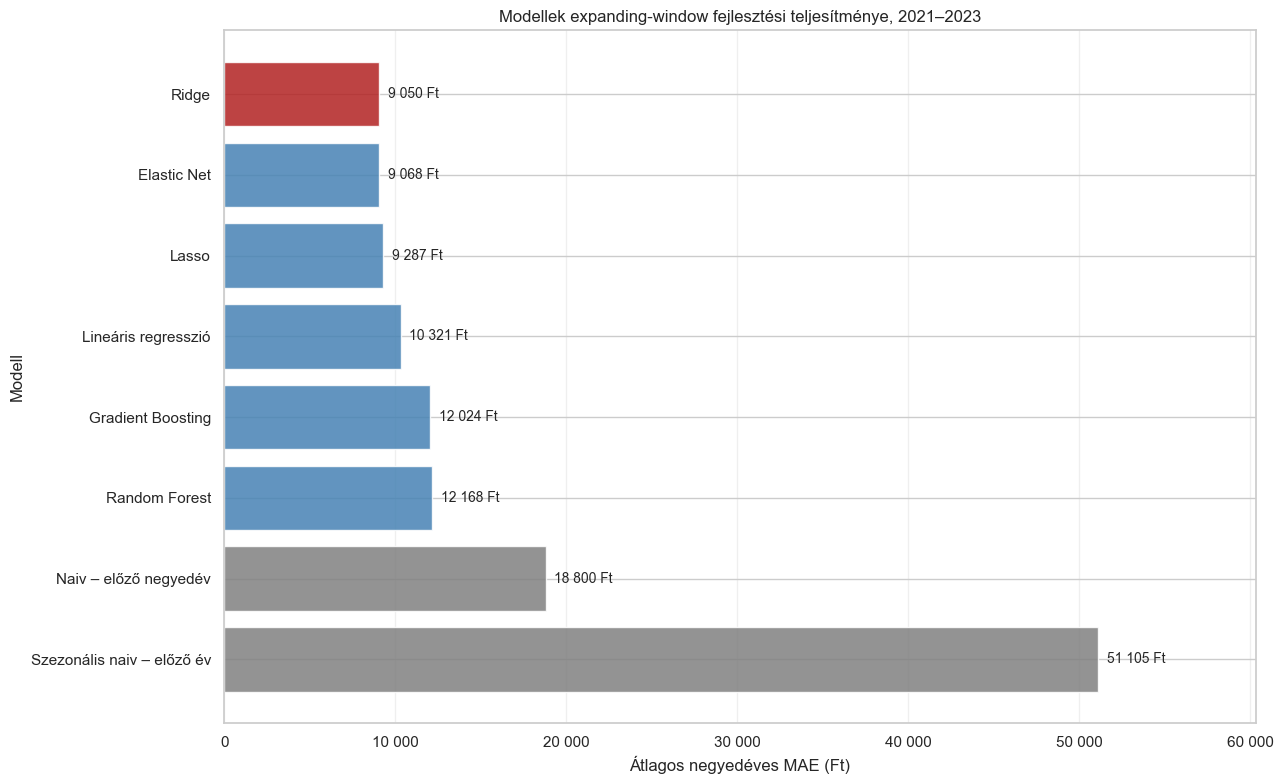

In [170]:
# FEJLESZTÉSI MODELL-ÖSSZEHASONLÍTÓ ÁBRA

model_plot_data = (
    development_model_summary
    .sort_values(
        "Átlag_MAE",
        ascending=False
    )
    .copy()
)


best_development_model = (
    development_model_summary
    .sort_values(
        "Átlag_MAE"
    )
    .iloc[0][
        "Modell"
    ]
)


bar_colors = [
    (
        "firebrick"

        if model_name
        ==
        best_development_model

        else (
            "grey"

            if "naiv"
            in model_name.lower()

            else "steelblue"
        )
    )

    for model_name
    in model_plot_data[
        "Modell"
    ]
]


fig, ax = plt.subplots(
    figsize=(13, 8)
)


bars = ax.barh(
    model_plot_data[
        "Modell"
    ],
    model_plot_data[
        "Átlag_MAE"
    ],
    color=bar_colors,
    alpha=0.85
)


maximum_mae = (
    model_plot_data[
        "Átlag_MAE"
    ].max()
)


for bar, mae_value in zip(
    bars,
    model_plot_data[
        "Átlag_MAE"
    ]
):

    ax.text(
        mae_value
        +
        maximum_mae
        * 0.01,
        bar.get_y()
        +
        bar.get_height()
        / 2,
        (
            f"{mae_value:,.0f} Ft"
            .replace(",", " ")
        ),
        va="center",
        fontsize=10
    )


ax.set_xlim(
    0,
    maximum_mae
    * 1.18
)

ax.xaxis.set_major_formatter(
    FuncFormatter(
        huf_axis_formatter
    )
)

ax.set_xlabel(
    "Átlagos negyedéves MAE (Ft)"
)

ax.set_ylabel(
    "Modell"
)

ax.set_title(
    "Modellek expanding-window fejlesztési teljesítménye, 2021–2023"
)

ax.grid(
    axis="x",
    alpha=0.3
)


plt.tight_layout()


fig.savefig(
    ML_FIGURES
    / "fejlesztesi_modellek_mae_osszehasonlitas.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [171]:
candidate_search_predictions.to_csv(
    ML_RESULTS
    / "KSH_candidate_model_search_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)


candidate_search_summary.to_csv(
    ML_RESULTS
    / "KSH_candidate_model_search_summary.csv",
    index=False,
    encoding="utf-8-sig"
)


best_candidate_by_family.to_csv(
    ML_RESULTS
    / "KSH_best_configuration_by_model_family.csv",
    index=False,
    encoding="utf-8-sig"
)


development_model_predictions.to_csv(
    ML_RESULTS
    / "KSH_development_model_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)


development_model_summary.to_csv(
    ML_RESULTS
    / "KSH_development_model_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)


development_model_quarterly_metrics.to_csv(
    ML_RESULTS
    / "KSH_development_model_quarterly_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)


print(
    "A fejlesztési modell-összehasonlítás eredményei elmentve."
)

A fejlesztési modell-összehasonlítás eredményei elmentve.


## Feature-csoportok ablatív vizsgálata

A fejlesztési validáció alapján legjobb Ridge-modell feature-csoportjainak
hozzájárulását ablatív vizsgálattal értékeljük. A vizsgálat során egy-egy
feature-csoportot eltávolítunk a teljes modellből, miközben a Ridge
regularizációs paraméterét változatlanul tartjuk.

Az összehasonlítás minden esetben ugyanazon, 2021–2023 közötti
expanding-window walk-forward validációval történik. Elsődleges
értékelési mutató az átlagos negyedéves MAE.

In [172]:
# FEATURE-KÉSZLETHEZ IGAZODÓ MODELLPIPELINE

def create_feature_set_pipeline(
    estimator,
    numeric_feature_names,
    categorical_feature_names
):

    transformers = []


    if numeric_feature_names:

        numeric_transformer = Pipeline(
            steps=[
                (
                    "imputer",
                    SimpleImputer(
                        strategy="median"
                    )
                ),

                (
                    "scaler",
                    StandardScaler()
                )
            ]
        )


        transformers.append(
            (
                "numeric",
                numeric_transformer,
                numeric_feature_names
            )
        )


    if categorical_feature_names:

        categorical_transformer = Pipeline(
            steps=[
                (
                    "imputer",
                    SimpleImputer(
                        strategy="most_frequent"
                    )
                ),

                (
                    "onehot",
                    OneHotEncoder(
                        handle_unknown="ignore",
                        drop="first",
                        sparse_output=False
                    )
                )
            ]
        )


        transformers.append(
            (
                "categorical",
                categorical_transformer,
                categorical_feature_names
            )
        )


    assert transformers, (
        "A modellnek legalább egy feature-rel rendelkeznie kell."
    )


    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder="drop",
        verbose_feature_names_out=False
    )


    return Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor
            ),

            (
                "model",
                clone(
                    estimator
                )
            )
        ]
    )

In [173]:
# FEATURE-KÉSZLETES EXPANDING-WINDOW WALK-FORWARD

def expanding_window_feature_ablation(
    data,
    target_dates,
    estimator,
    feature_set_name,
    numeric_feature_names,
    categorical_feature_names,
    maximum_allowed_target_date
):

    selected_features = (
        list(numeric_feature_names)
        +
        list(categorical_feature_names)
    )


    assert selected_features

    assert len(
        selected_features
    ) == len(
        set(selected_features)
    )

    assert set(
        selected_features
    ).issubset(
        data.columns
    )


    prediction_frames = []


    for fold_number, target_date in enumerate(
        sorted(target_dates),
        start=1
    ):

        train_data = (
            data.loc[
                data["Cél_Dátum"] < target_date
            ]
            .copy()
        )

        test_data = (
            data.loc[
                data["Cél_Dátum"] == target_date
            ]
            .copy()
        )


        assert not train_data.empty
        assert len(test_data) == 20

        assert (
            train_data["Cél_Dátum"].max()
            <
            target_date
        )


        X_train = train_data[
            selected_features
        ]

        y_train = train_data[
            target_column
        ]

        X_test = test_data[
            selected_features
        ]


        fold_pipeline = (
            create_feature_set_pipeline(
                estimator=estimator,
                numeric_feature_names=numeric_feature_names,
                categorical_feature_names=categorical_feature_names
            )
        )


        fold_pipeline.fit(
            X_train,
            y_train
        )


        fold_predictions = (
            fold_pipeline.predict(
                X_test
            )
        )


        fold_result = (
            test_data[
                [
                    "Dátum",
                    "Cél_Dátum",
                    "Területi egység neve"
                ]
            ]
            .copy()
        )


        fold_result["Modell"] = (
            feature_set_name
        )

        fold_result["Feature_készlet"] = (
            feature_set_name
        )

        fold_result["Fold"] = fold_number

        fold_result["Tanítósorok"] = len(
            train_data
        )

        fold_result[
            "Tanítás_utolsó_célnegyedéve"
        ] = train_data[
            "Cél_Dátum"
        ].max()

        fold_result["Valós_bér"] = (
            test_data[
                target_column
            ]
            .to_numpy()
        )

        fold_result["Predikció"] = (
            fold_predictions
        )

        fold_result["Hiba"] = (
            fold_result["Predikció"]
            -
            fold_result["Valós_bér"]
        )

        fold_result["Abszolút_hiba"] = (
            fold_result["Hiba"].abs()
        )


        prediction_frames.append(
            fold_result
        )


    predictions = pd.concat(
        prediction_frames,
        ignore_index=True
    )


    assert len(predictions) == (
        len(target_dates) * 20
    )

    assert (
        predictions["Cél_Dátum"].max()
        <=
        maximum_allowed_target_date
    )


    return predictions

In [174]:
# FEATURE-ABLATION KÍSÉRLETEK

feature_ablation_sets = {

    "Teljes modell": {
        "numeric":
            list(numeric_features),

        "categorical":
            list(categorical_features)
    },


    "Bérdinamika nélkül": {
        "numeric":
            (
                list(labour_market_features)
                +
                list(time_features)
            ),

        "categorical":
            list(categorical_features)
    },


    "Munkaerőpiac nélkül": {
        "numeric":
            (
                list(wage_features)
                +
                list(time_features)
            ),

        "categorical":
            list(categorical_features)
    },


    "Időtrend nélkül": {
        "numeric":
            (
                list(wage_features)
                +
                list(labour_market_features)
            ),

        "categorical":
            list(categorical_features)
    },


    "Területi azonosító nélkül": {
        "numeric":
            list(numeric_features),

        "categorical":
            [
                "Negyedév_kategória"
            ]
    },


    "Negyedéves szezonalitás nélkül": {
        "numeric":
            list(numeric_features),

        "categorical":
            [
                "Területi egység neve"
            ]
    },


    "Csak bérdinamika": {
        "numeric":
            list(wage_features),

        "categorical":
            []
    }
}


feature_counts = {
    feature_set_name:
        (
            len(feature_definition["numeric"])
            +
            len(feature_definition["categorical"])
        )

    for feature_set_name, feature_definition
    in feature_ablation_sets.items()
}


display(
    pd.DataFrame(
        {
            "Feature_készlet":
                list(feature_counts.keys()),

            "Feature_szám":
                list(feature_counts.values())
        }
    )
)

,Feature_készlet,Feature_szám
0,Teljes modell,15
1,Bérdinamika nélkül,8
2,Munkaerőpiac nélkül,10
3,Időtrend nélkül,14
4,Területi azonosító nélkül,14
5,Negyedéves szezonalitás nélkül,14
6,Csak bérdinamika,7


In [175]:
# RIDGE FEATURE-ABLATION FUTTATÁSA

feature_ablation_prediction_frames = []


for (
    feature_set_name,
    feature_definition

) in feature_ablation_sets.items():

    print(
        "Futtatás:",
        feature_set_name
    )


    feature_set_predictions = (
        expanding_window_feature_ablation(
            data=df_model,
            target_dates=development_target_dates,
            estimator=Ridge(
                alpha=best_ridge_alpha
            ),
            feature_set_name=feature_set_name,
            numeric_feature_names=(
                feature_definition["numeric"]
            ),
            categorical_feature_names=(
                feature_definition["categorical"]
            ),
            maximum_allowed_target_date=development_end
        )
    )


    feature_ablation_prediction_frames.append(
        feature_set_predictions
    )


feature_ablation_predictions = pd.concat(
    feature_ablation_prediction_frames,
    ignore_index=True
)


assert (
    feature_ablation_predictions
    .groupby("Modell")
    .size()
    .eq(240)
    .all()
)


print(
    "Elkészült feature-készletek:",
    feature_ablation_predictions[
        "Modell"
    ].nunique()
)

Futtatás: Teljes modell
Futtatás: Bérdinamika nélkül
Futtatás: Munkaerőpiac nélkül
Futtatás: Időtrend nélkül
Futtatás: Területi azonosító nélkül
Futtatás: Negyedéves szezonalitás nélkül
Futtatás: Csak bérdinamika
Elkészült feature-készletek: 7


In [176]:
# A TELJES MODELL EREDMÉNYÉNEK VISSZAELLENŐRZÉSE

full_ablation_predictions = (
    feature_ablation_predictions[
        feature_ablation_predictions["Modell"]
        ==
        "Teljes modell"
    ]
    .sort_values(
        [
            "Cél_Dátum",
            "Területi egység neve"
        ]
    )
    .reset_index(drop=True)
)


reference_ridge_predictions = (
    best_ridge_predictions
    .sort_values(
        [
            "Cél_Dátum",
            "Területi egység neve"
        ]
    )
    .reset_index(drop=True)
)


assert np.allclose(
    full_ablation_predictions["Predikció"],
    reference_ridge_predictions["Predikció"],
    rtol=1e-10,
    atol=1e-6
)


print(
    "A teljes feature-készlet reprodukálja "
    "a korábbi Ridge-eredményt."
)

A teljes feature-készlet reprodukálja a korábbi Ridge-eredményt.


In [177]:
# FEATURE-ABLATION METRIKÁK

(
    feature_ablation_summary,
    feature_ablation_quarterly_metrics

) = summarize_prediction_metrics(
    feature_ablation_predictions
)


full_feature_mae = float(
    feature_ablation_summary.loc[
        feature_ablation_summary["Modell"]
        ==
        "Teljes modell",
        "Átlag_MAE"
    ].iloc[0]
)


feature_ablation_summary[
    "Feature_szám"
] = (
    feature_ablation_summary["Modell"]
    .map(feature_counts)
)


feature_ablation_summary[
    "MAE_változás_teljeshez_Ft"
] = (
    feature_ablation_summary["Átlag_MAE"]
    -
    full_feature_mae
)


feature_ablation_summary[
    "MAE_változás_teljeshez_%"
] = (
    (
        feature_ablation_summary["Átlag_MAE"]
        /
        full_feature_mae
    )
    -
    1
) * 100


feature_ablation_summary = (
    feature_ablation_summary
    .sort_values("Átlag_MAE")
    .reset_index(drop=True)
)


display(
    feature_ablation_summary[
        [
            "Modell",
            "Feature_szám",
            "Átlag_MAE",
            "Medián_MAE",
            "Legrosszabb_MAE",
            "MAE_szórás",
            "Átlag_RMSE",
            "Átlag_R2",
            "MAPE_%",
            "MAE_változás_teljeshez_Ft",
            "MAE_változás_teljeshez_%"
        ]
    ]
    .round(3)
)


provisional_best_feature_set = (
    feature_ablation_summary
    .iloc[0]["Modell"]
)


print(
    "Fejlesztési időszakban legjobb feature-készlet:",
    provisional_best_feature_set
)

,Modell,Feature_szám,Átlag_MAE,Medián_MAE,Legrosszabb_MAE,MAE_szórás,Átlag_RMSE,Átlag_R2,MAPE_%,MAE_változás_teljeshez_Ft,MAE_változás_teljeshez_%
0,Időtrend nélkül,14,8939.824,6580.333,31147.729,7682.038,10769.685,0.948,1.966,-110.466,-1.221
1,Területi azonosító nélkül,14,8991.302,6927.848,30571.871,7351.769,10759.301,0.949,1.985,-58.988,-0.652
2,Munkaerőpiac nélkül,10,8995.804,6822.492,30620.100,7346.675,10792.148,0.949,1.990,-54.487,-0.602
3,Teljes modell,15,9050.291,6790.918,30390.391,7361.769,10919.365,0.948,1.992,0.000,0.000
4,Csak bérdinamika,7,10674.319,7566.547,30959.178,8247.075,12328.891,0.938,2.321,1624.029,17.944
5,Negyedéves szezonalitás nélkül,14,11300.130,9979.252,30585.379,7170.789,12876.520,0.937,2.484,2249.839,24.859
6,Bérdinamika nélkül,8,16580.719,14367.121,31224.533,7160.246,21582.022,0.855,3.517,7530.428,83.206


Fejlesztési időszakban legjobb feature-készlet: Időtrend nélkül


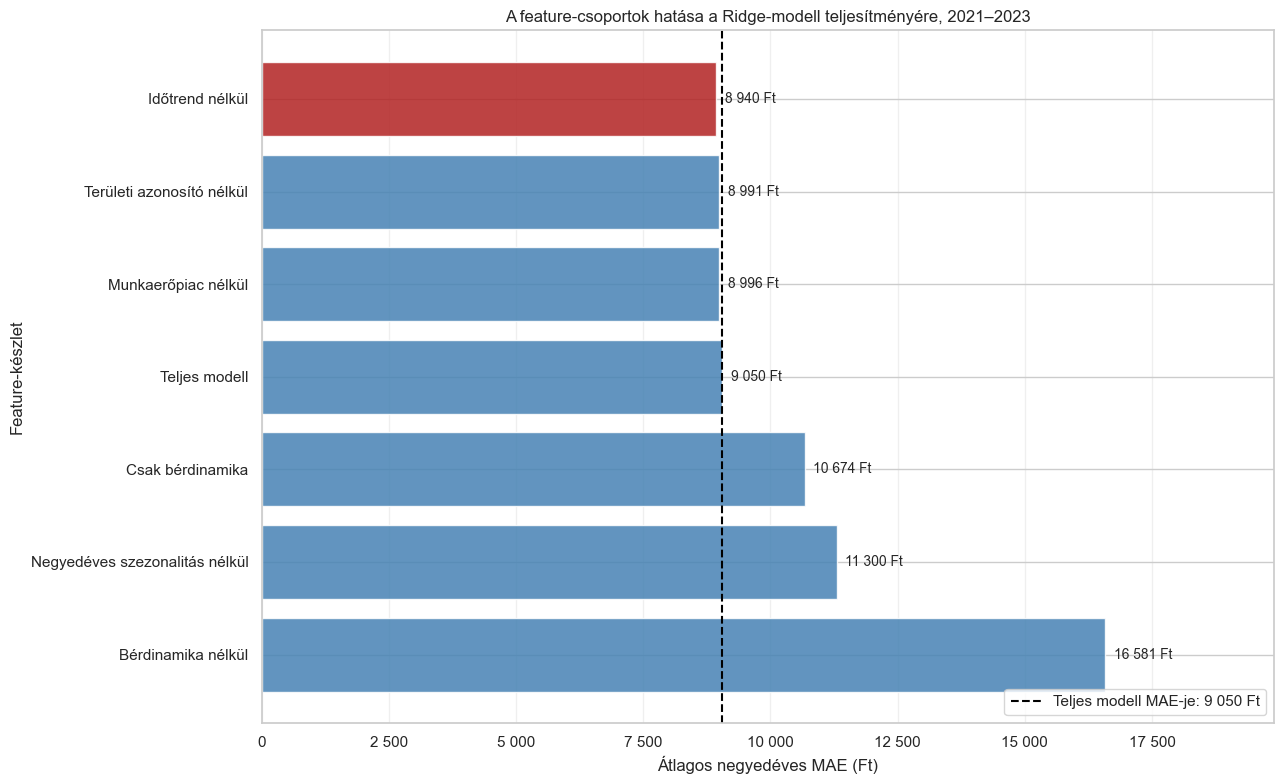

In [178]:
# FEATURE-ABLATION VIZUALIZÁCIÓ

feature_plot_data = (
    feature_ablation_summary
    .sort_values(
        "Átlag_MAE",
        ascending=False
    )
    .copy()
)


ablation_colors = [
    (
        "firebrick"

        if feature_set_name
        ==
        provisional_best_feature_set

        else "steelblue"
    )

    for feature_set_name
    in feature_plot_data["Modell"]
]


fig, ax = plt.subplots(
    figsize=(13, 8)
)


bars = ax.barh(
    feature_plot_data["Modell"],
    feature_plot_data["Átlag_MAE"],
    color=ablation_colors,
    alpha=0.85
)


maximum_ablation_mae = (
    feature_plot_data["Átlag_MAE"].max()
)


for bar, mae_value in zip(
    bars,
    feature_plot_data["Átlag_MAE"]
):

    ax.text(
        mae_value
        +
        maximum_ablation_mae * 0.01,
        bar.get_y()
        +
        bar.get_height() / 2,
        (
            f"{mae_value:,.0f} Ft"
            .replace(",", " ")
        ),
        va="center",
        fontsize=10
    )


ax.axvline(
    full_feature_mae,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=(
        "Teljes modell MAE-je: "
        +
        f"{full_feature_mae:,.0f} Ft"
        .replace(",", " ")
    )
)


ax.set_xlim(
    0,
    maximum_ablation_mae * 1.20
)

ax.xaxis.set_major_formatter(
    FuncFormatter(
        huf_axis_formatter
    )
)

ax.set_xlabel(
    "Átlagos negyedéves MAE (Ft)"
)

ax.set_ylabel(
    "Feature-készlet"
)

ax.set_title(
    "A feature-csoportok hatása a Ridge-modell teljesítményére, 2021–2023"
)

ax.grid(
    axis="x",
    alpha=0.3
)

ax.legend(
    loc="lower right"
)


plt.tight_layout()


fig.savefig(
    ML_FIGURES
    / "ridge_feature_ablation_mae.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [179]:
# FEATURE-ABLATION EREDMÉNYEK MENTÉSE

feature_ablation_predictions.to_csv(
    ML_RESULTS
    / "KSH_feature_ablation_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)


feature_ablation_summary.to_csv(
    ML_RESULTS
    / "KSH_feature_ablation_summary.csv",
    index=False,
    encoding="utf-8-sig"
)


feature_ablation_quarterly_metrics.to_csv(
    ML_RESULTS
    / "KSH_feature_ablation_quarterly_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)


print(
    "A feature-ablation eredményei elmentve."
)

A feature-ablation eredményei elmentve.


## A kiválasztott feature-készlet végleges hangolása

Az ablatív vizsgálat alapján az időtrend nélküli Ridge-modell érte el
a legalacsonyabb átlagos negyedéves MAE-értéket. Bár az eltérés a teljes
modellhez képest mérsékelt, az egyszerűbb specifikáció nem tartalmazza
a béradatok késleltetett értékeivel részben redundáns determinisztikus
időtrendet.

Mivel a feature-készlet megváltozott, a Ridge regularizációs paraméterét
ismételten meghatározzuk. A hangolás továbbra is kizárólag a 2021–2023-as
fejlesztési időszakon, expanding-window walk-forward validációval történik.
A 2024–2025-ös végső tesztadatokat ebben a lépésben nem használjuk.

In [180]:
# IDŐTREND NÉLKÜLI FEATURE-KÉSZLET

no_trend_numeric_features = (
    list(wage_features)
    +
    list(labour_market_features)
)


no_trend_categorical_features = (
    list(categorical_features)
)


no_trend_all_features = (
    no_trend_numeric_features
    +
    no_trend_categorical_features
)


assert (
    "Időtrend_negyedév"
    not in no_trend_all_features
)


assert len(
    no_trend_all_features
) == 14


assert set(
    no_trend_all_features
).issubset(
    df_model.columns
)


print(
    "Numerikus feature-ök:",
    len(no_trend_numeric_features)
)

print(
    "Kategorikus feature-ök:",
    len(no_trend_categorical_features)
)

print(
    "Összes feature:",
    len(no_trend_all_features)
)

Numerikus feature-ök: 12
Kategorikus feature-ök: 2
Összes feature: 14


In [181]:
# RIDGE ALPHA ÚJRAHANGOLÁSA AZ IDŐTREND NÉLKÜLI MODELLEN

no_trend_tuning_prediction_frames = []
no_trend_tuning_summary_frames = []
no_trend_tuning_quarterly_frames = []


for alpha_value in ridge_alpha_values:

    model_name = (
        f"Ridge alpha={alpha_value:g} | "
        "Időtrend nélkül"
    )


    alpha_predictions = (
        expanding_window_feature_ablation(
            data=df_model,
            target_dates=development_target_dates,
            estimator=Ridge(
                alpha=alpha_value
            ),
            feature_set_name=model_name,
            numeric_feature_names=(
                no_trend_numeric_features
            ),
            categorical_feature_names=(
                no_trend_categorical_features
            ),
            maximum_allowed_target_date=development_end
        )
    )


    alpha_predictions[
        "Alpha"
    ] = alpha_value


    (
        alpha_summary,
        alpha_quarterly_metrics

    ) = summarize_prediction_metrics(
        alpha_predictions
    )


    alpha_summary[
        "Alpha"
    ] = alpha_value

    alpha_quarterly_metrics[
        "Alpha"
    ] = alpha_value


    no_trend_tuning_prediction_frames.append(
        alpha_predictions
    )

    no_trend_tuning_summary_frames.append(
        alpha_summary
    )

    no_trend_tuning_quarterly_frames.append(
        alpha_quarterly_metrics
    )

In [182]:
# IDŐTREND NÉLKÜLI RIDGE HANGOLÁSI EREDMÉNYEI

no_trend_tuning_predictions = pd.concat(
    no_trend_tuning_prediction_frames,
    ignore_index=True
)


no_trend_tuning_summary = (
    pd.concat(
        no_trend_tuning_summary_frames,
        ignore_index=True
    )
    .sort_values("Alpha")
    .reset_index(drop=True)
)


no_trend_tuning_quarterly_metrics = (
    pd.concat(
        no_trend_tuning_quarterly_frames,
        ignore_index=True
    )
    .sort_values(
        [
            "Alpha",
            "Cél_Dátum"
        ]
    )
    .reset_index(drop=True)
)


assert len(
    no_trend_tuning_predictions
) == (
    len(ridge_alpha_values)
    *
    240
)


assert (
    no_trend_tuning_predictions[
        "Cél_Dátum"
    ].max()
    <=
    development_end
)


display(
    no_trend_tuning_summary[
        [
            "Alpha",
            "Átlag_MAE",
            "Medián_MAE",
            "Legrosszabb_MAE",
            "MAE_szórás",
            "Átlag_RMSE",
            "Átlag_R2",
            "MAPE_%"
        ]
    ]
    .round(3)
)

,Alpha,Átlag_MAE,Medián_MAE,Legrosszabb_MAE,MAE_szórás,Átlag_RMSE,Átlag_R2,MAPE_%
0,0.01,9863.721,7177.760,32888.091,8091.304,11499.632,0.940,2.193
1,0.03,9823.688,7039.112,32777.759,8054.460,11431.560,0.941,2.183
2,0.10,9706.840,6757.940,32508.158,7964.016,11293.139,0.942,2.157
3,0.30,9529.652,6413.282,32127.011,7836.157,11121.400,0.944,2.116
4,1.00,9212.172,6534.772,31611.303,7725.381,10894.205,0.946,2.038
5,3.00,8939.824,6580.333,31147.729,7682.038,10769.685,0.948,1.966
6,10.00,9094.302,6674.259,30983.568,7772.942,11119.570,0.946,1.981
7,30.00,10399.273,7860.765,31538.954,8077.850,12381.468,0.937,2.252
8,100.00,14124.053,13776.521,33693.804,9728.052,16162.128,0.902,3.035
9,300.00,22662.845,25094.008,38878.091,12505.743,25929.192,0.779,4.814


In [183]:
# VÉGLEGES RIDGE ALPHA

best_no_trend_row = (
    no_trend_tuning_summary
    .sort_values(
        [
            "Átlag_MAE",
            "MAE_szórás"
        ]
    )
    .iloc[0]
)


final_ridge_alpha = float(
    best_no_trend_row[
        "Alpha"
    ]
)


final_development_model_name = (
    best_no_trend_row[
        "Modell"
    ]
)


print(
    "Végleges Ridge alpha:",
    final_ridge_alpha
)

print(
    "Fejlesztési átlagos MAE:",
    (
        f"{best_no_trend_row['Átlag_MAE']:,.0f} Ft"
        .replace(",", " ")
    )
)

print(
    "Fejlesztési átlagos RMSE:",
    (
        f"{best_no_trend_row['Átlag_RMSE']:,.0f} Ft"
        .replace(",", " ")
    )
)

print(
    "Fejlesztési átlagos R²:",
    f"{best_no_trend_row['Átlag_R2']:.3f}"
)

Végleges Ridge alpha: 3.0
Fejlesztési átlagos MAE: 8 940 Ft
Fejlesztési átlagos RMSE: 10 770 Ft
Fejlesztési átlagos R²: 0.948


In [184]:
# TELJES ÉS IDŐTREND NÉLKÜLI MODELL ÖSSZEHASONLÍTÁSA

final_feature_comparison = pd.DataFrame(
    [
        {
            "Modell":
                "Teljes modell",

            "Feature_szám":
                len(all_model_features),

            "Alpha":
                best_ridge_alpha,

            "Átlag_MAE":
                full_feature_mae,

            "Átlag_RMSE":
                float(
                    best_ridge_row[
                        "Átlag_RMSE"
                    ]
                ),

            "Átlag_R2":
                float(
                    best_ridge_row[
                        "Átlag_R2"
                    ]
                )
        },

        {
            "Modell":
                "Időtrend nélküli modell",

            "Feature_szám":
                len(no_trend_all_features),

            "Alpha":
                final_ridge_alpha,

            "Átlag_MAE":
                float(
                    best_no_trend_row[
                        "Átlag_MAE"
                    ]
                ),

            "Átlag_RMSE":
                float(
                    best_no_trend_row[
                        "Átlag_RMSE"
                    ]
                ),

            "Átlag_R2":
                float(
                    best_no_trend_row[
                        "Átlag_R2"
                    ]
                )
        }
    ]
)


final_feature_comparison[
    "MAE_változás_teljeshez_Ft"
] = (
    final_feature_comparison[
        "Átlag_MAE"
    ]
    -
    full_feature_mae
)


final_feature_comparison[
    "MAE_változás_teljeshez_%"
] = (
    (
        final_feature_comparison[
            "Átlag_MAE"
        ]
        /
        full_feature_mae
    )
    -
    1
) * 100


display(
    final_feature_comparison.round(3)
)

,Modell,Feature_szám,Alpha,Átlag_MAE,Átlag_RMSE,Átlag_R2,MAE_változás_teljeshez_Ft,MAE_változás_teljeshez_%
0,Teljes modell,15,3.0,9050.291,10919.365,0.948,0.000,0.000
1,Időtrend nélküli modell,14,3.0,8939.824,10769.685,0.948,-110.466,-1.221


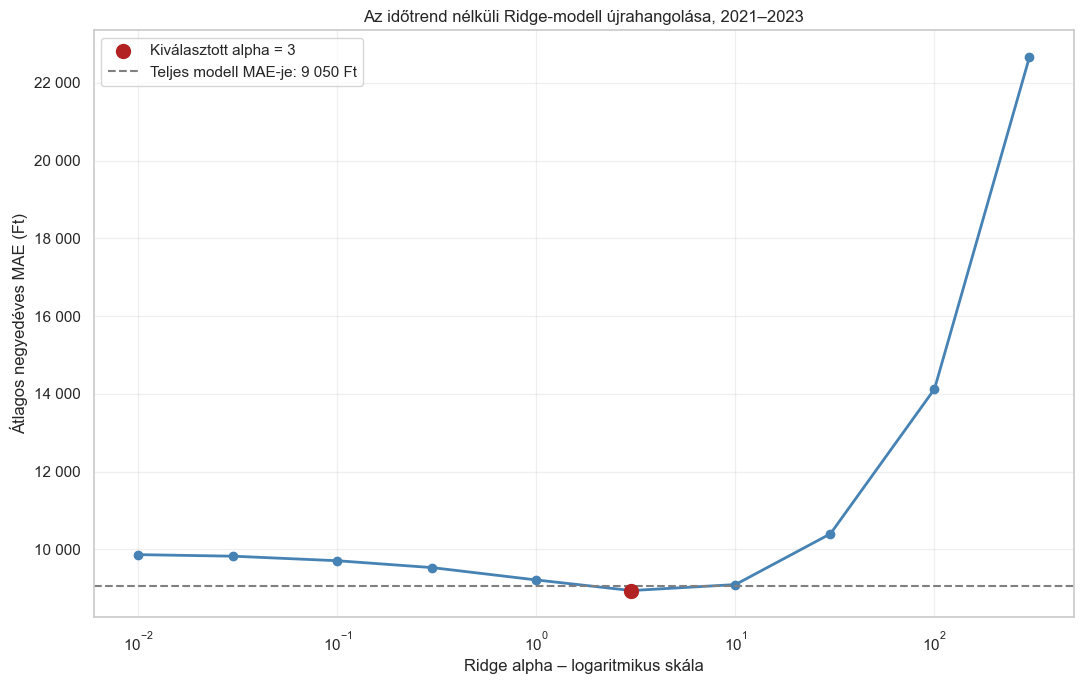

In [185]:
# IDŐTREND NÉLKÜLI RIDGE ALPHA-HANGOLÁSI ÁBRA

fig, ax = plt.subplots(
    figsize=(11, 7)
)


ax.plot(
    no_trend_tuning_summary["Alpha"],
    no_trend_tuning_summary["Átlag_MAE"],
    marker="o",
    linewidth=2,
    color="steelblue"
)


ax.scatter(
    final_ridge_alpha,
    best_no_trend_row["Átlag_MAE"],
    color="firebrick",
    s=100,
    zorder=3,
    label=(
        f"Kiválasztott alpha = "
        f"{final_ridge_alpha:g}"
    )
)


ax.axhline(
    full_feature_mae,
    color="grey",
    linestyle="--",
    linewidth=1.5,
    label=(
        "Teljes modell MAE-je: "
        +
        f"{full_feature_mae:,.0f} Ft"
        .replace(",", " ")
    )
)


ax.set_xscale(
    "log"
)

ax.yaxis.set_major_formatter(
    FuncFormatter(
        huf_axis_formatter
    )
)

ax.set_xlabel(
    "Ridge alpha – logaritmikus skála"
)

ax.set_ylabel(
    "Átlagos negyedéves MAE (Ft)"
)

ax.set_title(
    "Az időtrend nélküli Ridge-modell újrahangolása, 2021–2023"
)

ax.grid(
    alpha=0.3
)

ax.legend()


plt.tight_layout()


fig.savefig(
    ML_FIGURES
    / "no_trend_ridge_alpha_tuning.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [186]:
# VÉGLEGES MODELLSPECIFIKÁCIÓ

final_numeric_features = (
    list(no_trend_numeric_features)
)

final_categorical_features = (
    list(no_trend_categorical_features)
)

final_all_features = (
    final_numeric_features
    +
    final_categorical_features
)


final_ridge_estimator = Ridge(
    alpha=final_ridge_alpha
)


final_model_specification = pd.DataFrame(
    [
        {
            "Modell":
                "Ridge-regresszió",

            "Alpha":
                final_ridge_alpha,

            "Feature_készlet":
                "Időtrend nélküli",

            "Numerikus_feature_szám":
                len(final_numeric_features),

            "Kategorikus_feature_szám":
                len(final_categorical_features),

            "Összes_feature":
                len(final_all_features),

            "Numerikus_feature_ök":
                ", ".join(
                    final_numeric_features
                ),

            "Kategorikus_feature_ök":
                ", ".join(
                    final_categorical_features
                ),

            "Validáció":
                "Expanding-window walk-forward",

            "Előrejelzési_horizont":
                "1 negyedév",

            "Fejlesztési_időszak":
                "2021 Q1 – 2023 Q4",

            "Végső_tesztidőszak":
                "2024 Q1 – 2025 Q4",

            "Elsődleges_metrika":
                "Átlagos negyedéves MAE"
        }
    ]
)


display(
    final_model_specification.T
)

,0
Modell,Ridge-regresszió
Alpha,3.0
Feature_készlet,Időtrend nélküli
Numerikus_feature_szám,12
Kategorikus_feature_szám,2
Összes_feature,14
Numerikus_feature_ök,"Bruttó_átlagkereset_HUF, Bér_Lag1, Bér_Lag2, Bér_Lag3, Bér_Lag4, Bér_Növekedés_QoQ, Bér_Növekedés_YoY, Munkanélküliségi_ráta_%, Munkanélküliség_Lag1, Munkanélküliség_Lag4, Munkanélküliség_Delta, Álláskeresők_1000_foglalkoztatottra"
Kategorikus_feature_ök,"Területi egység neve, Negyedév_kategória"
Validáció,Expanding-window walk-forward
Előrejelzési_horizont,1 negyedév


In [187]:
# VÉGLEGES FEJLESZTÉSI ELŐREJELZÉSEK

final_development_predictions = (
    no_trend_tuning_predictions[
        no_trend_tuning_predictions[
            "Alpha"
        ]
        ==
        final_ridge_alpha
    ]
    .copy()
)


assert len(
    final_development_predictions
) == 240


final_development_predictions[
    "Modell"
] = "Végleges Ridge"


(
    final_development_summary,
    final_development_quarterly_metrics

) = summarize_prediction_metrics(
    final_development_predictions
)


display(
    final_development_summary.round(3)
)

,Modell,Összesített_MAE,Összesített_RMSE,Összesített_R2,MAPE_%,Átlag_MAE,Medián_MAE,Legrosszabb_MAE,MAE_szórás,Átlag_RMSE,Átlag_R2,Negyedévek
0,Végleges Ridge,8939.824,13235.684,0.972,1.966,8939.824,6580.333,31147.729,7682.038,10769.685,0.948,12


In [188]:
# VÉGLEGES HANGOLÁSI EREDMÉNYEK MENTÉSE

no_trend_tuning_predictions.to_csv(
    ML_RESULTS
    / "KSH_no_trend_ridge_tuning_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)


no_trend_tuning_summary.to_csv(
    ML_RESULTS
    / "KSH_no_trend_ridge_tuning_summary.csv",
    index=False,
    encoding="utf-8-sig"
)


no_trend_tuning_quarterly_metrics.to_csv(
    ML_RESULTS
    / "KSH_no_trend_ridge_tuning_quarterly_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)


final_feature_comparison.to_csv(
    ML_RESULTS
    / "KSH_final_feature_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)


final_model_specification.to_csv(
    ML_RESULTS
    / "KSH_final_model_specification.csv",
    index=False,
    encoding="utf-8-sig"
)


final_development_predictions.to_csv(
    ML_RESULTS
    / "KSH_final_development_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)


print(
    "A végleges modell fejlesztési eredményei elmentve."
)

A végleges modell fejlesztési eredményei elmentve.


## Végső expanding-window walk-forward teszt, 2024–2025

A modellfejlesztés, a modellcsalád kiválasztása, a feature-ablation és a
hiperparaméter-hangolás lezárása után a végleges Ridge-modellt az eddig
érintetlen 2024–2025-ös tesztidőszakon értékeljük.

A végleges modell Ridge-regresszió, alpha=3 beállítással és az időtrend
nélküli, 14 változóból álló feature-készlettel. A specifikációt a teszt
eredményei alapján már nem módosítjuk.

Az értékelés expanding-window walk-forward eljárással történik. Minden
célnegyedév előrejelzésekor kizárólag a korábbi célnegyedévek megfigyelései
kerülnek a tanítóhalmazba. Egy új negyedév tényleges értékének ismertté
válása után az adat bekerül a következő fold tanítóhalmazába.

In [189]:
# 2024–2025-ÖS VÉGSŐ TESZTADATOK

final_test_data = (
    df_model[
        df_model[
            "Modellezési_szakasz"
        ]
        ==
        "Végső teszt"
    ]
    .copy()
)


final_test_target_dates = (
    final_test_data[
        "Cél_Dátum"
    ]
    .drop_duplicates()
    .sort_values()
    .tolist()
)


assert len(
    final_test_data
) == 160


assert len(
    final_test_target_dates
) == 8


assert final_test_target_dates[0] == (
    final_test_start
)


assert final_test_target_dates[-1] == (
    final_test_end
)


assert (
    final_test_data
    .groupby("Cél_Dátum")
    .size()
    .eq(20)
    .all()
)


print(
    "Végső teszt megfigyelései:",
    len(final_test_data)
)

print(
    "Végső teszt célnegyedévei:"
)


for target_date in final_test_target_dates:

    print(
        target_date.to_period("Q")
    )

Végső teszt megfigyelései: 160
Végső teszt célnegyedévei:
2024Q1
2024Q2
2024Q3
2024Q4
2025Q1
2025Q2
2025Q3
2025Q4


In [190]:
# VÉGLEGES RIDGE WALK-FORWARD ELŐREJELZÉS

final_ridge_predictions = (
    expanding_window_feature_ablation(
        data=df_model,
        target_dates=final_test_target_dates,
        estimator=final_ridge_estimator,
        feature_set_name="Végleges Ridge",
        numeric_feature_names=(
            final_numeric_features
        ),
        categorical_feature_names=(
            final_categorical_features
        ),
        maximum_allowed_target_date=final_test_end
    )
)


final_ridge_predictions[
    "Feature_készlet"
] = "Időtrend nélküli"


final_ridge_predictions[
    "Alpha"
] = final_ridge_alpha


assert len(
    final_ridge_predictions
) == 160


assert (
    final_ridge_predictions[
        "Cél_Dátum"
    ].nunique()
    == 8
)


assert (
    final_ridge_predictions[
        "Cél_Dátum"
    ].min()
    ==
    final_test_start
)


assert (
    final_ridge_predictions[
        "Cél_Dátum"
    ].max()
    ==
    final_test_end
)


print(
    "A végleges Ridge-előrejelzés elkészült."
)

A végleges Ridge-előrejelzés elkészült.


In [191]:
# VÉGSŐ TESZT TANÍTÓABLAKÁNAK AUDITJA

final_training_audit = (
    final_ridge_predictions[
        [
            "Fold",
            "Cél_Dátum",
            "Tanítósorok",
            "Tanítás_utolsó_célnegyedéve"
        ]
    ]
    .drop_duplicates()
    .sort_values("Cél_Dátum")
    .reset_index(drop=True)
)


assert len(
    final_training_audit
) == 8


assert (
    final_training_audit[
        "Tanítósorok"
    ]
    .diff()
    .dropna()
    .eq(20)
    .all()
)


expected_first_training_rows = len(
    df_model[
        df_model[
            "Cél_Dátum"
        ]
        <
        final_test_start
    ]
)


assert (
    final_training_audit
    .iloc[0]["Tanítósorok"]
    ==
    expected_first_training_rows
)


for _, audit_row in (
    final_training_audit.iterrows()
):

    assert (
        audit_row[
            "Tanítás_utolsó_célnegyedéve"
        ].to_period("Q")
        ==
        audit_row[
            "Cél_Dátum"
        ].to_period("Q")
        -
        1
    )


display(
    final_training_audit.assign(
        Célnegyedév=(
            final_training_audit[
                "Cél_Dátum"
            ]
            .dt
            .to_period("Q")
            .astype(str)
        ),

        Tanítás_utolsó_negyedéve=(
            final_training_audit[
                "Tanítás_utolsó_célnegyedéve"
            ]
            .dt
            .to_period("Q")
            .astype(str)
        )
    )[
        [
            "Fold",
            "Célnegyedév",
            "Tanítósorok",
            "Tanítás_utolsó_negyedéve"
        ]
    ]
)

,Fold,Célnegyedév,Tanítósorok,Tanítás_utolsó_negyedéve
0,1,2024Q1,380,2023Q4
1,2,2024Q2,400,2024Q1
2,3,2024Q3,420,2024Q2
3,4,2024Q4,440,2024Q3
4,5,2025Q1,460,2024Q4
5,6,2025Q2,480,2025Q1
6,7,2025Q3,500,2025Q2
7,8,2025Q4,520,2025Q3


In [192]:
# VÉGSŐ TESZT NAIV BENCHMARKJAI

final_naive_previous_predictions = (
    create_baseline_predictions(
        data=final_test_data,
        prediction_column=(
            "Naiv_előző_negyedév"
        ),
        model_name=(
            "Naiv – előző negyedév"
        )
    )
)


final_seasonal_naive_predictions = (
    create_baseline_predictions(
        data=final_test_data,
        prediction_column=(
            "Szezonális_naiv_előző_év"
        ),
        model_name=(
            "Szezonális naiv – előző év"
        )
    )
)


assert len(
    final_naive_previous_predictions
) == 160


assert len(
    final_seasonal_naive_predictions
) == 160

In [193]:
# VÉGLEGES RIDGE ÉS BENCHMARKOK EGYESÍTÉSE

final_test_predictions = pd.concat(
    [
        final_ridge_predictions,
        final_naive_previous_predictions,
        final_seasonal_naive_predictions
    ],
    ignore_index=True
)


assert (
    final_test_predictions
    .groupby("Modell")
    .size()
    .eq(160)
    .all()
)


assert (
    final_test_predictions[
        "Cél_Dátum"
    ].nunique()
    == 8
)


assert (
    final_test_predictions[
        "Cél_Dátum"
    ].max()
    <=
    final_test_end
)


assert not (
    final_test_predictions
    .duplicated(
        [
            "Modell",
            "Cél_Dátum",
            "Területi egység neve"
        ]
    )
    .any()
)


print(
    "Végső teszt összes előrejelzése:",
    len(final_test_predictions)
)

Végső teszt összes előrejelzése: 480


In [194]:
# VÉGSŐ TESZTMETRIKÁK

(
    final_test_summary,
    final_test_quarterly_metrics

) = summarize_prediction_metrics(
    final_test_predictions
)


display(
    final_test_summary[
        [
            "Modell",
            "Összesített_MAE",
            "Összesített_RMSE",
            "Összesített_R2",
            "MAPE_%",
            "Átlag_MAE",
            "Medián_MAE",
            "Legrosszabb_MAE",
            "MAE_szórás",
            "Átlag_RMSE",
            "Átlag_R2",
            "Negyedévek"
        ]
    ]
    .round(3)
)

,Modell,Összesített_MAE,Összesített_RMSE,Összesített_R2,MAPE_%,Átlag_MAE,Medián_MAE,Legrosszabb_MAE,MAE_szórás,Átlag_RMSE,Átlag_R2,Negyedévek
0,Végleges Ridge,10001.613,13093.291,0.973,1.660,10001.613,9143.860,22477.781,6074.350,11802.012,0.966,8
1,Naiv – előző negyedév,22837.156,29848.055,0.861,3.650,22837.156,17817.075,48013.600,15949.065,26130.608,0.843,8
2,Szezonális naiv – előző év,60160.525,61144.812,0.418,10.154,60160.525,59591.275,71611.850,9045.329,60560.863,0.261,8


In [195]:
# BENCHMARKOKHOZ VISZONYÍTOTT JAVULÁS

final_ridge_mae = float(
    final_test_summary.loc[
        final_test_summary["Modell"]
        ==
        "Végleges Ridge",
        "Átlag_MAE"
    ].iloc[0]
)


benchmark_improvement_rows = []


for benchmark_name in [
    "Naiv – előző negyedév",
    "Szezonális naiv – előző év"
]:

    benchmark_mae = float(
        final_test_summary.loc[
            final_test_summary["Modell"]
            ==
            benchmark_name,
            "Átlag_MAE"
        ].iloc[0]
    )


    benchmark_improvement_rows.append(
        {
            "Benchmark":
                benchmark_name,

            "Benchmark_MAE":
                benchmark_mae,

            "Ridge_MAE":
                final_ridge_mae,

            "MAE_javulás_Ft":
                (
                    benchmark_mae
                    -
                    final_ridge_mae
                ),

            "MAE_javulás_%":
                (
                    1
                    -
                    final_ridge_mae
                    /
                    benchmark_mae
                )
                *
                100
        }
    )


final_benchmark_improvement = pd.DataFrame(
    benchmark_improvement_rows
)


display(
    final_benchmark_improvement.round(3)
)

,Benchmark,Benchmark_MAE,Ridge_MAE,MAE_javulás_Ft,MAE_javulás_%
0,Naiv – előző negyedév,22837.156,10001.613,12835.543,56.205
1,Szezonális naiv – előző év,60160.525,10001.613,50158.912,83.375


In [196]:
# FEJLESZTÉSI ÉS VÉGSŐ TESZTEREDMÉNY ÖSSZEHASONLÍTÁSA

final_ridge_test_row = (
    final_test_summary.loc[
        final_test_summary["Modell"]
        ==
        "Végleges Ridge"
    ]
    .iloc[0]
)


development_test_comparison = pd.DataFrame(
    [
        {
            "Időszak":
                "Fejlesztési validáció, 2021–2023",

            "Átlag_MAE":
                float(
                    final_development_summary
                    .iloc[0]["Átlag_MAE"]
                ),

            "Medián_MAE":
                float(
                    final_development_summary
                    .iloc[0]["Medián_MAE"]
                ),

            "Legrosszabb_MAE":
                float(
                    final_development_summary
                    .iloc[0]["Legrosszabb_MAE"]
                ),

            "Átlag_RMSE":
                float(
                    final_development_summary
                    .iloc[0]["Átlag_RMSE"]
                ),

            "Átlag_R2":
                float(
                    final_development_summary
                    .iloc[0]["Átlag_R2"]
                ),

            "MAPE_%":
                float(
                    final_development_summary
                    .iloc[0]["MAPE_%"]
                ),

            "Negyedévek":
                12
        },

        {
            "Időszak":
                "Végső teszt, 2024–2025",

            "Átlag_MAE":
                float(
                    final_ridge_test_row[
                        "Átlag_MAE"
                    ]
                ),

            "Medián_MAE":
                float(
                    final_ridge_test_row[
                        "Medián_MAE"
                    ]
                ),

            "Legrosszabb_MAE":
                float(
                    final_ridge_test_row[
                        "Legrosszabb_MAE"
                    ]
                ),

            "Átlag_RMSE":
                float(
                    final_ridge_test_row[
                        "Átlag_RMSE"
                    ]
                ),

            "Átlag_R2":
                float(
                    final_ridge_test_row[
                        "Átlag_R2"
                    ]
                ),

            "MAPE_%":
                float(
                    final_ridge_test_row[
                        "MAPE_%"
                    ]
                ),

            "Negyedévek":
                8
        }
    ]
)


development_test_comparison[
    "MAE_változás_%"
] = (
    (
        development_test_comparison[
            "Átlag_MAE"
        ]
        /
        development_test_comparison
        .iloc[0]["Átlag_MAE"]
    )
    -
    1
) * 100


display(
    development_test_comparison.round(3)
)

,Időszak,Átlag_MAE,Medián_MAE,Legrosszabb_MAE,Átlag_RMSE,Átlag_R2,MAPE_%,Negyedévek,MAE_változás_%
0,"Fejlesztési validáció, 2021–2023",8939.824,6580.333,31147.729,10769.685,0.948,1.966,12,0.000
1,"Végső teszt, 2024–2025",10001.613,9143.860,22477.781,11802.012,0.966,1.660,8,11.877


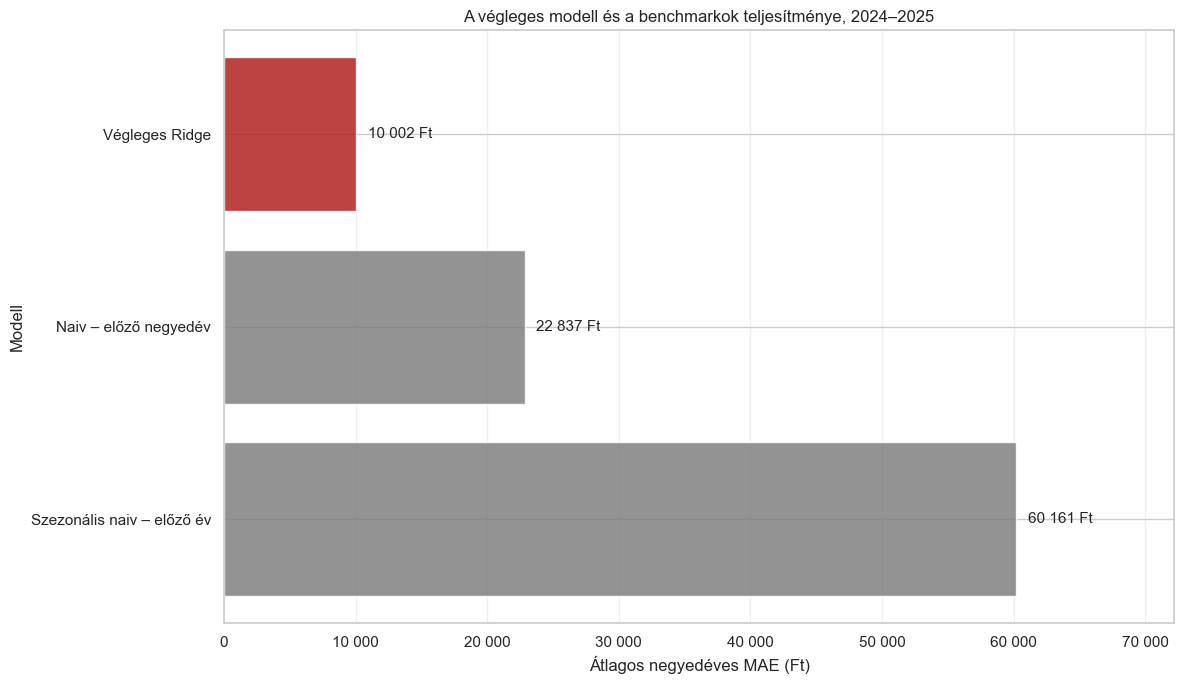

In [197]:
# VÉGSŐ TESZT MAE-ÖSSZEHASONLÍTÁSA

final_model_plot_data = (
    final_test_summary
    .sort_values(
        "Átlag_MAE",
        ascending=False
    )
    .copy()
)


final_bar_colors = [
    (
        "firebrick"

        if model_name
        ==
        "Végleges Ridge"

        else "grey"
    )

    for model_name
    in final_model_plot_data[
        "Modell"
    ]
]


fig, ax = plt.subplots(
    figsize=(12, 7)
)


bars = ax.barh(
    final_model_plot_data["Modell"],
    final_model_plot_data["Átlag_MAE"],
    color=final_bar_colors,
    alpha=0.85
)


maximum_final_mae = (
    final_model_plot_data[
        "Átlag_MAE"
    ].max()
)


for bar, mae_value in zip(
    bars,
    final_model_plot_data["Átlag_MAE"]
):

    ax.text(
        mae_value
        +
        maximum_final_mae * 0.015,
        bar.get_y()
        +
        bar.get_height() / 2,
        (
            f"{mae_value:,.0f} Ft"
            .replace(",", " ")
        ),
        va="center",
        fontsize=11
    )


ax.set_xlim(
    0,
    maximum_final_mae * 1.20
)

ax.xaxis.set_major_formatter(
    FuncFormatter(
        huf_axis_formatter
    )
)

ax.set_xlabel(
    "Átlagos negyedéves MAE (Ft)"
)

ax.set_ylabel(
    "Modell"
)

ax.set_title(
    "A végleges modell és a benchmarkok teljesítménye, 2024–2025"
)

ax.grid(
    axis="x",
    alpha=0.3
)


plt.tight_layout()


fig.savefig(
    ML_FIGURES
    / "final_test_model_comparison_mae.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

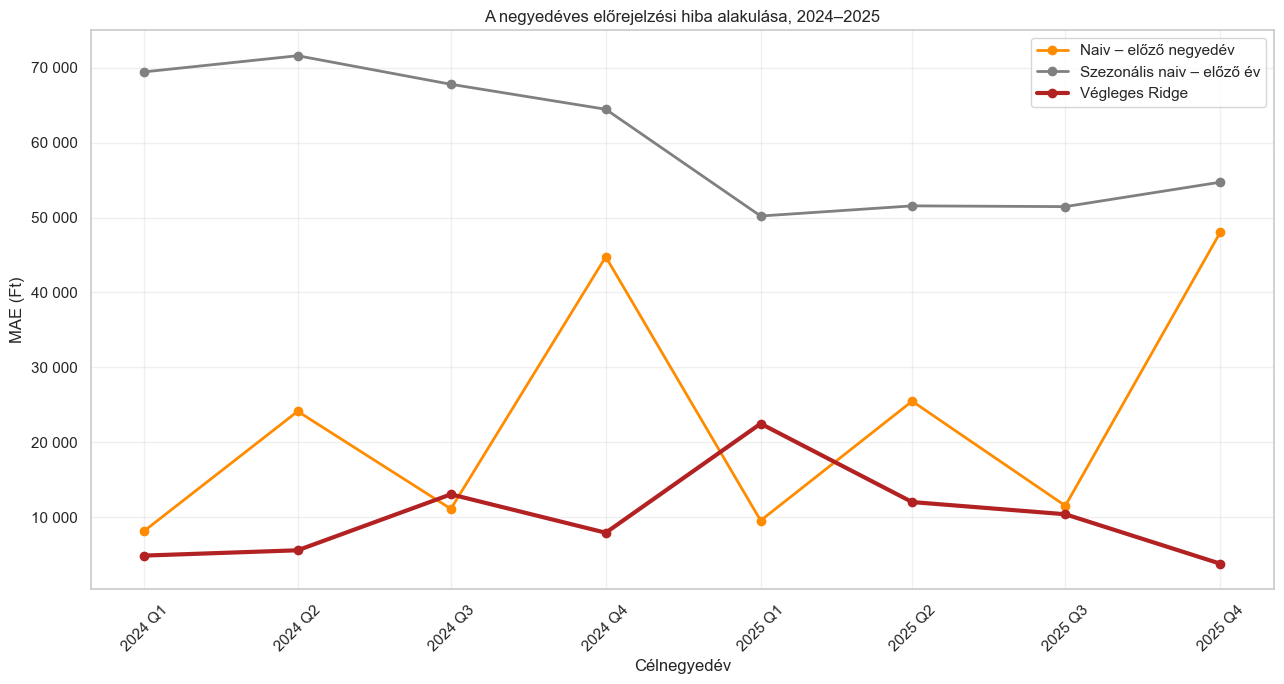

In [198]:
# NEGYEDÉVES ELŐREJELZÉSI HIBA MODELLENKÉNT

fig, ax = plt.subplots(
    figsize=(13, 7)
)


model_styles = {
    "Végleges Ridge": {
        "color": "firebrick",
        "linewidth": 3,
        "marker": "o"
    },

    "Naiv – előző negyedév": {
        "color": "darkorange",
        "linewidth": 2,
        "marker": "o"
    },

    "Szezonális naiv – előző év": {
        "color": "grey",
        "linewidth": 2,
        "marker": "o"
    }
}


for model_name, model_metrics in (
    final_test_quarterly_metrics
    .groupby("Modell")
):

    model_metrics = (
        model_metrics
        .sort_values("Cél_Dátum")
    )


    style = model_styles[
        model_name
    ]


    ax.plot(
        model_metrics["Cél_Dátum"],
        model_metrics["MAE"],
        label=model_name,
        color=style["color"],
        linewidth=style["linewidth"],
        marker=style["marker"]
    )


ax.yaxis.set_major_formatter(
    FuncFormatter(
        huf_axis_formatter
    )
)

ax.set_xlabel(
    "Célnegyedév"
)

ax.set_ylabel(
    "MAE (Ft)"
)

ax.set_title(
    "A negyedéves előrejelzési hiba alakulása, 2024–2025"
)

ax.grid(
    alpha=0.3
)

ax.legend()


plt.xticks(
    final_test_target_dates,
    [
        date.to_period("Q").strftime(
            "%Y Q%q"
        )

        for date in final_test_target_dates
    ],
    rotation=45
)


plt.tight_layout()


fig.savefig(
    ML_FIGURES
    / "final_test_quarterly_mae.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [199]:
# VÉGSŐ TESZTEREDMÉNYEK MENTÉSE

final_ridge_predictions.to_csv(
    ML_RESULTS
    / "KSH_final_ridge_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)


final_test_predictions.to_csv(
    ML_RESULTS
    / "KSH_final_test_all_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)


final_test_summary.to_csv(
    ML_RESULTS
    / "KSH_final_test_summary.csv",
    index=False,
    encoding="utf-8-sig"
)


final_test_quarterly_metrics.to_csv(
    ML_RESULTS
    / "KSH_final_test_quarterly_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)


final_benchmark_improvement.to_csv(
    ML_RESULTS
    / "KSH_final_benchmark_improvement.csv",
    index=False,
    encoding="utf-8-sig"
)


development_test_comparison.to_csv(
    ML_RESULTS
    / "KSH_development_final_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)


final_training_audit.to_csv(
    ML_RESULTS
    / "KSH_final_training_window_audit.csv",
    index=False,
    encoding="utf-8-sig"
)


print(
    "A 2024–2025-ös végső teszteredmények elmentve."
)

A 2024–2025-ös végső teszteredmények elmentve.


## Érzékenységvizsgálat a két KSH-bérforrás eltérésére

Az alapmodell tanítóadatai részben az archív, részben az új KSH
kereseti táblából származnak. Annak ellenőrzésére, hogy a végső
eredmények mennyire függnek az archív adatok felhasználásától,
a végleges Ridge-modellt egy szűkített tanítómintán is értékeljük.

Az érzékenységi modell kizárólag olyan sorokon tanul, amelyeknél
az aktuális kereset, a négy kereseti késleltetés, valamint a
negyedéves és éves keresetváltozás is a 2022-től elérhető új
bérforrás adataiból számítható. A négynegyedéves késleltetés miatt
a szűkített minta első információs időpontja 2023 első negyedéve.

A modellcsaládot, a feature-készletet és az alpha=3 paramétert nem
változtatjuk meg. Így az érzékenységvizsgálatban kizárólag a
tanítóadatok időbeli összetétele változik. A tesztidőszak mindkét
esetben ugyanaz a 2024–2025 közötti nyolc célnegyedév.

In [200]:
# CSAK AZ ÚJ KSH-BÉRFORRÁSHOZ KAPCSOLÓDÓ MODELLMINTA

new_wage_source_start = pd.Timestamp(
    "2022-01-01"
)

# A modell négy negyedéves bérkésleltetést is használ.
# Ezért 2023 Q1 az első olyan információs negyedév,
# amelynek valamennyi béradata 2022 Q1-ből vagy későbbről származik.

homogeneous_feature_start = (
    new_wage_source_start
    +
    pd.DateOffset(years=1)
)


df_model_new_wage_source = (
    df_model.loc[
        df_model["Dátum"]
        >=
        homogeneous_feature_start
    ]
    .sort_values(
        [
            "Cél_Dátum",
            "Területi egység neve"
        ]
    )
    .reset_index(drop=True)
    .copy()
)


assert (
    df_model_new_wage_source["Dátum"].min()
    ==
    pd.Timestamp("2023-01-01")
)

assert (
    df_model_new_wage_source["Cél_Dátum"].min()
    ==
    pd.Timestamp("2023-04-01")
)

assert len(
    df_model_new_wage_source
) == 220

assert (
    df_model_new_wage_source
    .groupby("Cél_Dátum")
    .size()
    .eq(20)
    .all()
)

assert set(
    final_test_target_dates
).issubset(
    set(
        df_model_new_wage_source["Cél_Dátum"]
    )
)


print(
    "A kizárólag új bérforráshoz kapcsolódó "
    "modellminta elkészült."
)

print(
    "Megfigyelések száma:",
    len(df_model_new_wage_source)
)

print(
    "Első információs negyedév:",
    df_model_new_wage_source[
        "Dátum"
    ].min().to_period("Q")
)

print(
    "Első célnegyedév:",
    df_model_new_wage_source[
        "Cél_Dátum"
    ].min().to_period("Q")
)

A kizárólag új bérforráshoz kapcsolódó modellminta elkészült.
Megfigyelések száma: 220
Első információs negyedév: 2023Q1
Első célnegyedév: 2023Q2


In [201]:
# ÉRZÉKENYSÉGI RIDGE-MODELL FUTTATÁSA

new_source_model_name = (
    "Érzékenység – csak új bérforrás"
)


new_source_predictions = (
    expanding_window_feature_ablation(
        data=df_model_new_wage_source,
        target_dates=final_test_target_dates,
        estimator=final_ridge_estimator,
        feature_set_name=new_source_model_name,
        numeric_feature_names=(
            final_numeric_features
        ),
        categorical_feature_names=(
            final_categorical_features
        ),
        maximum_allowed_target_date=(
            final_test_end
        )
    )
)


new_source_predictions[
    "Feature_készlet"
] = "Időtrend nélküli"

new_source_predictions[
    "Alpha"
] = final_ridge_alpha


assert len(
    new_source_predictions
) == 160

assert (
    new_source_predictions[
        "Cél_Dátum"
    ].nunique()
    == 8
)


new_source_training_audit = (
    new_source_predictions[
        [
            "Fold",
            "Cél_Dátum",
            "Tanítósorok",
            "Tanítás_utolsó_célnegyedéve"
        ]
    ]
    .drop_duplicates()
    .sort_values("Cél_Dátum")
    .reset_index(drop=True)
)


# Az első, 2024 Q1-es előrejelzés előtt
# 2023 Q2–2023 Q4 három célnegyedéve áll rendelkezésre:
# 3 negyedév × 20 terület = 60 tanítósor.

assert (
    new_source_training_audit
    .iloc[0]["Tanítósorok"]
    == 60
)

assert (
    new_source_training_audit[
        "Tanítósorok"
    ]
    .diff()
    .dropna()
    .eq(20)
    .all()
)


display(
    new_source_training_audit.assign(
        Célnegyedév=(
            new_source_training_audit[
                "Cél_Dátum"
            ]
            .dt
            .to_period("Q")
            .astype(str)
        )
    )[
        [
            "Fold",
            "Célnegyedév",
            "Tanítósorok",
            "Tanítás_utolsó_célnegyedéve"
        ]
    ]
)

C:\Users\wldbe\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,Fold,Célnegyedév,Tanítósorok,Tanítás_utolsó_célnegyedéve
0,1,2024Q1,60,2023-10-01
1,2,2024Q2,80,2024-01-01
2,3,2024Q3,100,2024-04-01
3,4,2024Q4,120,2024-07-01
4,5,2025Q1,140,2024-10-01
5,6,2025Q2,160,2025-01-01
6,7,2025Q3,180,2025-04-01
7,8,2025Q4,200,2025-07-01


In [202]:
# ALAPMODELL ÉS ÉRZÉKENYSÉGI MODELL ÖSSZEHASONLÍTÁSA

baseline_model_name = (
    "Alapmodell – teljes történeti tanítóminta"
)


baseline_predictions_for_sensitivity = (
    final_ridge_predictions.copy()
)

baseline_predictions_for_sensitivity[
    "Modell"
] = baseline_model_name


source_sensitivity_predictions = pd.concat(
    [
        baseline_predictions_for_sensitivity,
        new_source_predictions
    ],
    ignore_index=True
)


(
    source_sensitivity_summary,
    source_sensitivity_quarterly_metrics

) = summarize_prediction_metrics(
    source_sensitivity_predictions
)


baseline_mae = float(
    source_sensitivity_summary.loc[
        source_sensitivity_summary["Modell"]
        ==
        baseline_model_name,
        "Átlag_MAE"
    ].iloc[0]
)


previous_quarter_naive_mae = float(
    final_test_summary.loc[
        final_test_summary["Modell"]
        ==
        "Naiv – előző negyedév",
        "Átlag_MAE"
    ].iloc[0]
)


first_fold_training_rows = {
    baseline_model_name:
        int(
            final_training_audit
            .iloc[0]["Tanítósorok"]
        ),

    new_source_model_name:
        int(
            new_source_training_audit
            .iloc[0]["Tanítósorok"]
        )
}


source_sensitivity_summary[
    "Első_fold_tanítósorok"
] = (
    source_sensitivity_summary[
        "Modell"
    ].map(
        first_fold_training_rows
    )
)


source_sensitivity_summary[
    "MAE_eltérés_alapmodellhez_Ft"
] = (
    source_sensitivity_summary["Átlag_MAE"]
    -
    baseline_mae
)


source_sensitivity_summary[
    "MAE_eltérés_alapmodellhez_%"
] = (
    (
        source_sensitivity_summary["Átlag_MAE"]
        /
        baseline_mae
    )
    -
    1
) * 100


source_sensitivity_summary[
    "Javulás_előző_negyedéves_naivhoz_%"
] = (
    1
    -
    source_sensitivity_summary["Átlag_MAE"]
    /
    previous_quarter_naive_mae
) * 100


display(
    source_sensitivity_summary[
        [
            "Modell",
            "Első_fold_tanítósorok",
            "Átlag_MAE",
            "Összesített_RMSE",
            "MAPE_%",
            "Összesített_R2",
            "MAE_eltérés_alapmodellhez_Ft",
            "MAE_eltérés_alapmodellhez_%",
            "Javulás_előző_negyedéves_naivhoz_%"
        ]
    ]
    .round(3)
)

,Modell,Első_fold_tanítósorok,Átlag_MAE,Összesített_RMSE,MAPE_%,Összesített_R2,MAE_eltérés_alapmodellhez_Ft,MAE_eltérés_alapmodellhez_%,Javulás_előző_negyedéves_naivhoz_%
0,Érzékenység – csak új bérforrás,60,8011.417,10394.638,1.345,0.983,-1990.196,-19.899,64.919
1,Alapmodell – teljes történeti tanítóminta,380,10001.613,13093.291,1.660,0.973,0.000,0.000,56.205


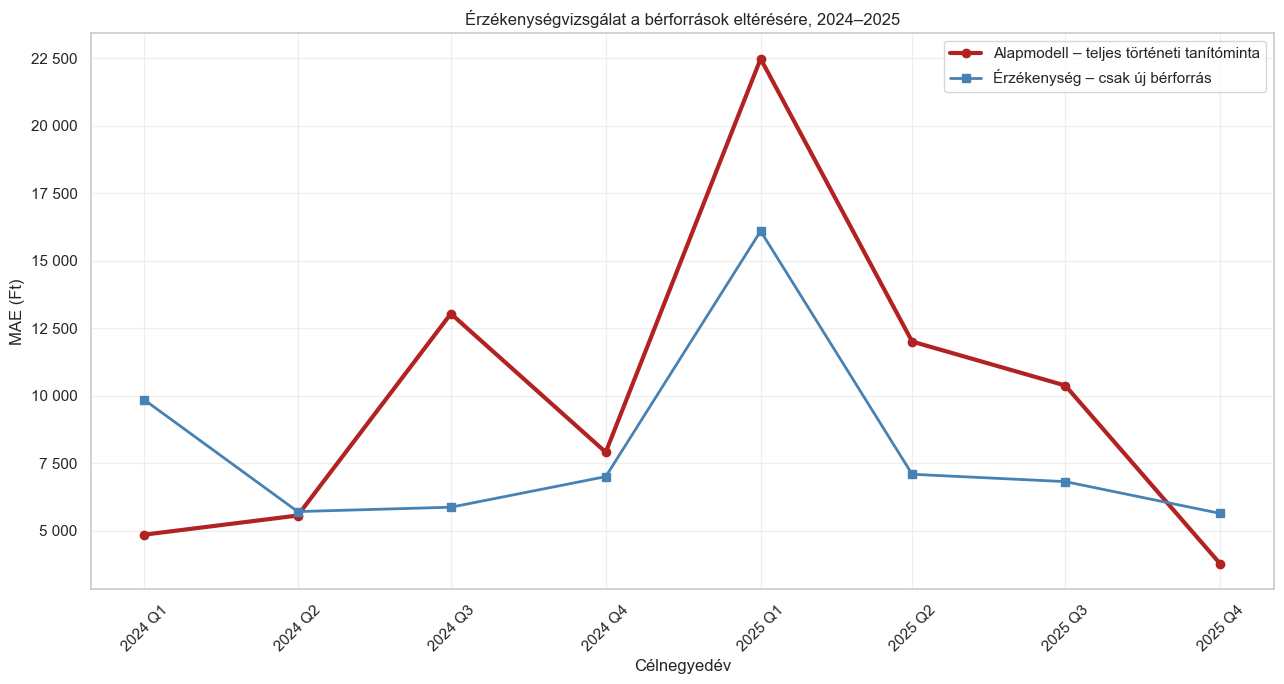

Az érzékenységvizsgálat eredményei elmentve.


In [203]:
# ÉRZÉKENYSÉGVIZSGÁLAT NEGYEDÉVES MAE-ÉRTÉKEI

sensitivity_styles = {
    baseline_model_name: {
        "color": "firebrick",
        "marker": "o",
        "linewidth": 3
    },

    new_source_model_name: {
        "color": "steelblue",
        "marker": "s",
        "linewidth": 2
    }
}


fig, ax = plt.subplots(
    figsize=(13, 7)
)


for model_name, model_metrics in (
    source_sensitivity_quarterly_metrics
    .groupby("Modell")
):

    model_metrics = (
        model_metrics
        .sort_values("Cél_Dátum")
    )

    style = sensitivity_styles[
        model_name
    ]

    ax.plot(
        model_metrics["Cél_Dátum"],
        model_metrics["MAE"],
        label=model_name,
        color=style["color"],
        marker=style["marker"],
        linewidth=style["linewidth"]
    )


ax.yaxis.set_major_formatter(
    FuncFormatter(
        huf_axis_formatter
    )
)

ax.set_xlabel(
    "Célnegyedév"
)

ax.set_ylabel(
    "MAE (Ft)"
)

ax.set_title(
    "Érzékenységvizsgálat a bérforrások eltérésére, 2024–2025"
)

ax.grid(
    alpha=0.3
)

ax.legend()


plt.xticks(
    final_test_target_dates,
    [
        str(
            date.to_period("Q")
        ).replace("Q", " Q")

        for date in final_test_target_dates
    ],
    rotation=45
)


plt.tight_layout()


fig.savefig(
    ML_FIGURES
    / "wage_source_sensitivity_quarterly_mae.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# EREDMÉNYEK MENTÉSE

source_sensitivity_predictions.to_csv(
    ML_RESULTS
    / "KSH_wage_source_sensitivity_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

source_sensitivity_summary.to_csv(
    ML_RESULTS
    / "KSH_wage_source_sensitivity_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

source_sensitivity_quarterly_metrics.to_csv(
    ML_RESULTS
    / "KSH_wage_source_sensitivity_quarterly_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

new_source_training_audit.to_csv(
    ML_RESULTS
    / "KSH_wage_source_sensitivity_training_audit.csv",
    index=False,
    encoding="utf-8-sig"
)


print(
    "Az érzékenységvizsgálat eredményei elmentve."
)

## A végleges modell területi hibáinak elemzése

A végső teszt összesített eredményei után megvizsgáljuk, hogy a modell
pontossága mennyire egyenletes a húsz területi egység között. Területenként
kiszámítjuk az átlagos abszolút hibát, az RMSE-t, a százalékos hibát és az
előrejelzések átlagos irányított eltérését.

A pozitív előjeles hiba felülbecslést, a negatív előjeles hiba alulbecslést
jelent. Az elemzés leíró jellegű: a területi különbségek nem értelmezhetők
oksági hatásként.

In [204]:
# VÉGLEGES RIDGE HIBAADATBÁZISA

final_ridge_error_data = (
    final_ridge_predictions
    .copy()
)


assert (
    final_ridge_error_data[
        "Valós_bér"
    ]
    >
    0
).all()


final_ridge_error_data[
    "Négyzetes_hiba"
] = (
    final_ridge_error_data[
        "Hiba"
    ]
    **
    2
)


final_ridge_error_data[
    "APE_%"
] = (
    final_ridge_error_data[
        "Abszolút_hiba"
    ]
    /
    final_ridge_error_data[
        "Valós_bér"
    ]
    *
    100
)


final_ridge_error_data[
    "Felülbecslés"
] = (
    final_ridge_error_data[
        "Hiba"
    ]
    >
    0
).astype(int)


final_ridge_error_data[
    "Célnegyedév"
] = (
    final_ridge_error_data[
        "Cél_Dátum"
    ]
    .dt
    .to_period("Q")
    .astype(str)
)


assert len(
    final_ridge_error_data
) == 160


assert np.isfinite(
    final_ridge_error_data[
        [
            "Hiba",
            "Abszolút_hiba",
            "Négyzetes_hiba",
            "APE_%"
        ]
    ]
).all().all()

In [205]:
# TERÜLETENKÉNTI ELŐREJELZÉSI METRIKÁK

regional_error_summary = (
    final_ridge_error_data
    .groupby(
        "Területi egység neve",
        as_index=False
    )
    .agg(
        **{
            "Átlagos_valós_bér_Ft": (
                "Valós_bér",
                "mean"
            ),

            "Átlagos_predikció_Ft": (
                "Predikció",
                "mean"
            ),

            "Bias_Ft": (
                "Hiba",
                "mean"
            ),

            "MAE_Ft": (
                "Abszolút_hiba",
                "mean"
            ),

            "Átlagos_négyzetes_hiba": (
                "Négyzetes_hiba",
                "mean"
            ),

            "MAPE_%": (
                "APE_%",
                "mean"
            ),

            "Legnagyobb_abszolút_hiba_Ft": (
                "Abszolút_hiba",
                "max"
            ),

            "Felülbecslések_aránya": (
                "Felülbecslés",
                "mean"
            ),

            "Negyedévek": (
                "Cél_Dátum",
                "nunique"
            )
        }
    )
)


regional_error_summary[
    "RMSE_Ft"
] = np.sqrt(
    regional_error_summary[
        "Átlagos_négyzetes_hiba"
    ]
)


regional_error_summary[
    "Felülbecslések_aránya_%"
] = (
    regional_error_summary[
        "Felülbecslések_aránya"
    ]
    *
    100
)


regional_error_summary[
    "Átlagos_hibairány"
] = np.where(
    regional_error_summary[
        "Bias_Ft"
    ]
    >
    0,
    "Felülbecslés",
    "Alulbecslés"
)


regional_error_summary = (
    regional_error_summary
    .drop(
        columns=[
            "Átlagos_négyzetes_hiba",
            "Felülbecslések_aránya"
        ]
    )
    .sort_values("MAE_Ft")
    .reset_index(drop=True)
)


regional_error_summary[
    "MAE_rangsor"
] = np.arange(
    1,
    len(regional_error_summary) + 1
)


assert len(
    regional_error_summary
) == 20


assert (
    regional_error_summary[
        "Negyedévek"
    ]
    ==
    8
).all()


display(
    regional_error_summary[
        [
            "MAE_rangsor",
            "Területi egység neve",
            "Átlagos_valós_bér_Ft",
            "MAE_Ft",
            "RMSE_Ft",
            "MAPE_%",
            "Bias_Ft",
            "Átlagos_hibairány",
            "Felülbecslések_aránya_%",
            "Legnagyobb_abszolút_hiba_Ft"
        ]
    ]
    .round(2)
)

,MAE_rangsor,Területi egység neve,Átlagos_valós_bér_Ft,MAE_Ft,RMSE_Ft,MAPE_%,Bias_Ft,Átlagos_hibairány,Felülbecslések_aránya_%,Legnagyobb_abszolút_hiba_Ft
0,1,Baranya,579368.0,5693.40,7825.28,0.98,4451.65,Felülbecslés,75.0,19105.49
1,2,Békés,513258.5,6557.07,8776.88,1.30,6557.07,Felülbecslés,100.0,20406.83
2,3,Jász-Nagykun-Szolnok,554305.5,7155.54,8972.46,1.29,6373.62,Felülbecslés,87.5,18434.71
3,4,Szabolcs-Szatmár-Bereg,499500.0,7250.80,8176.08,1.44,4956.43,Felülbecslés,75.0,12811.61
4,5,Somogy,550373.0,8311.60,9932.58,1.50,7972.21,Felülbecslés,87.5,19716.07
5,6,Csongrád-Csanád,586724.0,8453.01,11557.03,1.44,6208.92,Felülbecslés,62.5,25229.91
6,7,Bács-Kiskun,581498.0,8702.32,10977.51,1.49,7227.64,Felülbecslés,75.0,22202.36
7,8,Pest,618499.5,8959.67,9923.03,1.46,7197.65,Felülbecslés,87.5,14863.35
8,9,Hajdú-Bihar,592346.5,9030.58,9722.49,1.54,5118.62,Felülbecslés,75.0,15096.05
9,10,Borsod-Abaúj-Zemplén,547353.5,9118.83,11430.69,1.69,8382.09,Felülbecslés,87.5,23196.19


In [206]:
# ÖT LEGPONTOSABB ÉS ÖT LEGPONTATLANABB TERÜLET

best_regions = (
    regional_error_summary
    .head(5)
    .copy()
)


best_regions[
    "Csoport"
] = "Öt legpontosabb"


worst_regions = (
    regional_error_summary
    .tail(5)
    .sort_values(
        "MAE_Ft",
        ascending=False
    )
    .copy()
)


worst_regions[
    "Csoport"
] = "Öt legpontatlanabb"


regional_extremes = pd.concat(
    [
        best_regions,
        worst_regions
    ],
    ignore_index=True
)


display(
    regional_extremes[
        [
            "Csoport",
            "Területi egység neve",
            "MAE_Ft",
            "RMSE_Ft",
            "MAPE_%",
            "Bias_Ft",
            "Átlagos_hibairány"
        ]
    ]
    .round(2)
)

,Csoport,Területi egység neve,MAE_Ft,RMSE_Ft,MAPE_%,Bias_Ft,Átlagos_hibairány
0,Öt legpontosabb,Baranya,5693.40,7825.28,0.98,4451.65,Felülbecslés
1,Öt legpontosabb,Békés,6557.07,8776.88,1.30,6557.07,Felülbecslés
2,Öt legpontosabb,Jász-Nagykun-Szolnok,7155.54,8972.46,1.29,6373.62,Felülbecslés
3,Öt legpontosabb,Szabolcs-Szatmár-Bereg,7250.80,8176.08,1.44,4956.43,Felülbecslés
4,Öt legpontosabb,Somogy,8311.60,9932.58,1.50,7972.21,Felülbecslés
5,Öt legpontatlanabb,Tolna,18495.37,21164.67,2.92,4102.43,Felülbecslés
6,Öt legpontatlanabb,Győr-Moson-Sopron,18381.42,23454.27,2.65,17815.54,Felülbecslés
7,Öt legpontatlanabb,Komárom-Esztergom,12531.40,15685.79,1.88,11477.46,Felülbecslés
8,Öt legpontatlanabb,Vas,11797.14,14343.36,1.97,9715.04,Felülbecslés
9,Öt legpontatlanabb,Budapest,11558.65,16426.91,1.44,10965.32,Felülbecslés


In [207]:
# A VÉGLEGES RIDGE ÁLTALÁNOS TORZÍTÁSA

overall_bias_summary = pd.DataFrame(
    [
        {
            "Átlagos_hiba_Bias_Ft":
                final_ridge_error_data[
                    "Hiba"
                ].mean(),

            "Medián_hiba_Ft":
                final_ridge_error_data[
                    "Hiba"
                ].median(),

            "Felülbecslések_aránya_%":
                (
                    final_ridge_error_data[
                        "Hiba"
                    ]
                    .gt(0)
                    .mean()
                    *
                    100
                ),

            "Alulbecslések_aránya_%":
                (
                    final_ridge_error_data[
                        "Hiba"
                    ]
                    .lt(0)
                    .mean()
                    *
                    100
                ),

            "Legnagyobb_felülbecslés_Ft":
                final_ridge_error_data[
                    "Hiba"
                ].max(),

            "Legnagyobb_alulbecslés_Ft":
                final_ridge_error_data[
                    "Hiba"
                ].min()
        }
    ]
)


display(
    overall_bias_summary.round(2)
)

,Átlagos_hiba_Bias_Ft,Medián_hiba_Ft,Felülbecslések_aránya_%,Alulbecslések_aránya_%,Legnagyobb_felülbecslés_Ft,Legnagyobb_alulbecslés_Ft
0,8100.99,6844.03,83.12,16.88,45144.32,-30191.52


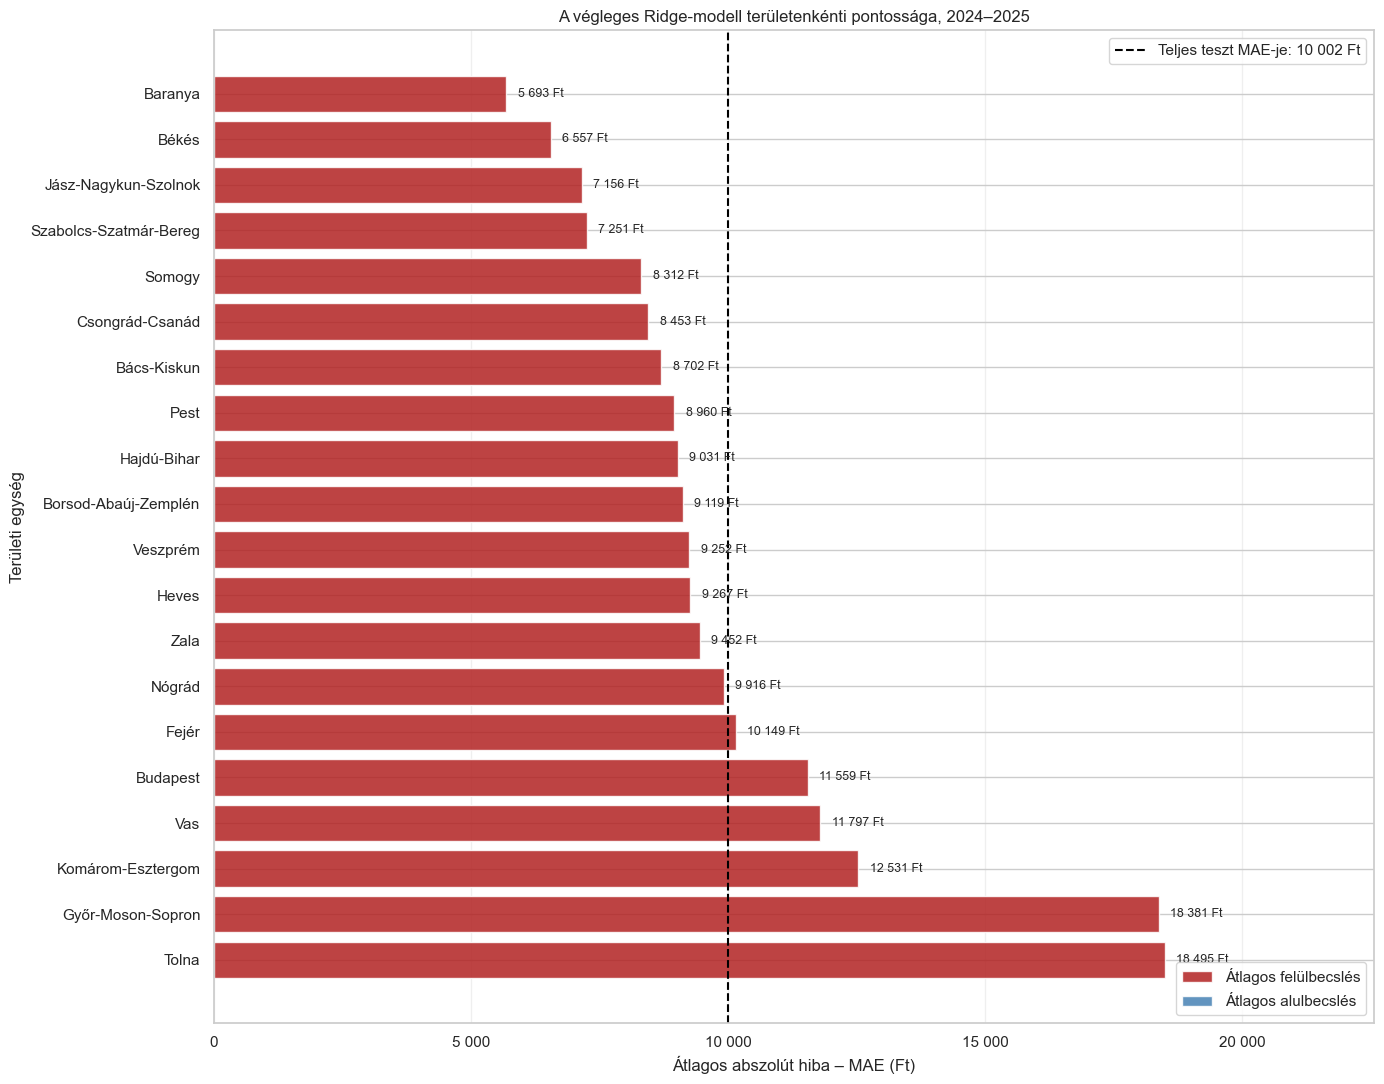

In [208]:
# TERÜLETENKÉNTI MAE ÉS A HIBA IRÁNYA

from matplotlib.patches import Patch


regional_mae_plot = (
    regional_error_summary
    .sort_values(
        "MAE_Ft",
        ascending=False
    )
    .copy()
)


regional_bar_colors = np.where(
    regional_mae_plot[
        "Bias_Ft"
    ]
    >
    0,
    "firebrick",
    "steelblue"
)


fig, ax = plt.subplots(
    figsize=(14, 11)
)


bars = ax.barh(
    regional_mae_plot[
        "Területi egység neve"
    ],
    regional_mae_plot[
        "MAE_Ft"
    ],
    color=regional_bar_colors,
    alpha=0.85
)


maximum_regional_mae = (
    regional_mae_plot[
        "MAE_Ft"
    ].max()
)


for bar, mae_value in zip(
    bars,
    regional_mae_plot[
        "MAE_Ft"
    ]
):

    ax.text(
        mae_value
        +
        maximum_regional_mae * 0.012,
        bar.get_y()
        +
        bar.get_height() / 2,
        (
            f"{mae_value:,.0f} Ft"
            .replace(",", " ")
        ),
        va="center",
        fontsize=9
    )


ax.axvline(
    final_ridge_mae,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=(
        "Teljes teszt MAE-je: "
        +
        f"{final_ridge_mae:,.0f} Ft"
        .replace(",", " ")
    )
)


ax.set_xlim(
    0,
    maximum_regional_mae * 1.22
)

ax.xaxis.set_major_formatter(
    FuncFormatter(
        huf_axis_formatter
    )
)

ax.set_xlabel(
    "Átlagos abszolút hiba – MAE (Ft)"
)

ax.set_ylabel(
    "Területi egység"
)

ax.set_title(
    "A végleges Ridge-modell területenkénti pontossága, 2024–2025"
)


legend_elements = [
    Patch(
        facecolor="firebrick",
        alpha=0.85,
        label="Átlagos felülbecslés"
    ),

    Patch(
        facecolor="steelblue",
        alpha=0.85,
        label="Átlagos alulbecslés"
    )
]


first_legend = ax.legend(
    handles=legend_elements,
    loc="lower right"
)


ax.add_artist(
    first_legend
)


ax.legend(
    loc="upper right"
)

ax.grid(
    axis="x",
    alpha=0.3
)


plt.tight_layout()


fig.savefig(
    ML_FIGURES
    / "final_ridge_regional_mae.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [209]:
# BÉRSZINT ÉS ELŐREJELZÉSI HIBA KAPCSOLATA

wage_error_correlations = pd.DataFrame(
    [
        {
            "Hibamutató":
                "Abszolút hiba (Ft)",

            "Pearson_korreláció":
                final_ridge_error_data[
                    [
                        "Valós_bér",
                        "Abszolút_hiba"
                    ]
                ]
                .corr(
                    method="pearson"
                )
                .iloc[0, 1],

            "Spearman_korreláció":
                final_ridge_error_data[
                    [
                        "Valós_bér",
                        "Abszolút_hiba"
                    ]
                ]
                .corr(
                    method="spearman"
                )
                .iloc[0, 1]
        },

        {
            "Hibamutató":
                "Abszolút százalékos hiba (%)",

            "Pearson_korreláció":
                final_ridge_error_data[
                    [
                        "Valós_bér",
                        "APE_%"
                    ]
                ]
                .corr(
                    method="pearson"
                )
                .iloc[0, 1],

            "Spearman_korreláció":
                final_ridge_error_data[
                    [
                        "Valós_bér",
                        "APE_%"
                    ]
                ]
                .corr(
                    method="spearman"
                )
                .iloc[0, 1]
        }
    ]
)


display(
    wage_error_correlations.round(3)
)

,Hibamutató,Pearson_korreláció,Spearman_korreláció
0,Abszolút hiba (Ft),0.156,0.097
1,Abszolút százalékos hiba (%),0.026,-0.011


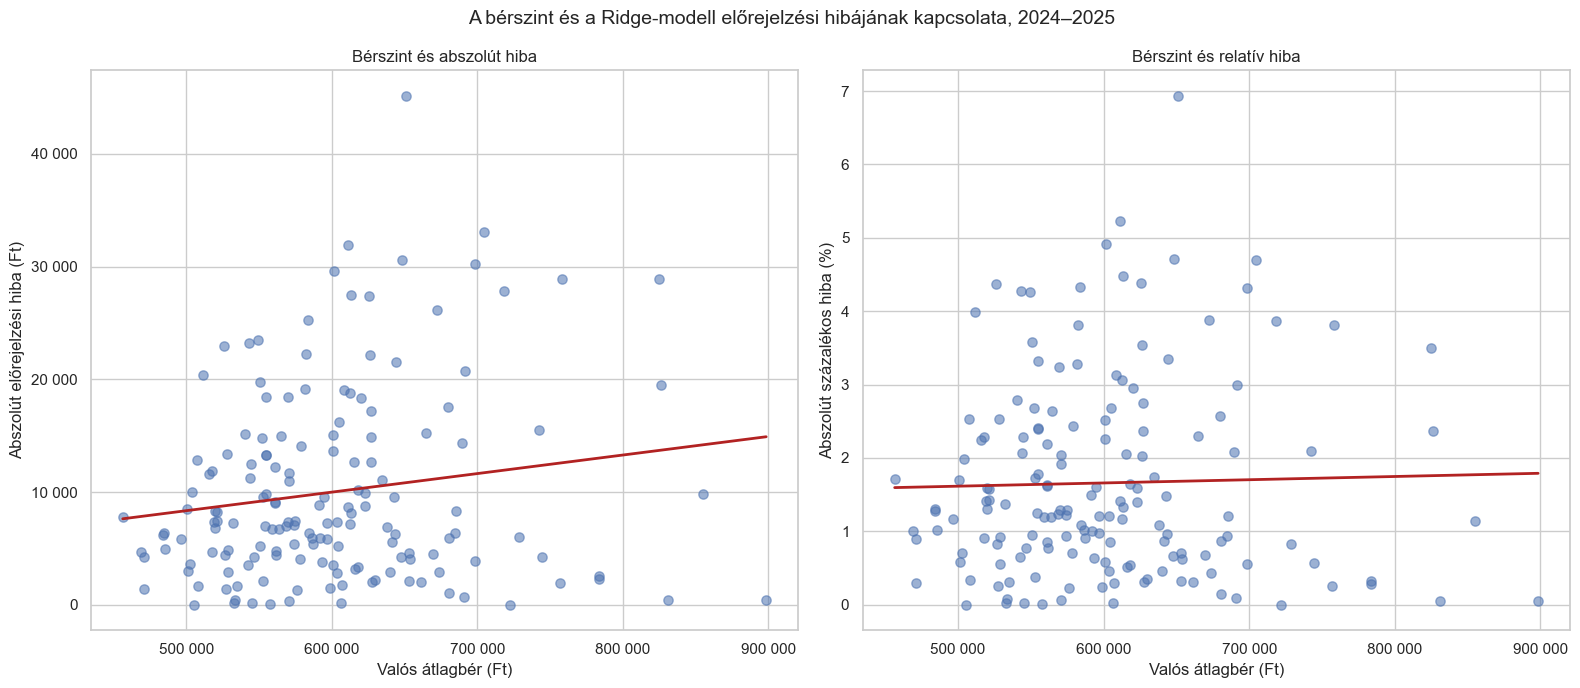

In [210]:
# BÉRSZINT–HIBA KAPCSOLAT VIZUALIZÁCIÓJA

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(16, 7)
)


sns.regplot(
    data=final_ridge_error_data,
    x="Valós_bér",
    y="Abszolút_hiba",
    scatter_kws={
        "alpha": 0.55,
        "s": 45
    },
    line_kws={
        "color": "firebrick",
        "linewidth": 2
    },
    ci=None,
    ax=axes[0]
)


axes[0].xaxis.set_major_formatter(
    FuncFormatter(
        huf_axis_formatter
    )
)

axes[0].yaxis.set_major_formatter(
    FuncFormatter(
        huf_axis_formatter
    )
)

axes[0].set_xlabel(
    "Valós átlagbér (Ft)"
)

axes[0].set_ylabel(
    "Abszolút előrejelzési hiba (Ft)"
)

axes[0].set_title(
    "Bérszint és abszolút hiba"
)


sns.regplot(
    data=final_ridge_error_data,
    x="Valós_bér",
    y="APE_%",
    scatter_kws={
        "alpha": 0.55,
        "s": 45
    },
    line_kws={
        "color": "firebrick",
        "linewidth": 2
    },
    ci=None,
    ax=axes[1]
)


axes[1].xaxis.set_major_formatter(
    FuncFormatter(
        huf_axis_formatter
    )
)

axes[1].set_xlabel(
    "Valós átlagbér (Ft)"
)

axes[1].set_ylabel(
    "Abszolút százalékos hiba (%)"
)

axes[1].set_title(
    "Bérszint és relatív hiba"
)


fig.suptitle(
    "A bérszint és a Ridge-modell előrejelzési hibájának kapcsolata, "
    "2024–2025",
    fontsize=14
)


plt.tight_layout()


fig.savefig(
    ML_FIGURES
    / "final_ridge_wage_error_relationship.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [211]:
# TERÜLETI HIBAELEMZÉS MENTÉSE

final_ridge_error_data.to_csv(
    ML_RESULTS
    / "KSH_final_ridge_error_data.csv",
    index=False,
    encoding="utf-8-sig"
)


regional_error_summary.to_csv(
    ML_RESULTS
    / "KSH_final_ridge_regional_errors.csv",
    index=False,
    encoding="utf-8-sig"
)


regional_extremes.to_csv(
    ML_RESULTS
    / "KSH_final_ridge_regional_extremes.csv",
    index=False,
    encoding="utf-8-sig"
)


overall_bias_summary.to_csv(
    ML_RESULTS
    / "KSH_final_ridge_bias_summary.csv",
    index=False,
    encoding="utf-8-sig"
)


wage_error_correlations.to_csv(
    ML_RESULTS
    / "KSH_wage_error_correlations.csv",
    index=False,
    encoding="utf-8-sig"
)


print(
    "A végleges modell területi hibaelemzése elmentve."
)

A végleges modell területi hibaelemzése elmentve.


## A hibák területi és időbeli szerkezete

A területenkénti összesítés után megvizsgáljuk az előrejelzési hibák
terület–negyedév szerkezetét. A signed error hőtérkép egyszerre mutatja
a hibák nagyságát és irányát.

A pozitív hiba felülbecslést, a negatív hiba alulbecslést jelent.
Emellett azonosítjuk a végső teszt legnagyobb egyedi előrejelzési
hibáit és negyedévenként összesítjük a modell irányított torzítását.

In [212]:
# NEGYEDÉVENKÉNTI IRÁNYÍTOTT HIBA

quarterly_bias_summary = (
    final_ridge_error_data
    .groupby(
        [
            "Cél_Dátum",
            "Célnegyedév"
        ],
        as_index=False
    )
    .agg(
        **{
            "Átlagos_hiba_Bias_Ft": (
                "Hiba",
                "mean"
            ),

            "Medián_hiba_Ft": (
                "Hiba",
                "median"
            ),

            "MAE_Ft": (
                "Abszolút_hiba",
                "mean"
            ),

            "MAPE_%": (
                "APE_%",
                "mean"
            ),

            "Felülbecslések_aránya_%": (
                "Felülbecslés",
                "mean"
            ),

            "Legnagyobb_felülbecslés_Ft": (
                "Hiba",
                "max"
            ),

            "Legnagyobb_alulbecslés_Ft": (
                "Hiba",
                "min"
            ),

            "Területek": (
                "Területi egység neve",
                "nunique"
            )
        }
    )
    .sort_values("Cél_Dátum")
    .reset_index(drop=True)
)


quarterly_bias_summary[
    "Felülbecslések_aránya_%"
] = (
    quarterly_bias_summary[
        "Felülbecslések_aránya_%"
    ]
    *
    100
)


quarterly_bias_summary[
    "Alulbecslések_aránya_%"
] = (
    100
    -
    quarterly_bias_summary[
        "Felülbecslések_aránya_%"
    ]
)


assert len(
    quarterly_bias_summary
) == 8


assert (
    quarterly_bias_summary[
        "Területek"
    ]
    ==
    20
).all()


display(
    quarterly_bias_summary[
        [
            "Célnegyedév",
            "Átlagos_hiba_Bias_Ft",
            "Medián_hiba_Ft",
            "MAE_Ft",
            "MAPE_%",
            "Felülbecslések_aránya_%",
            "Alulbecslések_aránya_%",
            "Legnagyobb_felülbecslés_Ft",
            "Legnagyobb_alulbecslés_Ft"
        ]
    ]
    .round(2)
)

,Célnegyedév,Átlagos_hiba_Bias_Ft,Medián_hiba_Ft,MAE_Ft,MAPE_%,Felülbecslések_aránya_%,Alulbecslések_aránya_%,Legnagyobb_felülbecslés_Ft,Legnagyobb_alulbecslés_Ft
0,2024Q1,894.32,889.76,4858.37,0.90,55.0,45.0,13313.20,-11272.82
1,2024Q2,827.60,2159.80,5565.84,0.95,55.0,45.0,14378.77,-27380.25
2,2024Q3,13039.14,9706.74,13039.14,2.21,100.0,0.0,45144.32,4240.12
3,2024Q4,7909.51,6999.10,7909.51,1.36,100.0,0.0,17211.14,426.01
4,2025Q1,22477.78,22592.85,22477.78,3.76,100.0,0.0,31948.44,12811.61
5,2025Q2,8987.13,10388.52,12006.28,1.92,95.0,5.0,20705.49,-30191.52
6,2025Q3,10378.21,8121.11,10378.21,1.59,100.0,0.0,33075.54,412.21
7,2025Q4,294.21,236.73,3777.77,0.59,60.0,40.0,7360.02,-8328.40


In [213]:
# A VÉGSŐ TESZT LEGNAGYOBB EGYEDI HIBÁI

largest_individual_errors = (
    final_ridge_error_data
    .sort_values(
        "Abszolút_hiba",
        ascending=False
    )
    .head(15)
    .copy()
)


largest_individual_errors[
    "Hiba_iránya"
] = np.select(
    [
        largest_individual_errors[
            "Hiba"
        ]
        >
        0,

        largest_individual_errors[
            "Hiba"
        ]
        <
        0
    ],

    [
        "Felülbecslés",
        "Alulbecslés"
    ],

    default="Pontos előrejelzés"
)


largest_individual_errors[
    "Hiba_rangsor"
] = np.arange(
    1,
    len(largest_individual_errors) + 1
)


display(
    largest_individual_errors[
        [
            "Hiba_rangsor",
            "Célnegyedév",
            "Területi egység neve",
            "Valós_bér",
            "Predikció",
            "Hiba",
            "Abszolút_hiba",
            "APE_%",
            "Hiba_iránya"
        ]
    ]
    .round(2)
)

,Hiba_rangsor,Célnegyedév,Területi egység neve,Valós_bér,Predikció,Hiba,Abszolút_hiba,APE_%,Hiba_iránya
47,1,2024Q3,Győr-Moson-Sopron,650971.0,696115.32,45144.32,45144.32,6.93,Felülbecslés
127,2,2025Q3,Győr-Moson-Sopron,704602.0,737677.54,33075.54,33075.54,4.69,Felülbecslés
96,3,2025Q1,Tolna,611451.0,643399.44,31948.44,31948.44,5.23,Felülbecslés
86,4,2025Q1,Fejér,648237.0,678788.64,30551.64,30551.64,4.71,Felülbecslés
116,5,2025Q2,Tolna,698469.0,668277.48,-30191.52,30191.52,4.32,Alulbecslés
97,6,2025Q1,Vas,601854.0,631436.11,29582.11,29582.11,4.92,Felülbecslés
42,7,2024Q3,Budapest,758294.0,787216.31,28922.31,28922.31,3.81,Felülbecslés
122,8,2025Q3,Budapest,824819.0,853703.50,28884.50,28884.50,3.50,Felülbecslés
87,9,2025Q1,Győr-Moson-Sopron,718331.0,746118.27,27787.27,27787.27,3.87,Felülbecslés
89,10,2025Q1,Heves,613324.0,640828.67,27504.67,27504.67,4.48,Felülbecslés


In [214]:
# SIGNED ERROR MÁTRIX

region_heatmap_order = (
    regional_error_summary
    .sort_values(
        "MAE_Ft",
        ascending=False
    )[
        "Területi egység neve"
    ]
    .tolist()
)


quarter_heatmap_order = [
    str(
        target_date.to_period("Q")
    )

    for target_date
    in final_test_target_dates
]


signed_error_matrix = (
    final_ridge_error_data
    .pivot(
        index="Területi egység neve",
        columns="Célnegyedév",
        values="Hiba"
    )
    .reindex(
        index=region_heatmap_order,
        columns=quarter_heatmap_order
    )
)


assert signed_error_matrix.shape == (
    20,
    8
)


assert not (
    signed_error_matrix
    .isna()
    .any()
    .any()
)


signed_error_matrix_thousand = (
    signed_error_matrix
    /
    1000
)


display(
    signed_error_matrix_thousand.round(1)
)

Célnegyedév,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4
Területi egység neve,,,,,,,,
Tolna,7.0,-27.4,8.8,17.2,31.9,-30.2,21.5,3.9
Győr-Moson-Sopron,2.9,14.4,45.1,6.0,27.8,15.5,33.1,-2.3
Komárom-Esztergom,3.3,5.5,22.2,0.7,26.1,20.7,17.5,-4.2
Vas,13.3,6.0,18.4,2.0,29.6,6.9,9.9,-8.3
Budapest,-2.0,2.5,28.9,0.4,19.5,9.8,28.9,-0.4
Fejér,3.5,2.2,18.8,4.5,30.6,6.4,15.3,0.0
Nógrád,-4.9,-3.6,8.5,13.4,23.0,15.1,3.5,7.4
Zala,-0.0,7.4,8.3,6.7,23.4,14.9,6.7,-8.2
Heves,12.3,-1.5,5.9,12.7,27.5,2.1,6.2,5.9


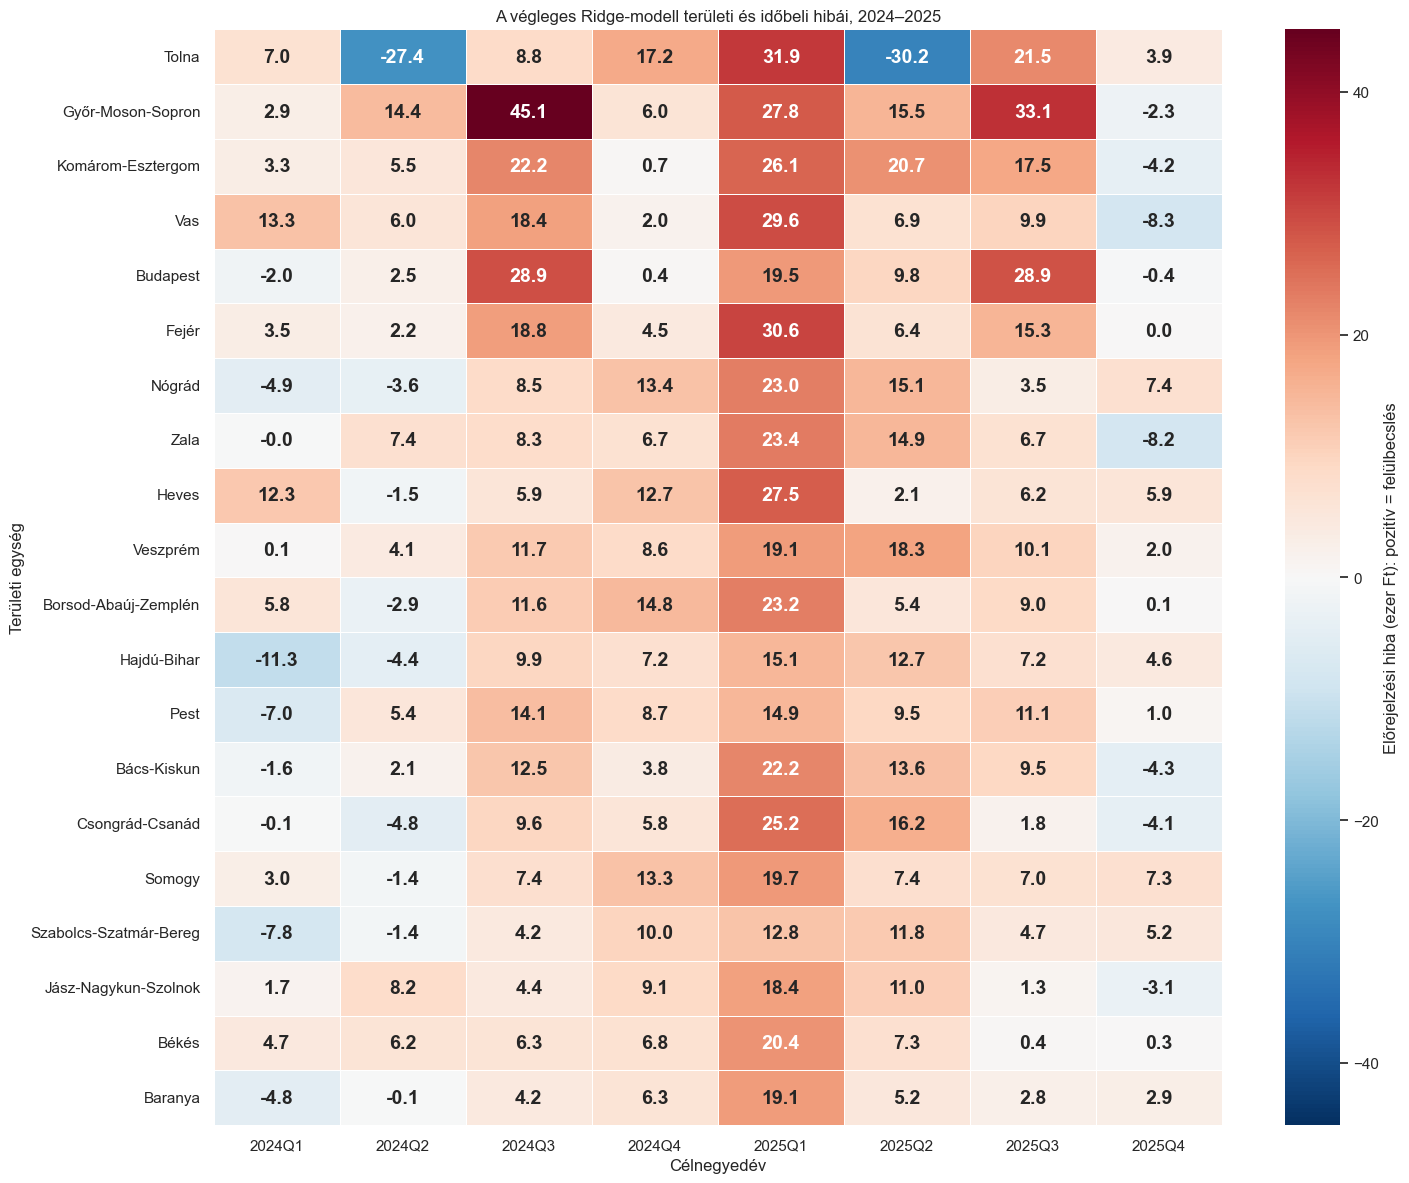

In [215]:
# TERÜLET–NEGYEDÉV HIBAHŐTÉRKÉP

maximum_absolute_heatmap_error = (
    np.abs(
        signed_error_matrix_thousand
        .to_numpy()
    )
    .max()
)


fig, ax = plt.subplots(
    figsize=(15, 12)
)


sns.heatmap(
    signed_error_matrix_thousand,
    cmap="RdBu_r",
    center=0,
    vmin=-maximum_absolute_heatmap_error,
    vmax=maximum_absolute_heatmap_error,
    annot=True,
    fmt=".1f",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": (
            "Előrejelzési hiba (ezer Ft): "
            "pozitív = felülbecslés"
        )
    },
    annot_kws={"size": 14, "weight": "bold"},
    ax=ax
)


ax.set_xlabel(
    "Célnegyedév"
)

ax.set_ylabel(
    "Területi egység"
)

ax.set_title(
    "A végleges Ridge-modell területi és időbeli hibái, 2024–2025"
)


plt.tight_layout()


fig.savefig(
    ML_FIGURES
    / "final_ridge_region_quarter_error_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

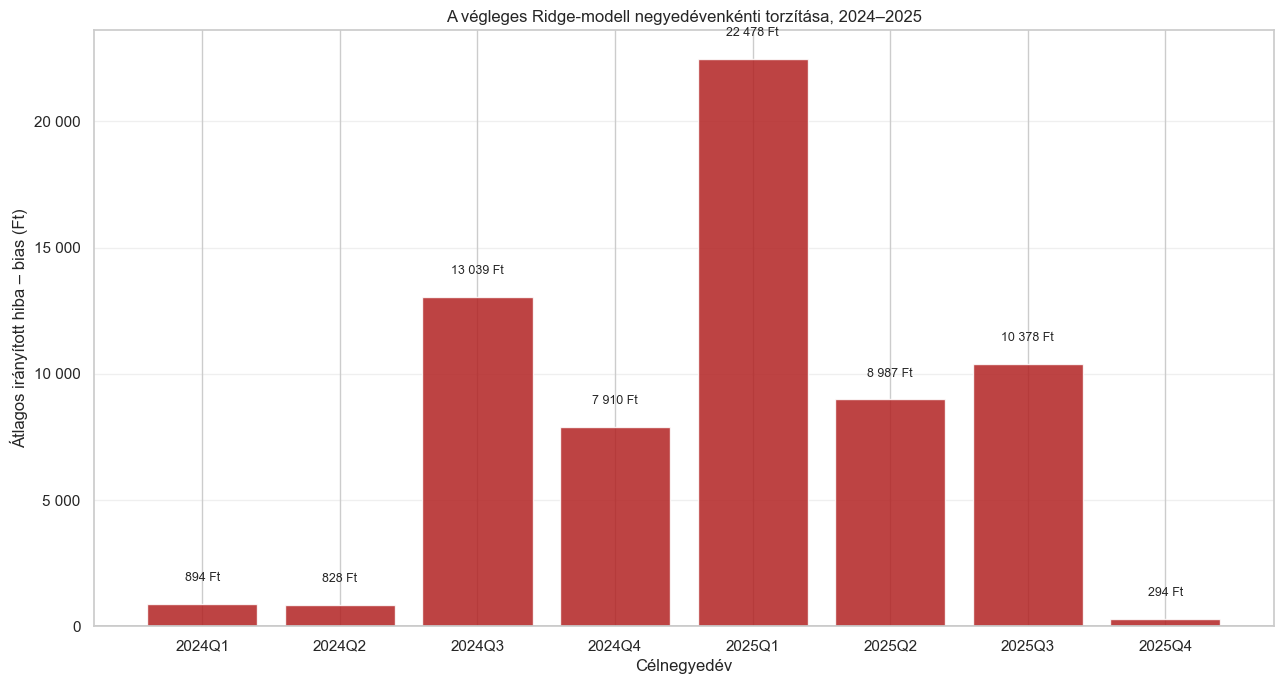

In [216]:
# NEGYEDÉVENKÉNTI FELÜL- ÉS ALULBECSLÉS

quarterly_bias_colors = np.where(
    quarterly_bias_summary[
        "Átlagos_hiba_Bias_Ft"
    ]
    >
    0,
    "firebrick",
    "steelblue"
)


fig, ax = plt.subplots(
    figsize=(13, 7)
)


bars = ax.bar(
    quarterly_bias_summary[
        "Célnegyedév"
    ],
    quarterly_bias_summary[
        "Átlagos_hiba_Bias_Ft"
    ],
    color=quarterly_bias_colors,
    alpha=0.85
)


maximum_absolute_quarterly_bias = (
    quarterly_bias_summary[
        "Átlagos_hiba_Bias_Ft"
    ]
    .abs()
    .max()
)


label_offset = (
    maximum_absolute_quarterly_bias
    *
    0.035
)


for bar, bias_value in zip(
    bars,
    quarterly_bias_summary[
        "Átlagos_hiba_Bias_Ft"
    ]
):

    ax.text(
        bar.get_x()
        +
        bar.get_width() / 2,

        (
            bias_value
            +
            label_offset

            if bias_value >= 0

            else bias_value
            -
            label_offset
        ),

        (
            f"{bias_value:,.0f} Ft"
            .replace(",", " ")
        ),

        ha="center",

        va=(
            "bottom"
            if bias_value >= 0
            else "top"
        ),

        fontsize=9
    )


ax.axhline(
    0,
    color="black",
    linewidth=1
)

ax.yaxis.set_major_formatter(
    FuncFormatter(
        huf_axis_formatter
    )
)

ax.set_xlabel(
    "Célnegyedév"
)

ax.set_ylabel(
    "Átlagos irányított hiba – bias (Ft)"
)

ax.set_title(
    "A végleges Ridge-modell negyedévenkénti torzítása, 2024–2025"
)

ax.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()


fig.savefig(
    ML_FIGURES
    / "final_ridge_quarterly_bias.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [217]:
# TERÜLETI ÉS IDŐBELI HIBÁK MENTÉSE

quarterly_bias_summary.to_csv(
    ML_RESULTS
    / "KSH_final_ridge_quarterly_bias.csv",
    index=False,
    encoding="utf-8-sig"
)


largest_individual_errors.to_csv(
    ML_RESULTS
    / "KSH_final_ridge_largest_errors.csv",
    index=False,
    encoding="utf-8-sig"
)


signed_error_matrix.to_csv(
    ML_RESULTS
    / "KSH_final_ridge_region_quarter_error_matrix.csv",
    encoding="utf-8-sig"
)


print(
    "A területi és időbeli hibaelemzés eredményei elmentve."
)

A területi és időbeli hibaelemzés eredményei elmentve.


## A végleges Ridge-modell együtthatóinak értelmezése

A modell értelmezéséhez a nyolc végső walk-forward fold során ténylegesen
illesztett Ridge-modellek együtthatóit vizsgáljuk. Ez lehetővé teszi nemcsak
az együtthatók átlagos nagyságának, hanem időbeli stabilitásának értékelését is.

A numerikus változók a pipeline-ban standardizálva szerepelnek. A kategorikus
változók one-hot kódolást kapnak, és egy elhagyott referenciakategóriához
viszonyítva értelmezhetők. Az összehasonlíthatóság érdekében minden transzformált
feature esetében kiszámítjuk az egy szórásnyi változáshoz tartozó becsült hatást.

Az eredmények prediktív összefüggéseket mutatnak, és nem értelmezhetők
oksági hatásokként. A korreláló bér- és munkanélküliségi változók miatt
az egyedi együtthatókat különösen óvatosan kell értelmezni.

In [218]:
# TRANSZFORMÁLT FEATURE-EK CSOPORTOSÍTÁSA

def determine_feature_group(
    transformed_feature_name
):

    if transformed_feature_name in wage_features:

        return "Bérdinamika"


    if transformed_feature_name in labour_market_features:

        return "Munkaerőpiac"


    if transformed_feature_name.startswith(
        "Területi egység neve_"
    ):

        return "Területi kategória"


    if transformed_feature_name.startswith(
        "Negyedév_kategória_"
    ):

        return "Negyedéves szezonalitás"


    return "Egyéb"

In [219]:
# A NYOLC VÉGSŐ FOLD EGYÜTTHATÓI

fold_coefficient_frames = []
categorical_baseline_rows = []


for fold_number, target_date in enumerate(
    sorted(final_test_target_dates),
    start=1
):

    train_data = (
        df_model[
            df_model[
                "Cél_Dátum"
            ]
            <
            target_date
        ]
        .copy()
    )


    test_data = (
        df_model[
            df_model[
                "Cél_Dátum"
            ]
            ==
            target_date
        ]
        .sort_values(
            "Területi egység neve"
        )
        .copy()
    )


    fold_pipeline = (
        create_feature_set_pipeline(
            estimator=final_ridge_estimator,
            numeric_feature_names=(
                final_numeric_features
            ),
            categorical_feature_names=(
                final_categorical_features
            )
        )
    )


    fold_pipeline.fit(
        train_data[
            final_all_features
        ],
        train_data[
            target_column
        ]
    )


    # Ellenőrzés: ugyanazokat az előrejelzéseket kell kapnunk,
    # mint a végső teszt során.

    reproduced_predictions = (
        fold_pipeline.predict(
            test_data[
                final_all_features
            ]
        )
    )


    reference_predictions = (
        final_ridge_predictions[
            final_ridge_predictions[
                "Fold"
            ]
            ==
            fold_number
        ]
        .sort_values(
            "Területi egység neve"
        )[
            "Predikció"
        ]
        .to_numpy()
    )


    assert np.allclose(
        reproduced_predictions,
        reference_predictions,
        rtol=1e-10,
        atol=1e-6
    )


    fitted_preprocessor = (
        fold_pipeline
        .named_steps[
            "preprocessor"
        ]
    )


    fitted_model = (
        fold_pipeline
        .named_steps[
            "model"
        ]
    )


    transformed_feature_names = (
        fitted_preprocessor
        .get_feature_names_out()
    )


    raw_coefficients = np.ravel(
        fitted_model.coef_
    )


    transformed_training_data = (
        fitted_preprocessor.transform(
            train_data[
                final_all_features
            ]
        )
    )


    if hasattr(
        transformed_training_data,
        "toarray"
    ):

        transformed_training_data = (
            transformed_training_data
            .toarray()
        )

    else:

        transformed_training_data = np.asarray(
            transformed_training_data
        )


    transformed_feature_std = (
        transformed_training_data.std(
            axis=0,
            ddof=0
        )
    )


    assert len(
        transformed_feature_names
    ) == len(
        raw_coefficients
    )


    assert len(
        raw_coefficients
    ) == len(
        transformed_feature_std
    )


    assert (
        transformed_feature_std
        >
        0
    ).all()


    fold_coefficient_data = pd.DataFrame(
        {
            "Fold":
                fold_number,

            "Cél_Dátum":
                target_date,

            "Célnegyedév":
                str(
                    target_date.to_period("Q")
                ),

            "Feature":
                transformed_feature_names,

            "Nyers_koefficiens_Ft":
                raw_coefficients,

            "Transzformált_feature_szórás":
                transformed_feature_std,

            "Hatás_1SD_Ft":
                (
                    raw_coefficients
                    *
                    transformed_feature_std
                )
        }
    )


    fold_coefficient_data[
        "Feature_csoport"
    ] = (
        fold_coefficient_data[
            "Feature"
        ]
        .map(
            determine_feature_group
        )
    )


    fold_coefficient_frames.append(
        fold_coefficient_data
    )


    fitted_onehot_encoder = (
        fitted_preprocessor
        .named_transformers_[
            "categorical"
        ]
        .named_steps[
            "onehot"
        ]
    )


    for (
        original_feature,
        categories,
        dropped_index

    ) in zip(
        final_categorical_features,
        fitted_onehot_encoder.categories_,
        fitted_onehot_encoder.drop_idx_
    ):

        categorical_baseline_rows.append(
            {
                "Fold":
                    fold_number,

                "Célnegyedév":
                    str(
                        target_date.to_period("Q")
                    ),

                "Kategorikus_feature":
                    original_feature,

                "Referenciakategória":
                    categories[
                        int(dropped_index)
                    ]
            }
        )


fold_coefficients = pd.concat(
    fold_coefficient_frames,
    ignore_index=True
)


categorical_baselines_by_fold = pd.DataFrame(
    categorical_baseline_rows
)


print(
    "Foldonkénti együtthatósorok:",
    len(fold_coefficients)
)

print(
    "Transzformált feature-ök száma:",
    fold_coefficients[
        "Feature"
    ].nunique()
)

Foldonkénti együtthatósorok: 272
Transzformált feature-ök száma: 34


In [220]:
# KATEGORIKUS REFERENCIAKATEGÓRIÁK

categorical_baselines = (
    categorical_baselines_by_fold[
        [
            "Kategorikus_feature",
            "Referenciakategória"
        ]
    ]
    .drop_duplicates()
    .sort_values(
        "Kategorikus_feature"
    )
    .reset_index(drop=True)
)


assert (
    categorical_baselines_by_fold
    .groupby(
        "Kategorikus_feature"
    )[
        "Referenciakategória"
    ]
    .nunique()
    .eq(1)
    .all()
)


display(
    categorical_baselines
)

,Kategorikus_feature,Referenciakategória
0,Negyedév_kategória,Q1
1,Területi egység neve,Baranya


In [221]:
# FOLDONKÉNTI EGYÜTTHATÓK ÖSSZESÍTÉSE

coefficient_summary = (
    fold_coefficients
    .groupby(
        [
            "Feature",
            "Feature_csoport"
        ],
        as_index=False
    )
    .agg(
        Átlagos_nyers_koefficiens_Ft=(
            "Nyers_koefficiens_Ft",
            "mean"
        ),

        Nyers_koefficiens_szórás_Ft=(
            "Nyers_koefficiens_Ft",
            "std"
        ),

        Átlagos_hatás_1SD_Ft=(
            "Hatás_1SD_Ft",
            "mean"
        ),

        Hatás_1SD_szórás_Ft=(
            "Hatás_1SD_Ft",
            "std"
        ),

        Minimum_hatás_1SD_Ft=(
            "Hatás_1SD_Ft",
            "min"
        ),

        Maximum_hatás_1SD_Ft=(
            "Hatás_1SD_Ft",
            "max"
        ),

        Pozitív_foldok=(
            "Nyers_koefficiens_Ft",
            lambda values: (
                values
                >
                0
            ).sum()
        ),

        Negatív_foldok=(
            "Nyers_koefficiens_Ft",
            lambda values: (
                values
                <
                0
            ).sum()
        ),

        Foldok=(
            "Fold",
            "nunique"
        )
    )
)


coefficient_summary[
    "Abszolút_átlagos_hatás_1SD_Ft"
] = (
    coefficient_summary[
        "Átlagos_hatás_1SD_Ft"
    ]
    .abs()
)


coefficient_summary[
    "Előjel_stabilitás"
] = np.select(
    [
        coefficient_summary[
            "Pozitív_foldok"
        ]
        ==
        coefficient_summary[
            "Foldok"
        ],

        coefficient_summary[
            "Negatív_foldok"
        ]
        ==
        coefficient_summary[
            "Foldok"
        ]
    ],

    [
        "Mindig pozitív",
        "Mindig negatív"
    ],

    default="Változó előjel"
)


coefficient_summary = (
    coefficient_summary
    .sort_values(
        "Abszolút_átlagos_hatás_1SD_Ft",
        ascending=False
    )
    .reset_index(drop=True)
)


coefficient_summary[
    "Hatás_rangsor"
] = np.arange(
    1,
    len(coefficient_summary) + 1
)


assert (
    coefficient_summary[
        "Foldok"
    ]
    ==
    8
).all()


display(
    coefficient_summary[
        [
            "Hatás_rangsor",
            "Feature",
            "Feature_csoport",
            "Átlagos_hatás_1SD_Ft",
            "Hatás_1SD_szórás_Ft",
            "Minimum_hatás_1SD_Ft",
            "Maximum_hatás_1SD_Ft",
            "Előjel_stabilitás"
        ]
    ]
    .head(20)
    .round(2)
)

,Hatás_rangsor,Feature,Feature_csoport,Átlagos_hatás_1SD_Ft,Hatás_1SD_szórás_Ft,Minimum_hatás_1SD_Ft,Maximum_hatás_1SD_Ft,Előjel_stabilitás
0,1,Bér_Lag3,Bérdinamika,39203.79,4870.04,31865.68,45932.16,Mindig pozitív
1,2,Bér_Lag1,Bérdinamika,21432.63,4221.39,16939.06,27649.84,Mindig pozitív
2,3,Bruttó_átlagkereset_HUF,Bérdinamika,16012.23,2283.37,13357.94,19776.60,Mindig pozitív
3,4,Bér_Lag4,Bérdinamika,14769.58,1345.30,12357.28,17142.17,Mindig pozitív
4,5,Bér_Lag2,Bérdinamika,9814.71,1008.94,7968.92,11454.22,Mindig pozitív
5,6,Negyedév_kategória_Q2,Negyedéves szezonalitás,-4520.96,234.04,-4877.10,-4245.97,Mindig negatív
6,7,Bér_Növekedés_YoY,Bérdinamika,3822.85,907.39,2861.57,5322.32,Mindig pozitív
7,8,Negyedév_kategória_Q3,Negyedéves szezonalitás,2947.54,197.86,2611.60,3258.16,Mindig pozitív
8,9,Álláskeresők_1000_foglalkoztatottra,Munkaerőpiac,-2223.70,743.29,-3094.83,-1236.02,Mindig negatív
9,10,Területi egység neve_Budapest,Területi kategória,-1553.46,817.91,-2417.93,-393.33,Mindig negatív


In [222]:
# FEATURE-CSOPORTOK STANDARDIZÁLT HATÁSA

coefficient_group_summary = (
    coefficient_summary
    .groupby(
        "Feature_csoport",
        as_index=False
    )
    .agg(
        Feature_szám=(
            "Feature",
            "nunique"
        ),

        Összesített_abszolút_hatás_1SD_Ft=(
            "Abszolút_átlagos_hatás_1SD_Ft",
            "sum"
        ),

        Átlagos_abszolút_hatás_1SD_Ft=(
            "Abszolút_átlagos_hatás_1SD_Ft",
            "mean"
        ),

        Legnagyobb_abszolút_hatás_1SD_Ft=(
            "Abszolút_átlagos_hatás_1SD_Ft",
            "max"
        ),

        Stabil_előjelű_feature_ök=(
            "Előjel_stabilitás",
            lambda values: (
                values
                !=
                "Változó előjel"
            ).sum()
        )
    )
    .sort_values(
        "Átlagos_abszolút_hatás_1SD_Ft",
        ascending=False
    )
    .reset_index(drop=True)
)


display(
    coefficient_group_summary.round(2)
)

,Feature_csoport,Feature_szám,Összesített_abszolút_hatás_1SD_Ft,Átlagos_abszolút_hatás_1SD_Ft,Legnagyobb_abszolút_hatás_1SD_Ft,Stabil_előjelű_feature_ök
0,Bérdinamika,7,106257.76,15179.68,39203.79,7
1,Negyedéves szezonalitás,3,7714.84,2571.61,4520.96,2
2,Munkaerőpiac,5,4116.91,823.38,2223.70,3
3,Területi kategória,19,7383.94,388.63,1553.46,13


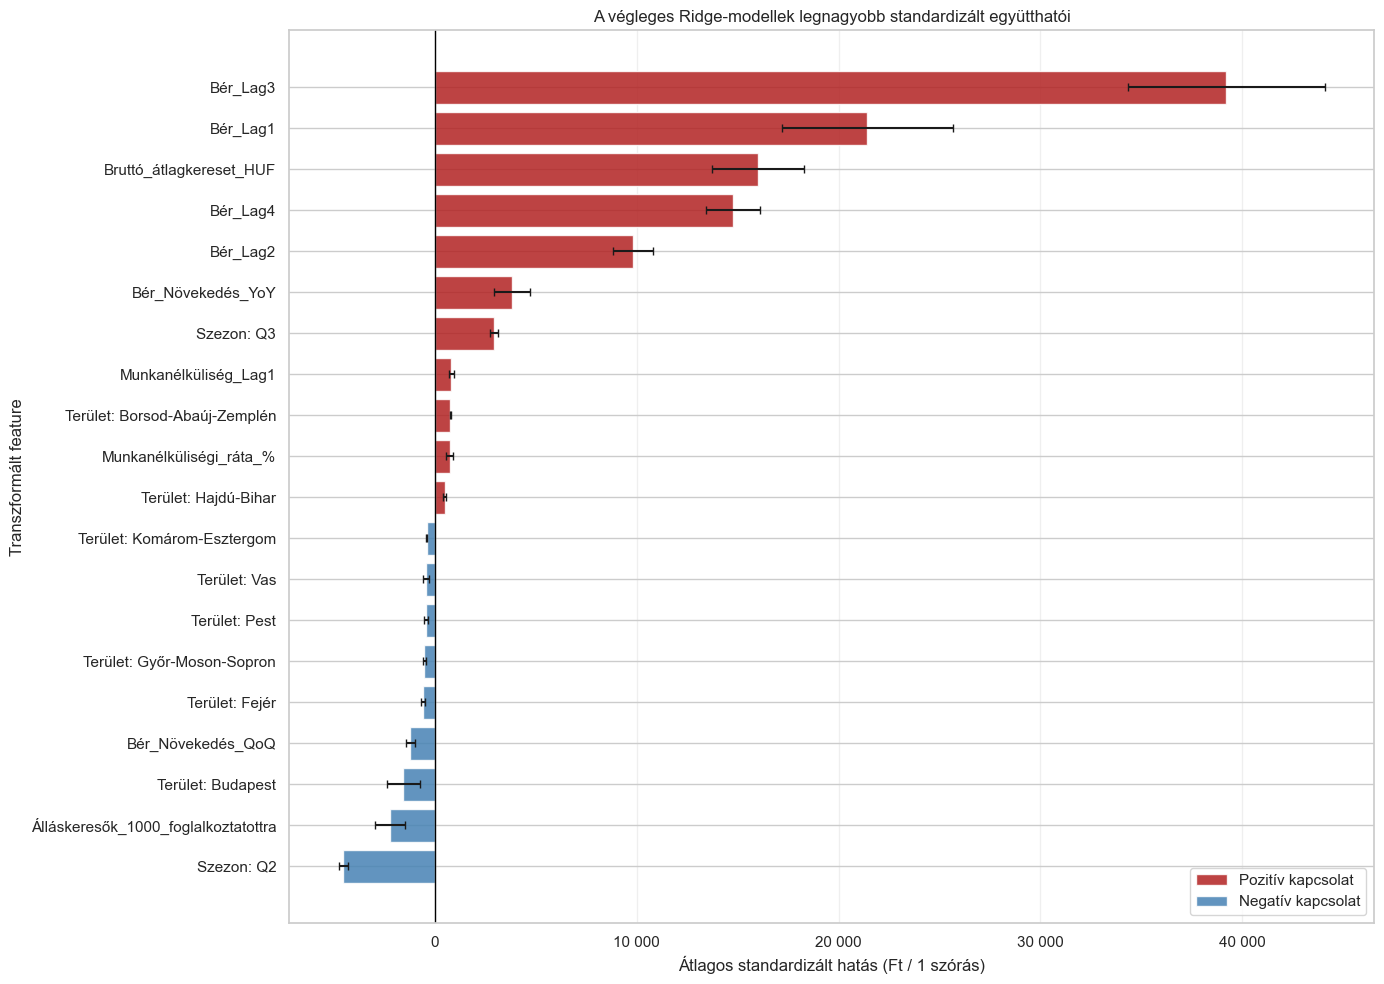

In [223]:
# LEGNAGYOBB STANDARDIZÁLT HATÁSÚ FEATURE-ÖK

top_coefficient_plot = (
    coefficient_summary
    .head(20)
    .sort_values(
        "Átlagos_hatás_1SD_Ft"
    )
    .copy()
)


top_coefficient_plot[
    "Feature_megjelenítés"
] = (
    top_coefficient_plot[
        "Feature"
    ]
    .str.replace(
        "Területi egység neve_",
        "Terület: ",
        regex=False
    )
    .str.replace(
        "Negyedév_kategória_",
        "Szezon: ",
        regex=False
    )
)


coefficient_colors = np.where(
    top_coefficient_plot[
        "Átlagos_hatás_1SD_Ft"
    ]
    >
    0,
    "firebrick",
    "steelblue"
)


fig, ax = plt.subplots(
    figsize=(14, 10)
)


ax.barh(
    top_coefficient_plot[
        "Feature_megjelenítés"
    ],
    top_coefficient_plot[
        "Átlagos_hatás_1SD_Ft"
    ],
    xerr=top_coefficient_plot[
        "Hatás_1SD_szórás_Ft"
    ],
    color=coefficient_colors,
    alpha=0.85,
    capsize=3
)


ax.axvline(
    0,
    color="black",
    linewidth=1
)

ax.xaxis.set_major_formatter(
    FuncFormatter(
        huf_axis_formatter
    )
)

ax.set_xlabel(
    "Átlagos standardizált hatás (Ft / 1 szórás)"
)

ax.set_ylabel(
    "Transzformált feature"
)

ax.set_title(
    "A végleges Ridge-modellek legnagyobb standardizált együtthatói"
)

ax.grid(
    axis="x",
    alpha=0.3
)


legend_elements = [
    Patch(
        facecolor="firebrick",
        alpha=0.85,
        label="Pozitív kapcsolat"
    ),

    Patch(
        facecolor="steelblue",
        alpha=0.85,
        label="Negatív kapcsolat"
    )
]


ax.legend(
    handles=legend_elements,
    loc="lower right"
)


plt.tight_layout()


fig.savefig(
    ML_FIGURES
    / "final_ridge_standardized_coefficients.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [224]:
# RIDGE-EGYÜTTHATÓK MENTÉSE

fold_coefficients.to_csv(
    ML_RESULTS
    / "KSH_final_ridge_fold_coefficients.csv",
    index=False,
    encoding="utf-8-sig"
)


coefficient_summary.to_csv(
    ML_RESULTS
    / "KSH_final_ridge_coefficient_summary.csv",
    index=False,
    encoding="utf-8-sig"
)


coefficient_group_summary.to_csv(
    ML_RESULTS
    / "KSH_final_ridge_coefficient_group_summary.csv",
    index=False,
    encoding="utf-8-sig"
)


categorical_baselines_by_fold.to_csv(
    ML_RESULTS
    / "KSH_final_ridge_categorical_baselines_by_fold.csv",
    index=False,
    encoding="utf-8-sig"
)


categorical_baselines.to_csv(
    ML_RESULTS
    / "KSH_final_ridge_categorical_baselines.csv",
    index=False,
    encoding="utf-8-sig"
)


print(
    "A végleges Ridge-modellek együtthatói elmentve."
)

A végleges Ridge-modellek együtthatói elmentve.


## Összefoglalás

A vizsgálat célja a magyarországi területi bruttó átlagkeresetek egy
negyedévvel előre történő becslése volt. Az elemzés húsz területi egység
2018–2025 közötti negyedéves paneladatain alapult.

Az időbeli adatszivárgás elkerülése érdekében expanding-window walk-forward
értékelést alkalmaztunk. A 2021–2023-as időszak szolgált a modellek
fejlesztésére, összehasonlítására és hangolására, míg a 2024–2025-ös
időszak érintetlen végső tesztként szerepelt.

A vizsgált regressziós modellcsaládok közül az átlagos negyedéves MAE alapján
a Ridge-regresszió bizonyult a legjobbnak. A feature-ablation alapján a
determinisztikus időtrend elhagyása mérsékelten javította a teljesítményt,
ezért a végleges modell 14 feature-t és alpha=3 regularizációs paramétert
használt.

A végleges teszten a Ridge-modell 10 002 Ft átlagos abszolút hibát,
1,66%-os MAPE-értéket és 0,966-os átlagos negyedéves R²-értéket ért el.
A modell MAE-je 56,2%-kal volt alacsonyabb az előző negyedéves naiv,
és 83,4%-kal a szezonális naiv benchmark eredményénél.

A hibaelemzés alapján a modell átlagosan 8 101 Ft-tal felülbecsülte a
béreket, és a becslések 83,1%-a pozitív irányú hibát mutatott. A legnagyobb
általános torzítás 2025 első negyedévében jelentkezett. Területi szinten
Baranyában volt a legalacsonyabb, Tolnában pedig a legmagasabb MAE.

A standardizált együtthatók és az ablatív vizsgálat egyaránt azt mutatták,
hogy az előrejelzésben a korábbi bérértékek és a bérdinamikai változók
dominálnak. A munkaerőpiaci, szezonális és területi változók kisebb, de
kiegészítő prediktív információt biztosítottak.

Az eredmények prediktív, nem pedig oksági összefüggéseket mutatnak.
A következtetéseket korlátozza a viszonylag rövid negyedéves idősor,
a nyolc negyedévből álló végső tesztidőszak, valamint az, hogy a bérek
nominális értéken szerepelnek.

In [225]:
# A 3. NOTEBOOK VÉGSŐ AUDITJA

final_ridge_result = (
    final_test_summary.loc[
        final_test_summary["Modell"]
        ==
        "Végleges Ridge"
    ]
    .iloc[0]
)


previous_quarter_result = (
    final_test_summary.loc[
        final_test_summary["Modell"]
        ==
        "Naiv – előző negyedév"
    ]
    .iloc[0]
)


seasonal_naive_result = (
    final_test_summary.loc[
        final_test_summary["Modell"]
        ==
        "Szezonális naiv – előző év"
    ]
    .iloc[0]
)


best_region_result = (
    regional_error_summary.iloc[0]
)


worst_region_result = (
    regional_error_summary.iloc[-1]
)


top_feature_result = (
    coefficient_summary.iloc[0]
)


assert final_ridge_alpha == 3.0
assert len(final_all_features) == 14
assert "Időtrend_negyedév" not in final_all_features

assert len(final_ridge_predictions) == 160
assert len(final_test_target_dates) == 8
assert final_ridge_predictions["Fold"].nunique() == 8

assert fold_coefficients["Fold"].nunique() == 8
assert coefficient_summary["Feature"].nunique() == 34

assert (
    final_ridge_result["Átlag_MAE"]
    <
    previous_quarter_result["Átlag_MAE"]
)

assert (
    final_ridge_result["Átlag_MAE"]
    <
    seasonal_naive_result["Átlag_MAE"]
)


notebook_3_final_summary = pd.DataFrame(
    [
        {
            "Mutató": "Végleges modell",
            "Érték": "Ridge-regresszió"
        },
        {
            "Mutató": "Ridge alpha",
            "Érték": final_ridge_alpha
        },
        {
            "Mutató": "Feature-ek száma",
            "Érték": len(final_all_features)
        },
        {
            "Mutató": "Végső teszt MAE (Ft)",
            "Érték": final_ridge_result["Átlag_MAE"]
        },
        {
            "Mutató": "Végső teszt RMSE (Ft)",
            "Érték": final_ridge_result["Összesített_RMSE"]
        },
        {
            "Mutató": "Végső teszt MAPE (%)",
            "Érték": final_ridge_result["MAPE_%"]
        },
        {
            "Mutató": "Átlagos negyedéves R²",
            "Érték": final_ridge_result["Átlag_R2"]
        },
        {
            "Mutató": "Átlagos bias (Ft)",
            "Érték": overall_bias_summary.iloc[0][
                "Átlagos_hiba_Bias_Ft"
            ]
        },
        {
            "Mutató": "Legpontosabb terület",
            "Érték": best_region_result[
                "Területi egység neve"
            ]
        },
        {
            "Mutató": "Legpontosabb terület MAE (Ft)",
            "Érték": best_region_result["MAE_Ft"]
        },
        {
            "Mutató": "Legpontatlanabb terület",
            "Érték": worst_region_result[
                "Területi egység neve"
            ]
        },
        {
            "Mutató": "Legpontatlanabb terület MAE (Ft)",
            "Érték": worst_region_result["MAE_Ft"]
        },
        {
            "Mutató": "Legnagyobb standardizált hatású feature",
            "Érték": top_feature_result["Feature"]
        },
        {
            "Mutató": "Legnagyobb standardizált hatás (Ft/1 SD)",
            "Érték": top_feature_result[
                "Átlagos_hatás_1SD_Ft"
            ]
        }
    ]
)


display(
    notebook_3_final_summary
)


notebook_3_final_summary.to_csv(
    ML_RESULTS
    / "KSH_notebook_3_final_summary.csv",
    index=False,
    encoding="utf-8-sig"
)


print(
    "A 3. notebook minden ellenőrzést teljesített és lezárható."
)

,Mutató,Érték
0,Végleges modell,Ridge-regresszió
1,Ridge alpha,3.0
2,Feature-ek száma,14
3,Végső teszt MAE (Ft),10001.612931
4,Végső teszt RMSE (Ft),13093.291147
5,Végső teszt MAPE (%),1.659945
6,Átlagos negyedéves R²,0.965772
7,Átlagos bias (Ft),8100.987466
8,Legpontosabb terület,Baranya
9,Legpontosabb terület MAE (Ft),5693.401257


A 3. notebook minden ellenőrzést teljesített és lezárható.


In [226]:
pd.set_option("display.max_colwidth", None)

display(
    best_candidate_by_family[
        ["Modellcsalád", "Paraméterek"]
    ]
)

,Modellcsalád,Paraméterek
0,Elastic Net,"alpha=0.1, l1_ratio=0.9"
1,Lasso,alpha=100.0
2,Lineáris regresszió,alapbeállítás
3,Gradient Boosting,"learning_rate=0.05, max_depth=3, n_estimators=200"
4,Random Forest,"max_depth=None, max_features=0.7, min_samples_leaf=2"


## Expanding Window vs. Sliding Window összehasonlítás

A szakirodalom alapján, ha az idősor szerkezeti töréseket tartalmaz (pl. felgyorsuló bérdinamika), a túl régi adatok ronthatják a modell teljesítményét. Ebben a részben a végleges (időtrend nélküli) Ridge modellt értékeljük ki *sliding window* (rögzített ablakméretű) validációval. Különböző ablakméreteket (4, 8 és 10 negyedév) hasonlítunk össze az eddig használt *expanding window* (bővülő) eljárással a 2021–2023-as fejlesztési időszakon.

In [227]:
# SLIDING WINDOW WALK-FORWARD FÜGGVÉNY DEFINIÁLÁSA

def sliding_window_walk_forward(
    data,
    target_dates,
    estimator,
    model_name,
    window_size_quarters,
    numeric_feature_names,
    categorical_feature_names,
    maximum_allowed_target_date
):
    selected_features = list(numeric_feature_names) + list(categorical_feature_names)
    prediction_frames = []

    for fold_number, target_date in enumerate(sorted(target_dates), start=1):
        
        # Elérhető múltbeli dátumok kigyűjtése
        available_past_dates = sorted(data[data["Cél_Dátum"] < target_date]["Cél_Dátum"].unique())
        
        # Sliding window kezdődátumának meghatározása
        if len(available_past_dates) > window_size_quarters:
            start_date = available_past_dates[-window_size_quarters]
        else:
            start_date = available_past_dates[0]
            
        train_mask = (data["Cél_Dátum"] >= start_date) & (data["Cél_Dátum"] < target_date)
        test_mask = (data["Cél_Dátum"] == target_date)

        train_data = data.loc[train_mask].copy()
        test_data = data.loc[test_mask].copy()

        X_train = train_data[selected_features]
        y_train = train_data[target_column]
        X_test = test_data[selected_features]

        fold_pipeline = create_feature_set_pipeline(
            estimator=estimator,
            numeric_feature_names=numeric_feature_names,
            categorical_feature_names=categorical_feature_names
        )

        fold_pipeline.fit(X_train, y_train)
        fold_predictions = fold_pipeline.predict(X_test)

        fold_result = test_data[["Dátum", "Cél_Dátum", "Területi egység neve"]].copy()

        fold_result["Modell"] = model_name
        fold_result["Fold"] = fold_number
        fold_result["Tanítósorok"] = len(train_data)
        fold_result["Tanítás_utolsó_célnegyedéve"] = train_data["Cél_Dátum"].max()
        fold_result["Valós_bér"] = test_data[target_column].to_numpy()
        fold_result["Predikció"] = fold_predictions
        fold_result["Hiba"] = fold_result["Predikció"] - fold_result["Valós_bér"]
        fold_result["Abszolút_hiba"] = fold_result["Hiba"].abs()

        prediction_frames.append(fold_result)

    predictions = pd.concat(prediction_frames, ignore_index=True)
    return predictions

In [228]:
# SLIDING WINDOW KÍSÉRLETEK FUTTATÁSA ÉS ÖSSZEHASONLÍTÁSA

window_sizes = {
    "Sliding Window (4 negyedév)": 4,
    "Sliding Window (8 negyedév)": 8,
    "Sliding Window (10 negyedév)": 10
}

sliding_prediction_frames = []

# Végleges Ridge modell a legjobb alfával
ridge_estimator = Ridge(alpha=final_ridge_alpha)

for model_name, window_size in window_sizes.items():
    print(f"Futtatás: {model_name}")
    
    sliding_preds = sliding_window_walk_forward(
        data=df_model,
        target_dates=development_target_dates,
        estimator=ridge_estimator,
        model_name=model_name,
        window_size_quarters=window_size,
        numeric_feature_names=no_trend_numeric_features,
        categorical_feature_names=no_trend_categorical_features,
        maximum_allowed_target_date=development_end
    )
    sliding_prediction_frames.append(sliding_preds)

sliding_predictions_df = pd.concat(sliding_prediction_frames, ignore_index=True)

(
    sliding_summary,
    sliding_quarterly_metrics
) = summarize_prediction_metrics(sliding_predictions_df)

# Bővülő ablak (Expanding Window) korábbi eredményének beemelése az összehasonlításhoz
expanding_result = final_feature_comparison.loc[
    final_feature_comparison["Modell"] == "Időtrend nélküli modell"
].copy()
expanding_result["Modell"] = "Expanding Window (Bővülő ablak)"

# Oszlopok egységesítése az összefűzéshez
sliding_summary_display = sliding_summary[
    ["Modell", "Átlag_MAE", "Átlag_RMSE", "Átlag_R2"]
].copy()
expanding_display = expanding_result[
    ["Modell", "Átlag_MAE", "Átlag_RMSE", "Átlag_R2"]
].copy()

window_comparison = pd.concat(
    [expanding_display, sliding_summary_display], ignore_index=True
).sort_values("Átlag_MAE").reset_index(drop=True)

print("\n=== EXPANDING VS SLIDING WINDOW ÖSSZEHASONLÍTÁS (Ridge alpha=3.0) ===")
display(window_comparison.round(3))

Futtatás: Sliding Window (4 negyedév)
Futtatás: Sliding Window (8 negyedév)
Futtatás: Sliding Window (10 negyedév)

=== EXPANDING VS SLIDING WINDOW ÖSSZEHASONLÍTÁS (Ridge alpha=3.0) ===


,Modell,Átlag_MAE,Átlag_RMSE,Átlag_R2
0,Expanding Window (Bővülő ablak),8939.824,10769.685,0.948
1,Sliding Window (10 negyedév),9015.390,10810.807,0.948
2,Sliding Window (8 negyedév),9395.678,11009.820,0.946
3,Sliding Window (4 negyedév),10535.162,12337.698,0.936
